# Objectif 

Inversion des positions à l'aide de la portion 4. L'objectif est d'obtenir l'incertitude la plus faible. 

Date de création : 19/10/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *

# Préliminaires

## Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [3]:
portion_id = 4
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_dat...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 2313, mmsi: 521,
│   │                                   ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:5...
│   │         * mmsi                   (mmsi) int64 4kB 4 127 128 129 396 ... 431 125 32 244
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:50...
│   │         * src_datetime           (src_datetime) datetime64[ns] 6kB 2026-02-25T09:50...
│   │       Data variables: (12/17)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           rcv_lon_apriori        (rcv_id) float64 56B ...
│   │           rcv_lat_apriori        (rcv_id) float64 56B ...
│   │           rcv_immersion_apriori  (rcv_id) int16 14B ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 6kB ...
│   │           tir_src_lon            (src_datetime) float64 6kB ...
│   │           tir_src_lat            (src_datetime) float64 6kB ...
│   │           tir_vessel_lon         (src_datetime) float64 6kB ...
│   │           tir_vessel_lat         (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 2120, mmsi: 521,
│   │                                   ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:1...
│   │         * mmsi                   (mmsi) int64 4kB 4 127 128 129 396 ... 431 125 32 244
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:10...
│   │         * src_datetime           (src_datetime) datetime64[ns] 6kB 2026-02-25T11:10...
│   │       Data variables: (12/17)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           rcv_lon_apriori        (rcv_id) float64 56B ...
│   │           rcv_lat_apriori        (rcv_id) float64 56B ...
│   │           rcv_immersion_apriori  (rcv_id) int16 14B ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 6kB ...
│   │           tir_src_lon            (src_datetime) float64 6kB ...
│   │           tir_src_lat            (src_datetime) float64 6kB ...
│   │           tir_vessel_lon         (src_datetime) float64 6kB ...
│   │           tir_vessel_lat         (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 45kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           secti

## Position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

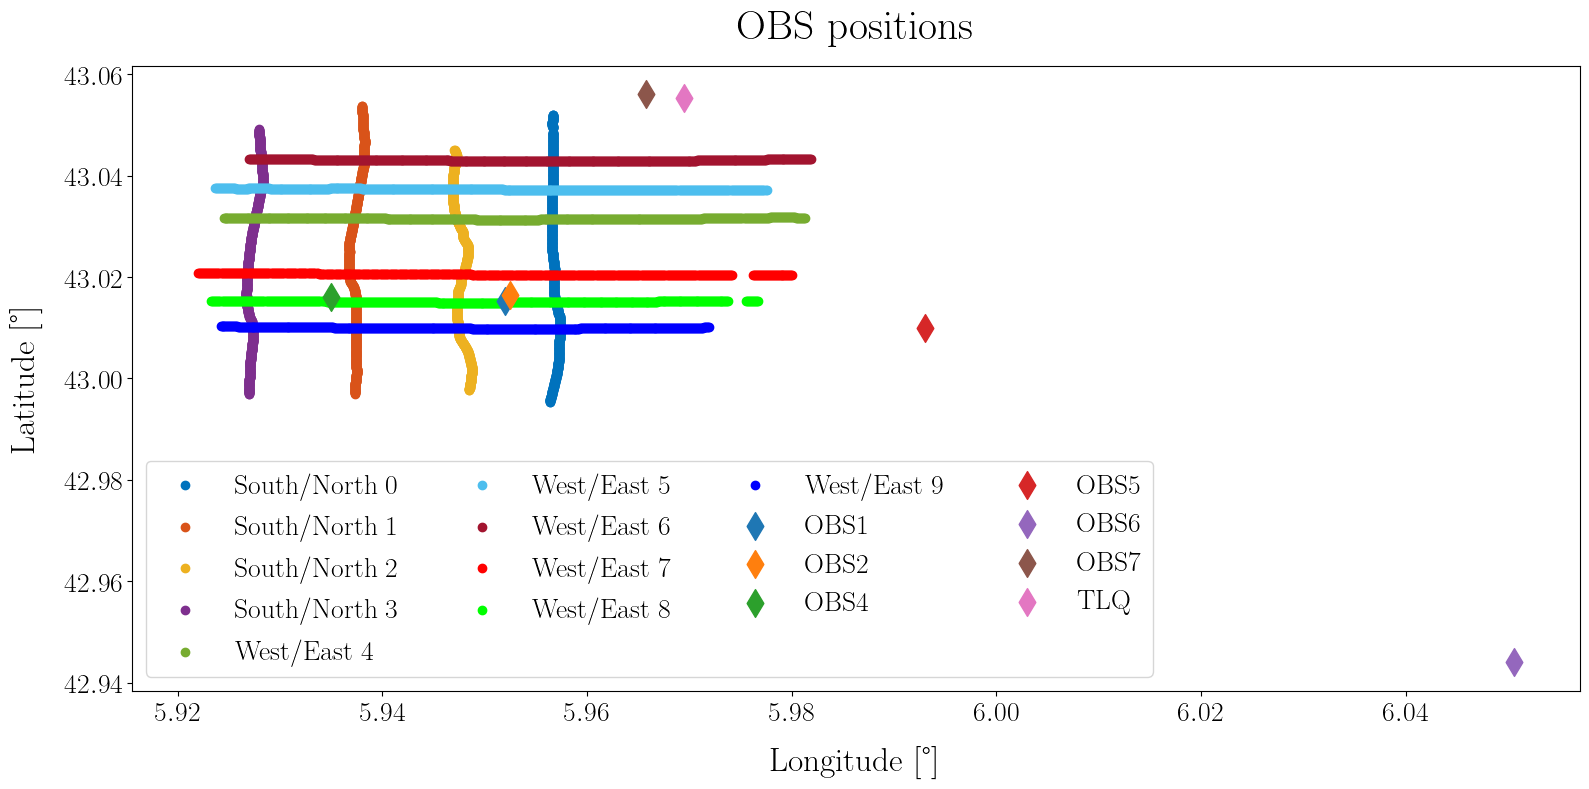

In [4]:
plot_portion_tir_pos(portion_tree=portion)

## Illustration du décalage observé 

In [5]:
c0 = 1508       # equivalent celerity 
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time 
    tps_propagation_s = dpropa_direct / c0 
    # tps_propagation_s = ds_pos_section.src_rcv_geodesic_dist / c0 
    ds_pos_section["tps_propagation_s"] = tps_propagation_s
    ds_pos_section.tps_propagation_s.attrs = {
        "units": "s",
        "long_name": "Propagation time",
    }

    # Derive associated arrival dt 
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

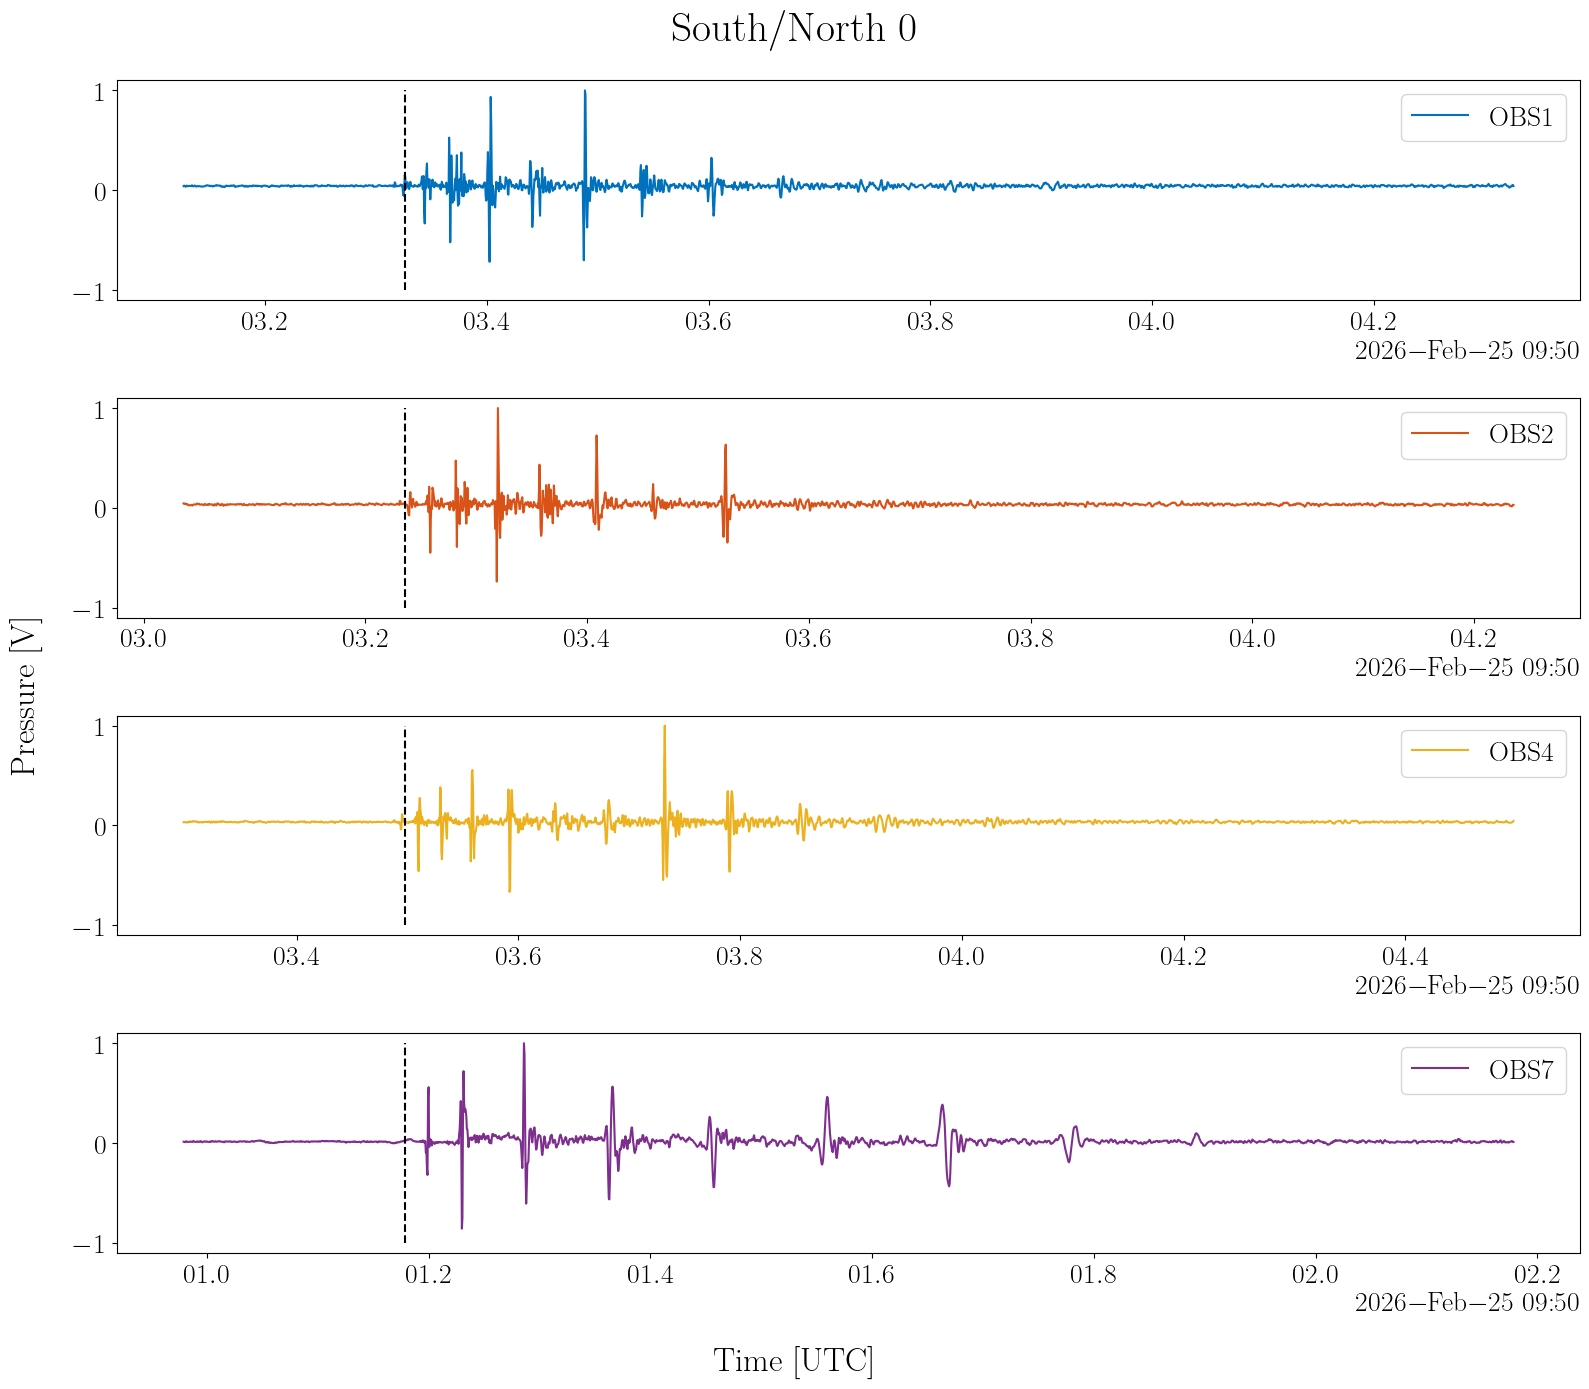

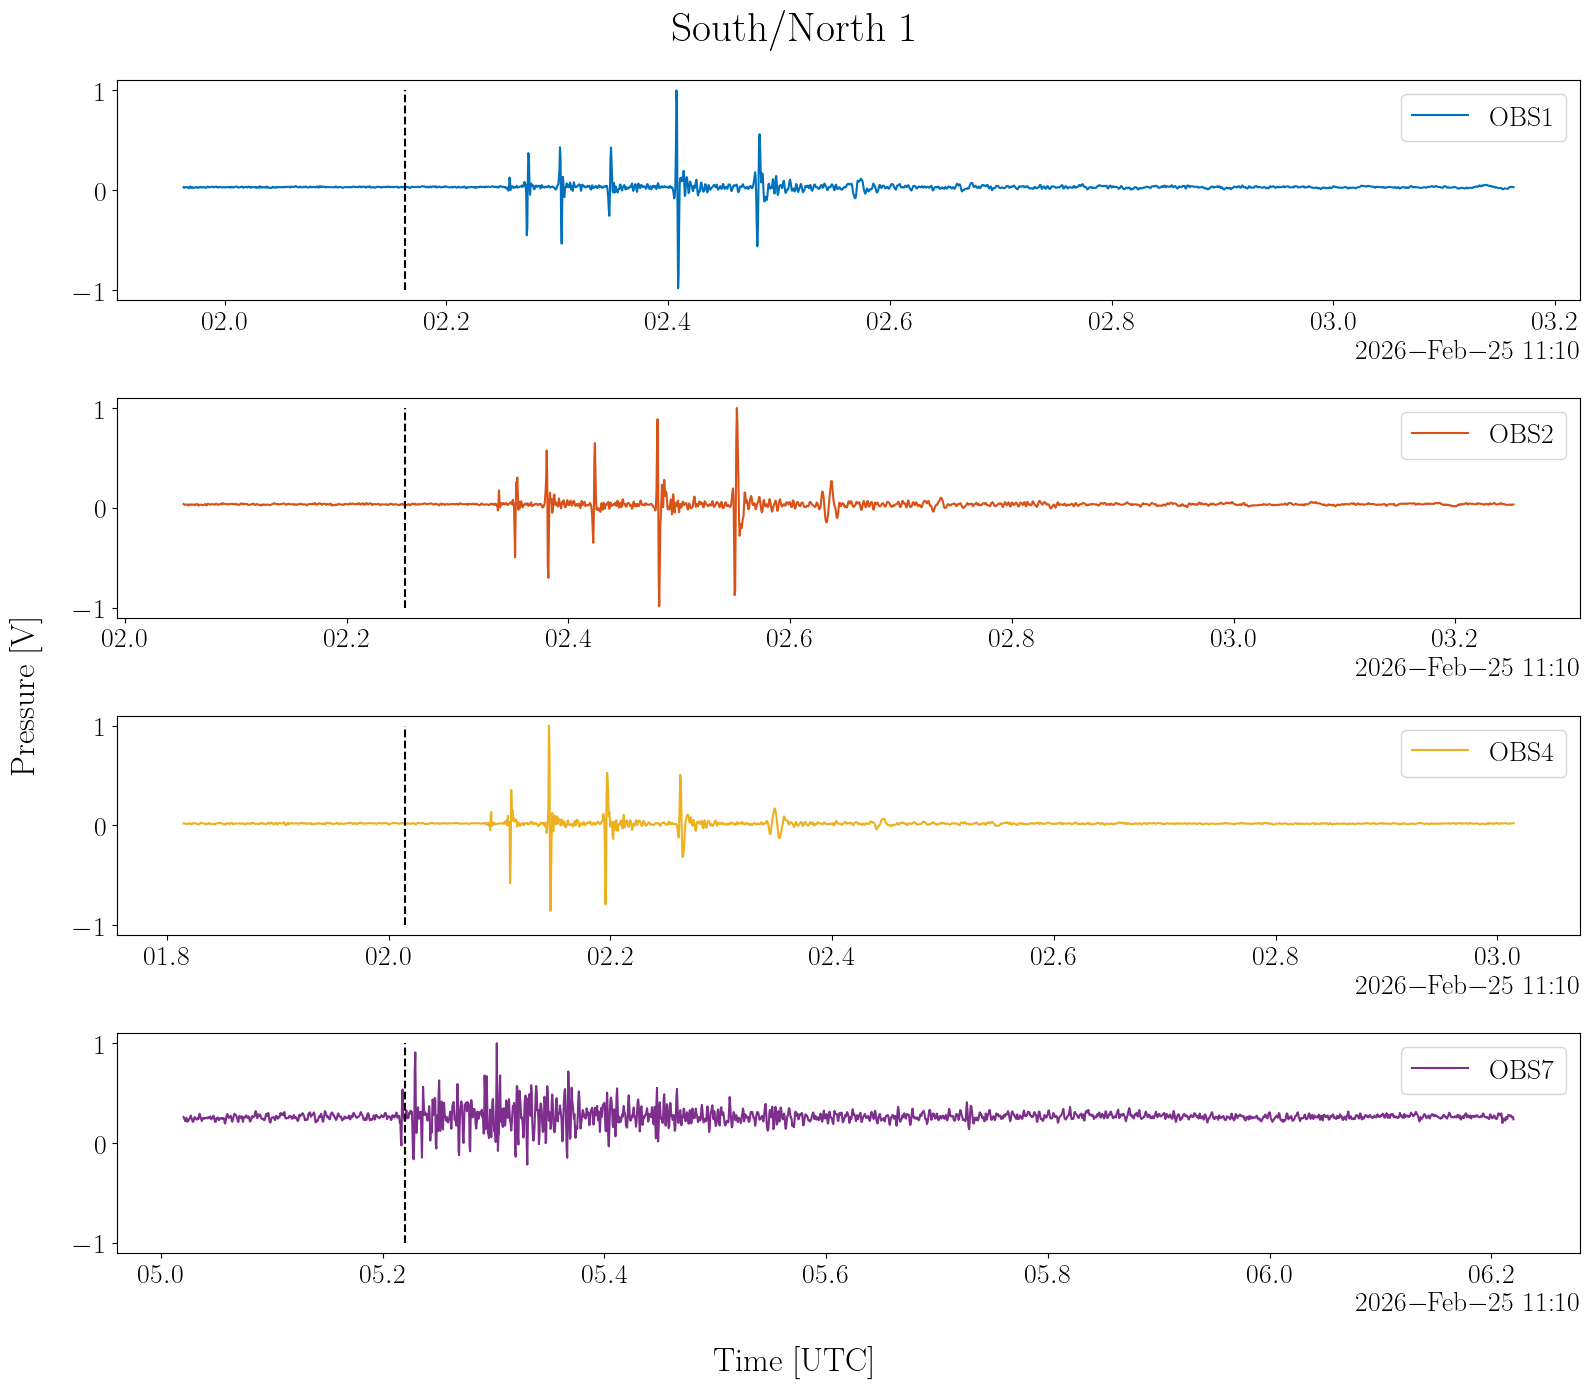

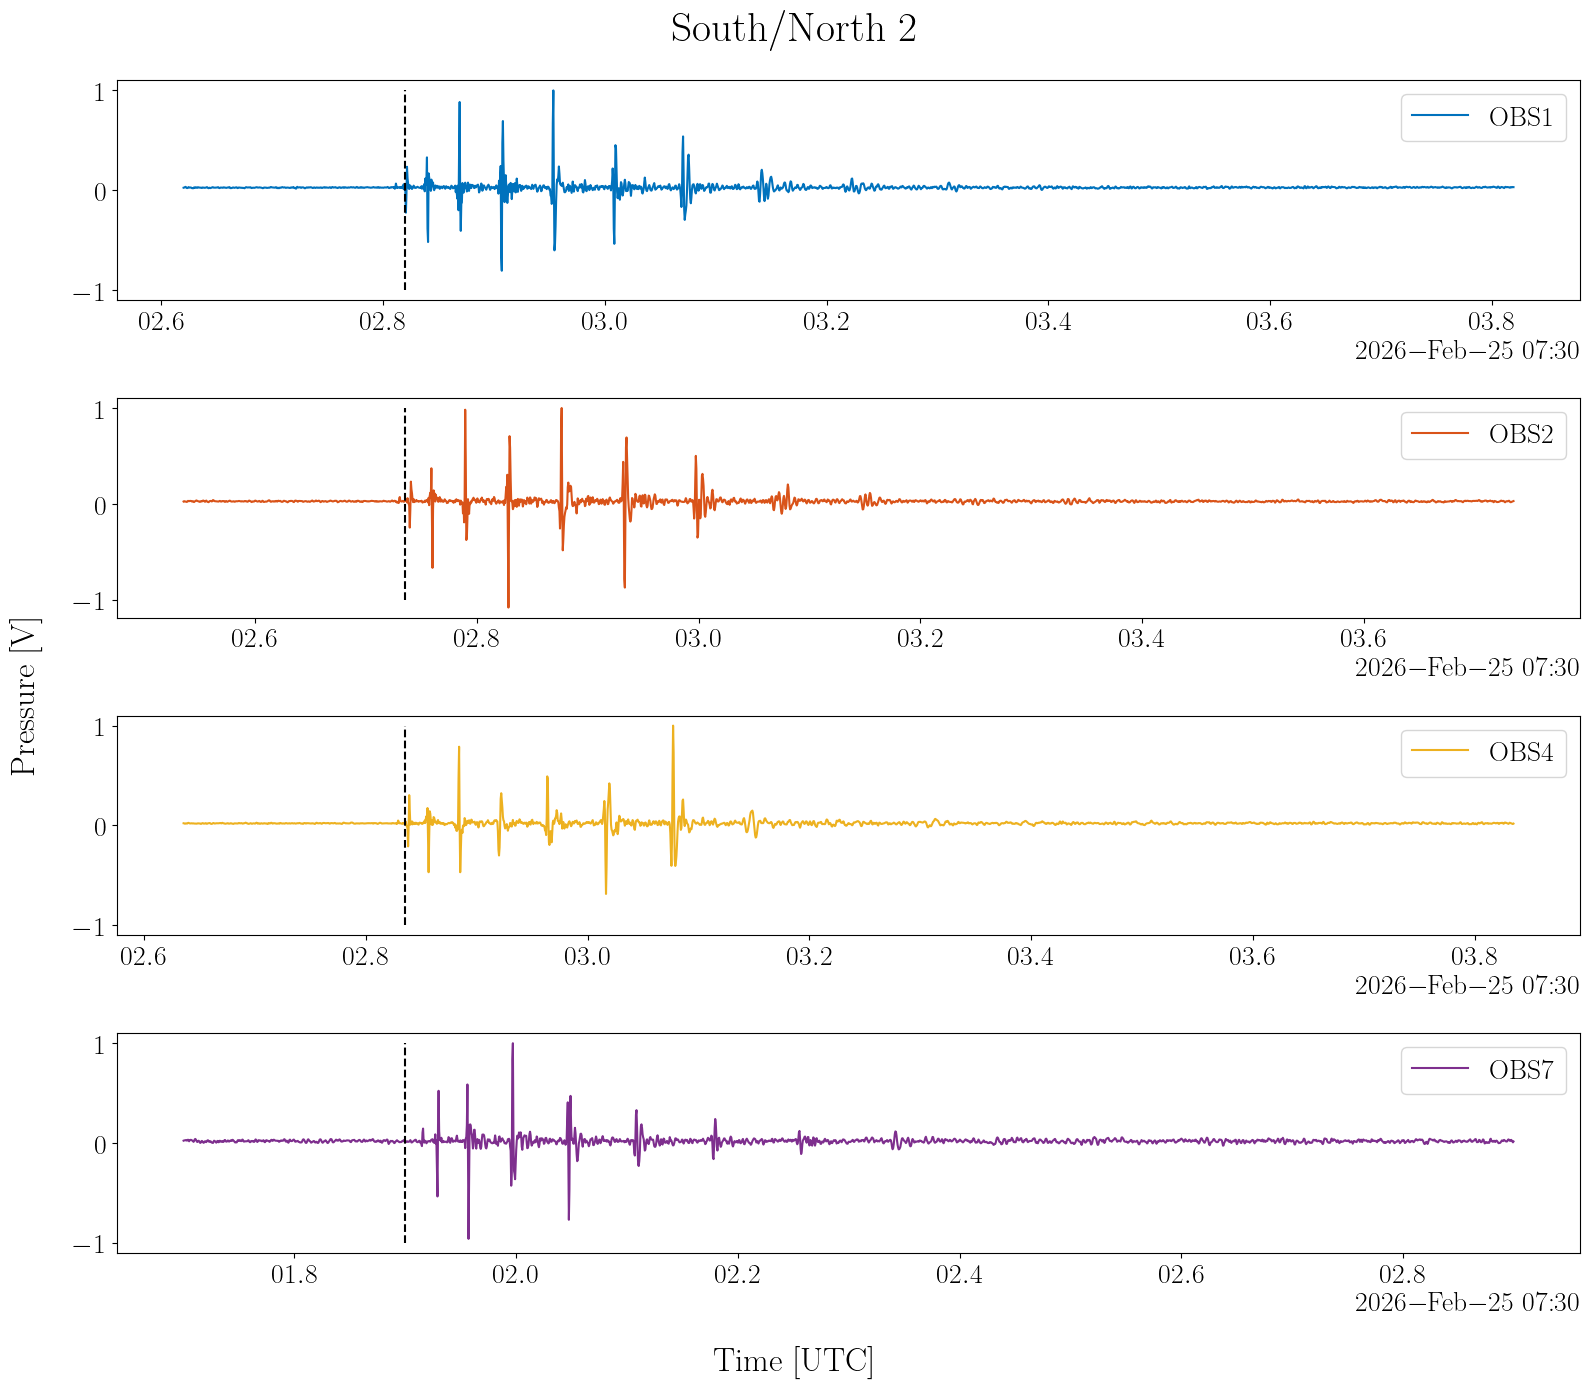

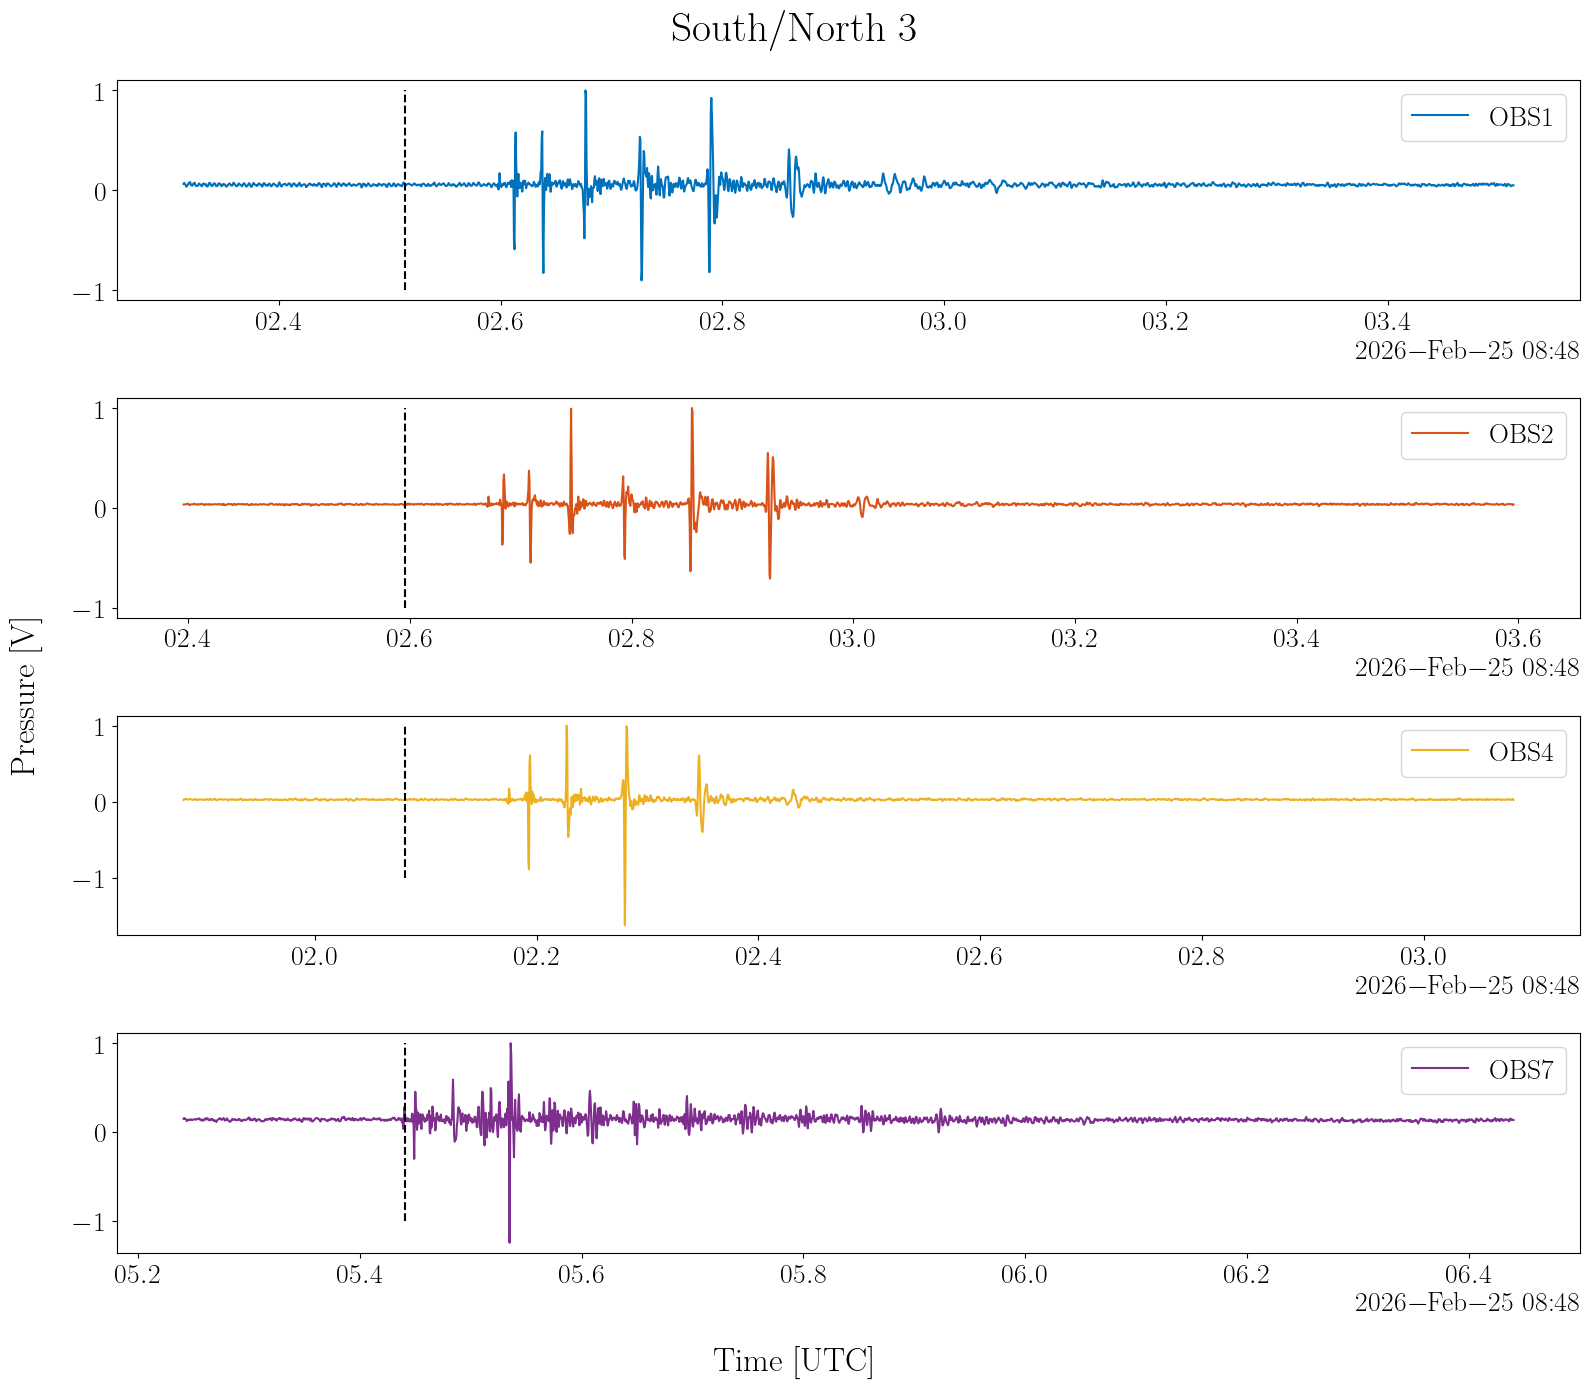

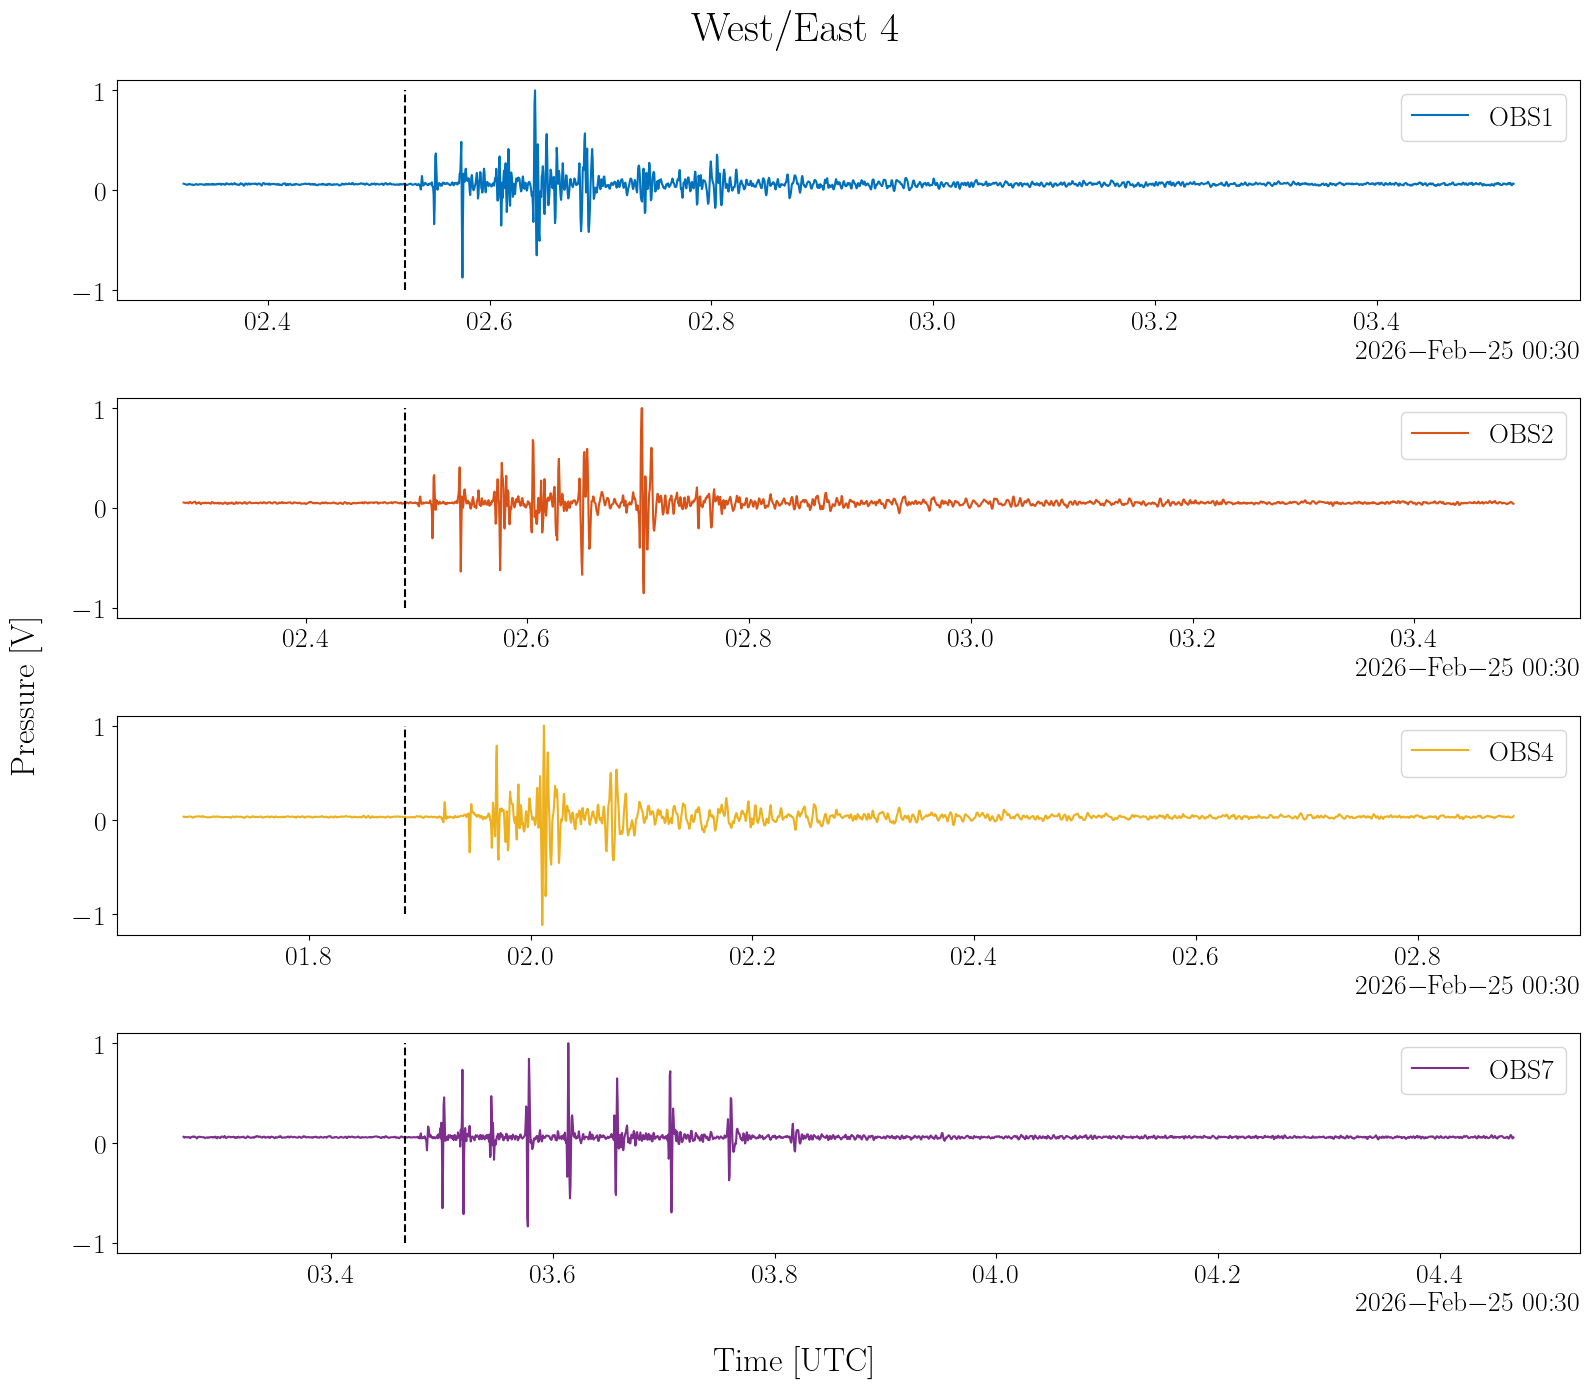

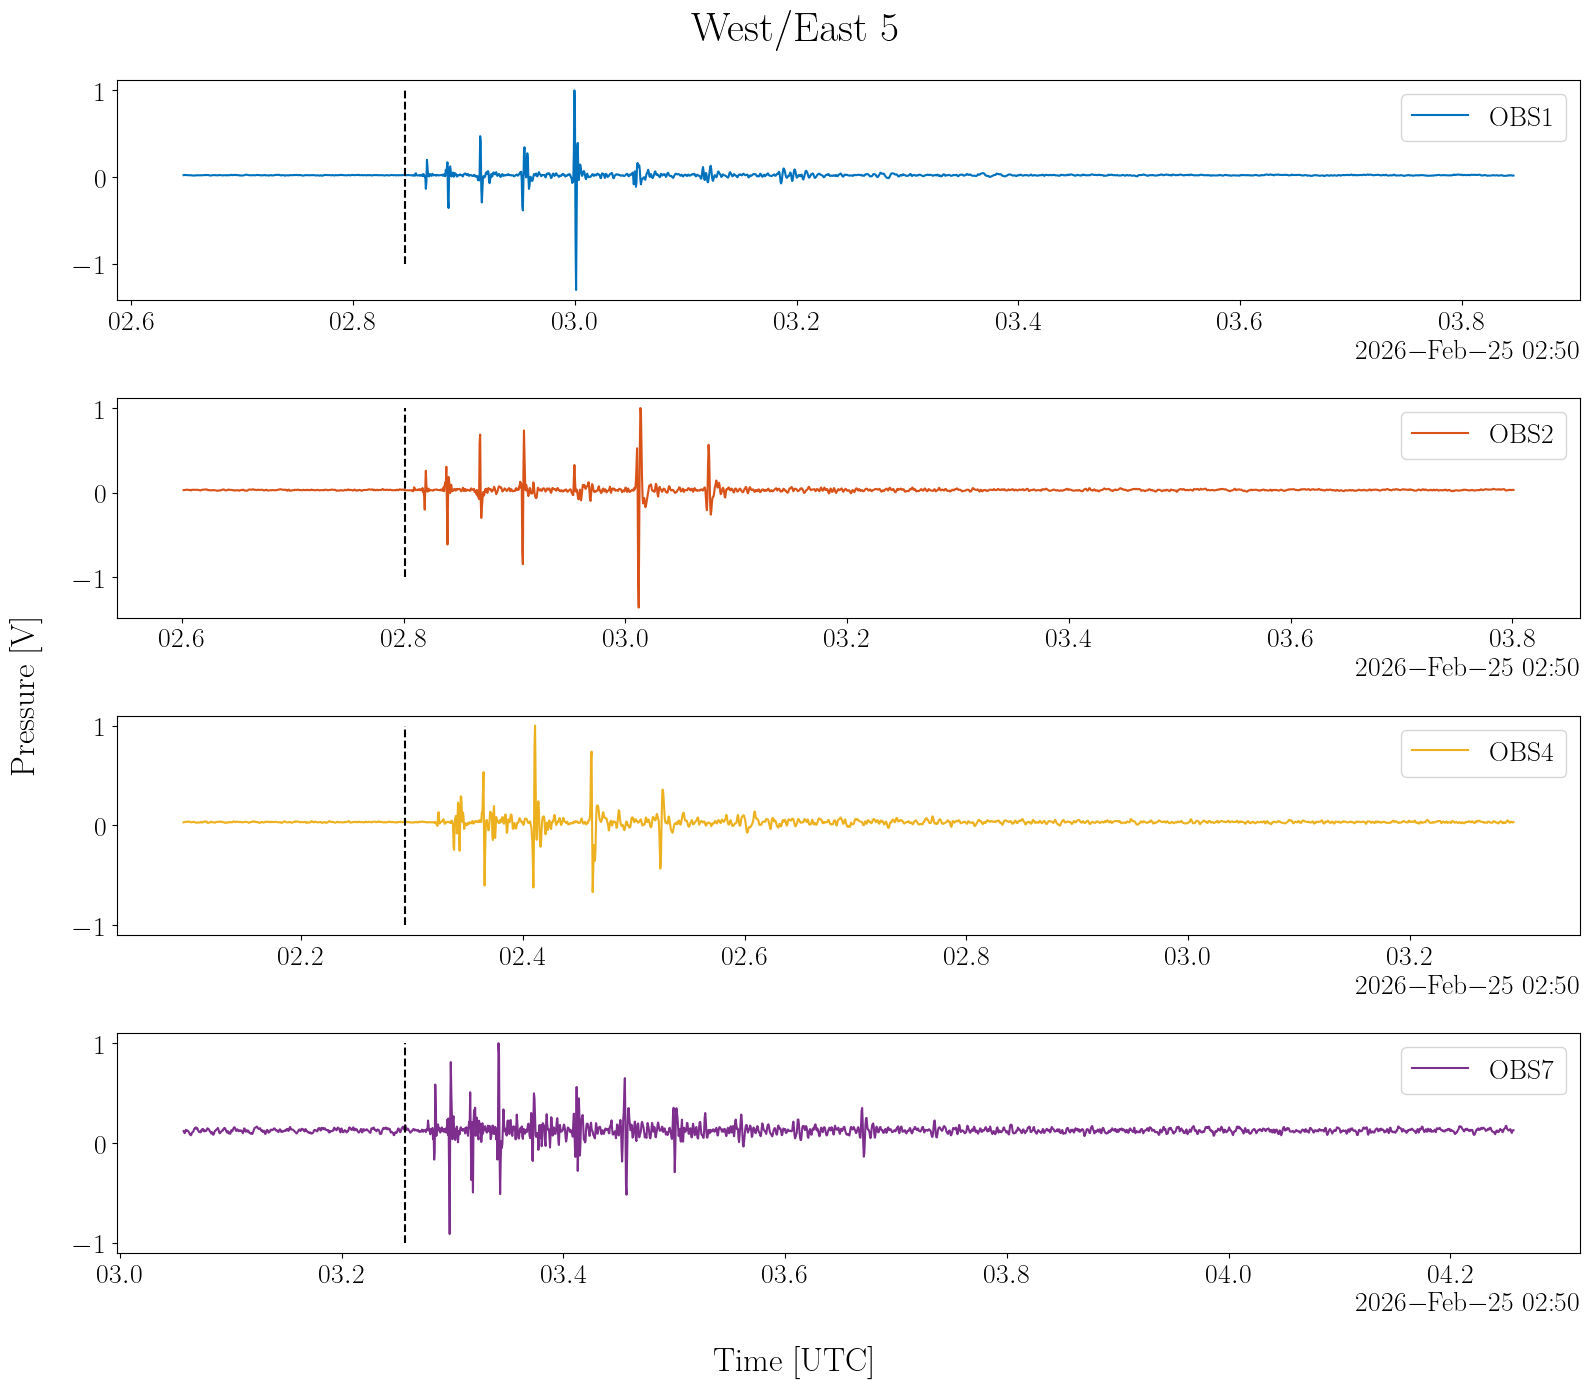

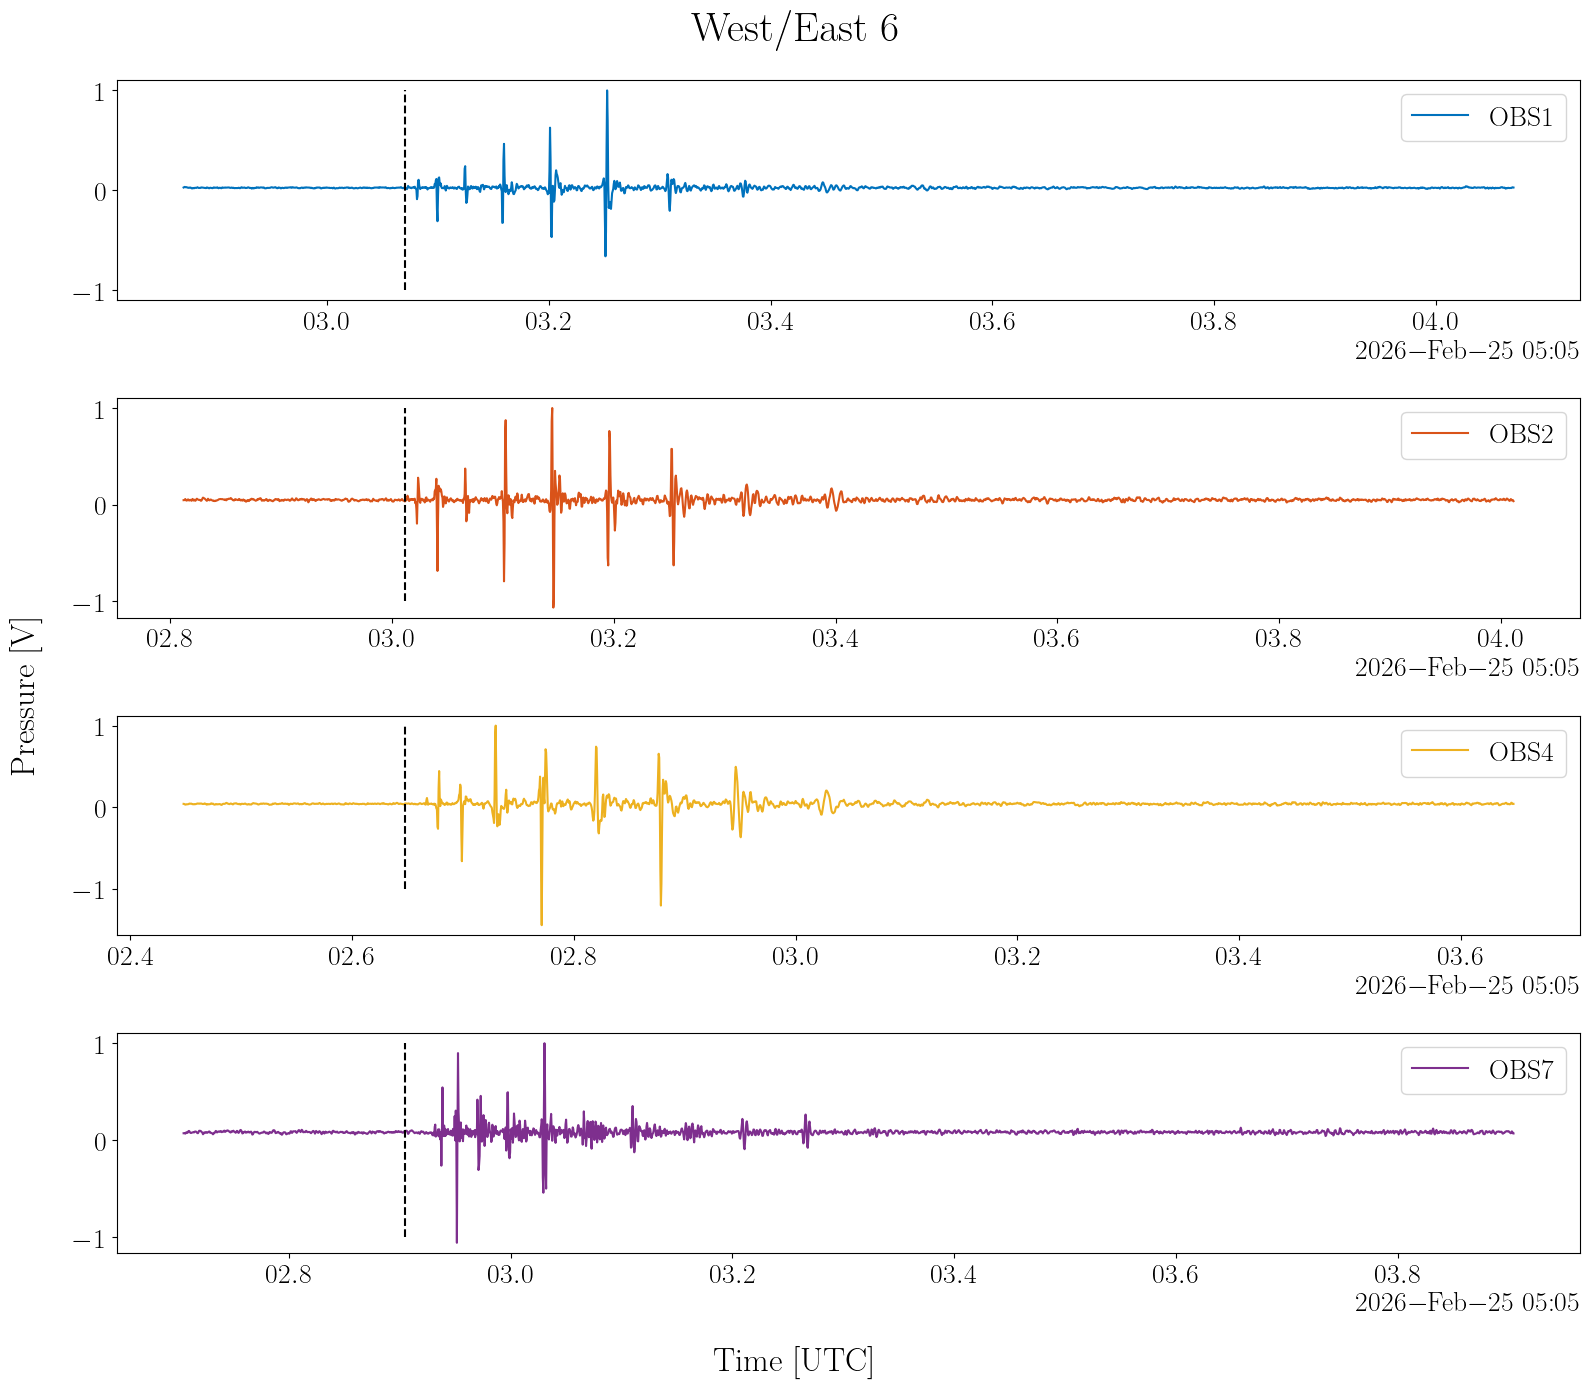

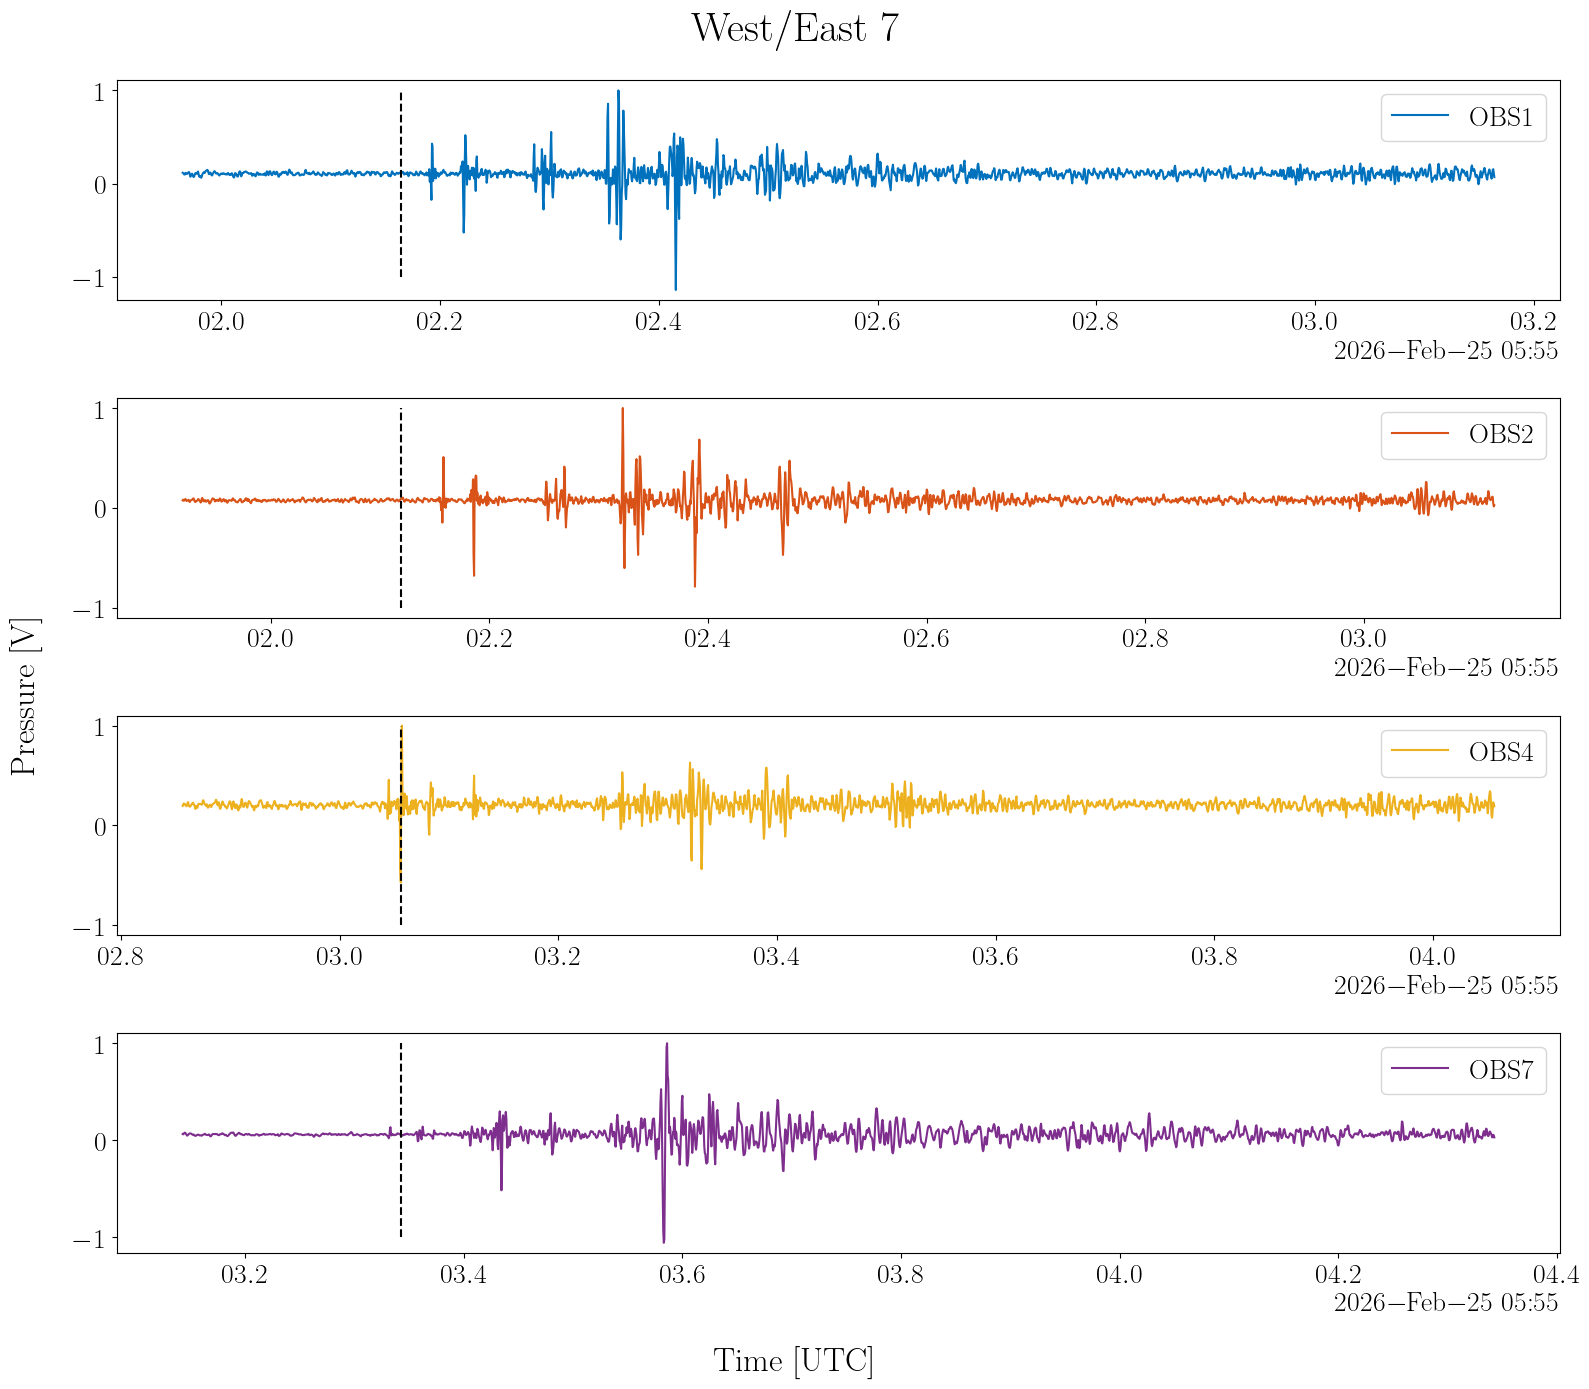

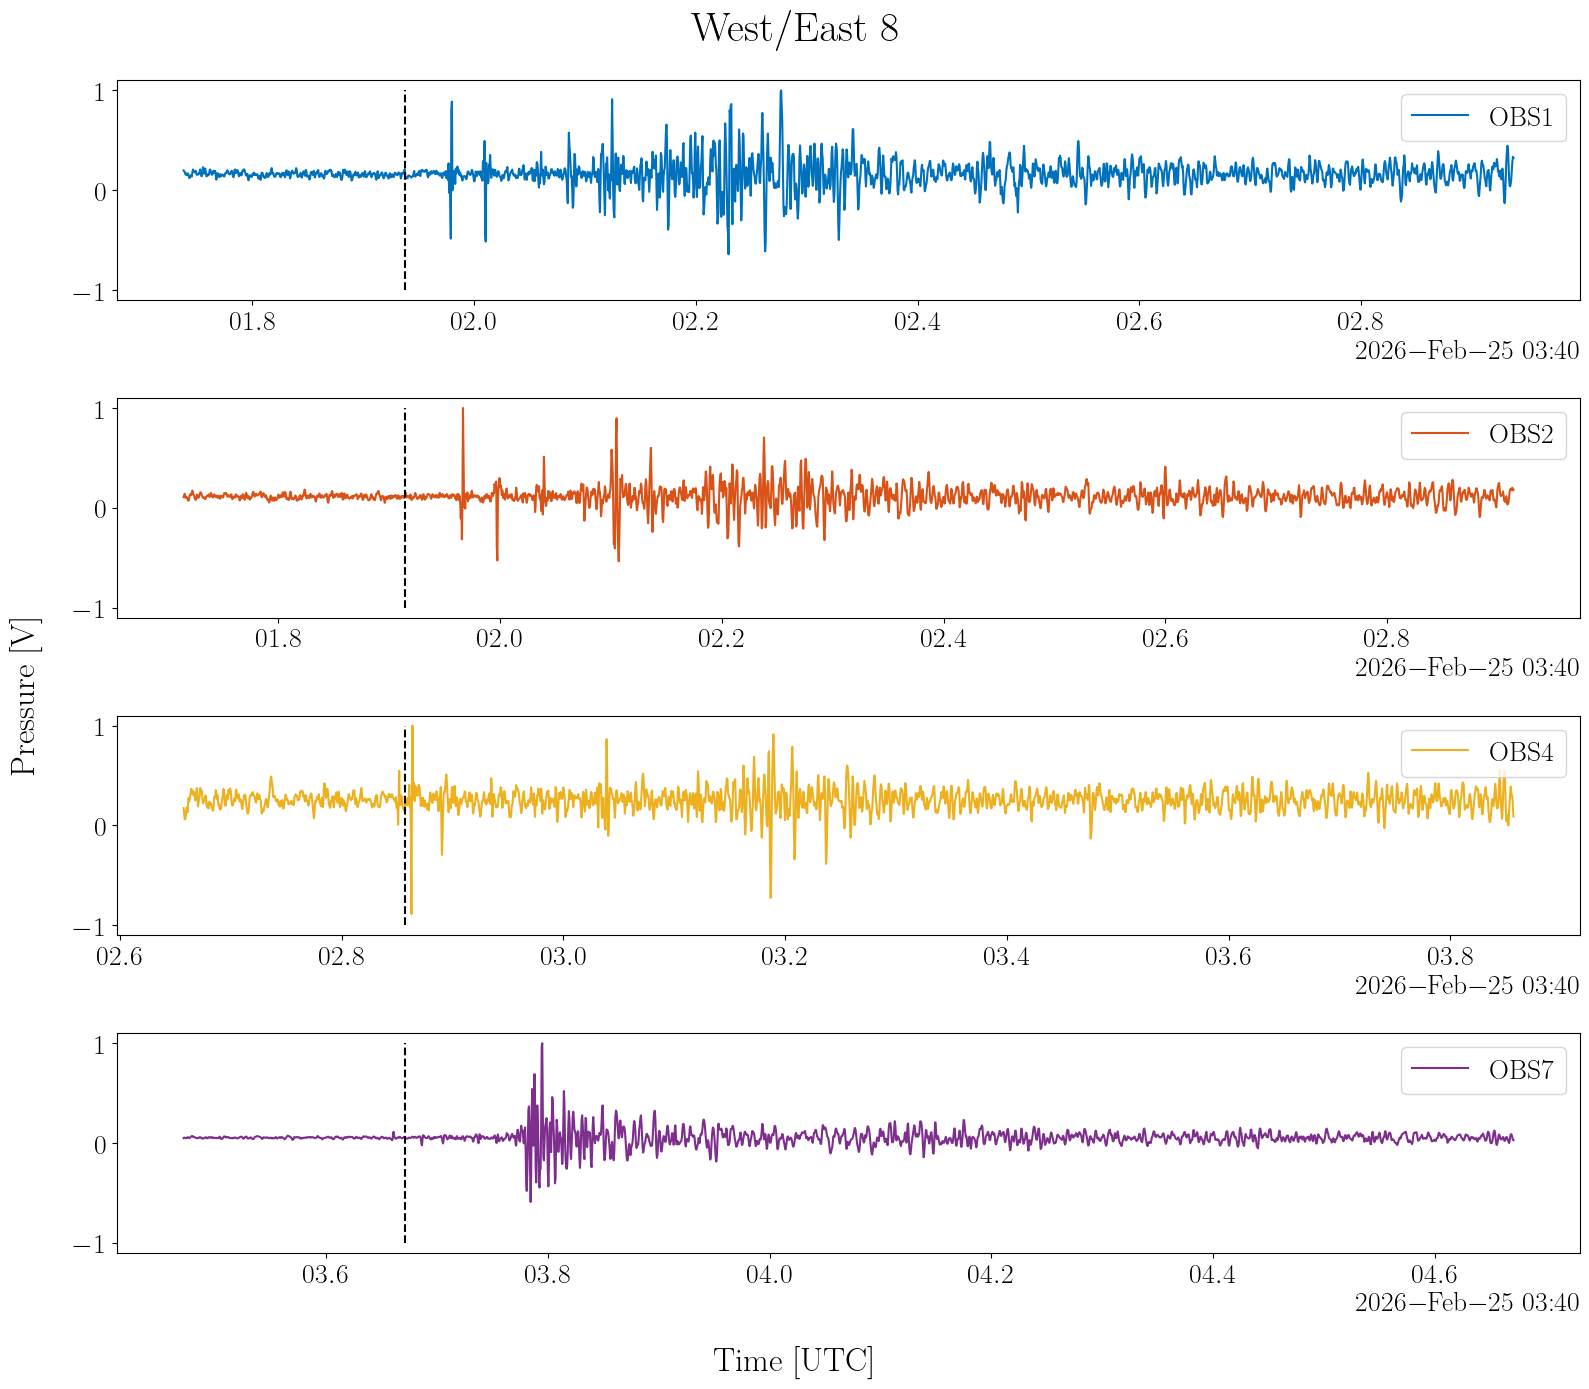

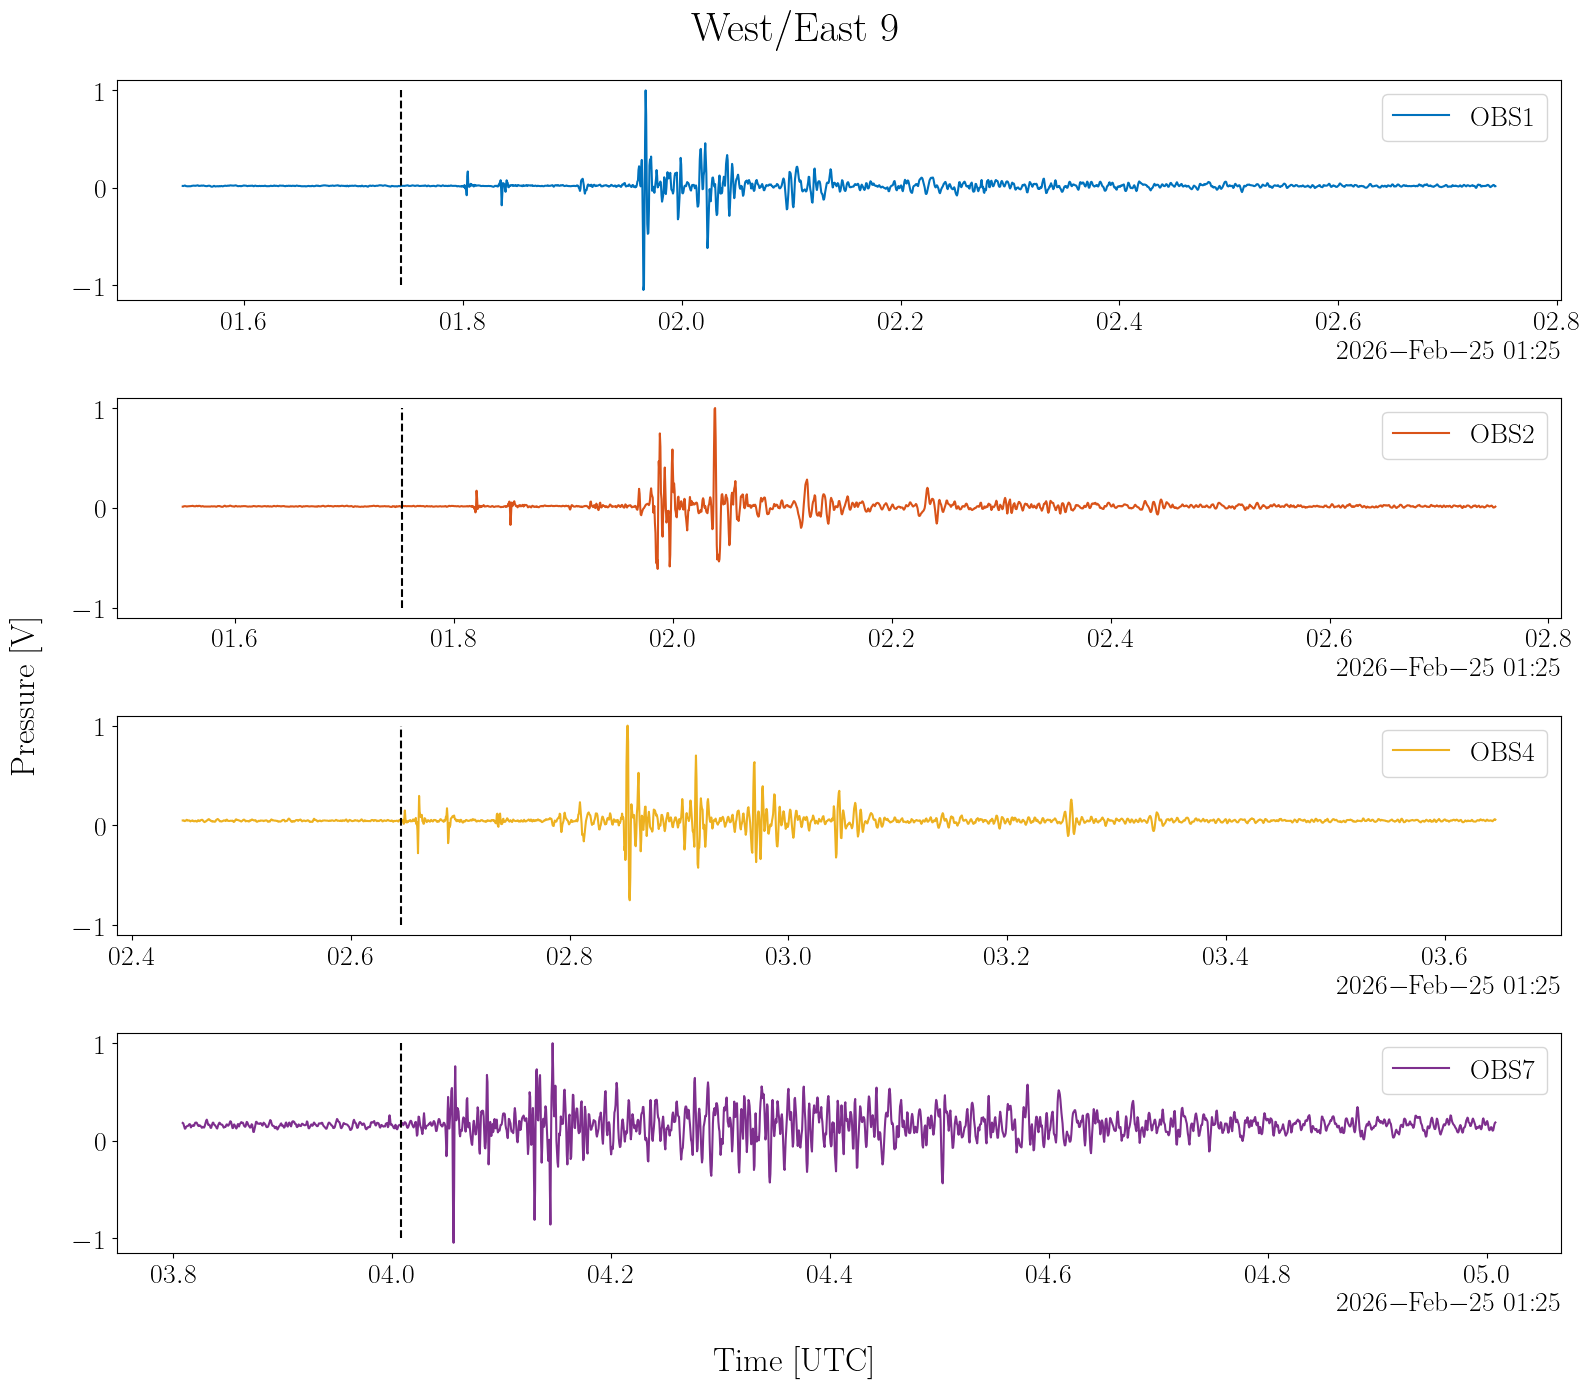

In [6]:
nb_tir = 1
offset1 = 200
offset2 = 1000
obs_ids = np.array(["obs1", "obs2", "obs4", "obs7"])

# obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
# obs_ids = obs_ids[[0, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})
        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

L'objectif de ce notebook est de corriger le décalage observé, en particulier sur l'OBS 7. 

# Inversion de la position des OBS à partir des positions des tirs sismiques 

L'hypothèse la plus plausible à ce stade pour expliquer le décalage observée entre le temps d'arrivée théorique et le temps d'arrivée observé pour l'OBS 7. 

Pour tester cette hypothèse on peut inverser la position des OBS et en particulier de l'OBS 7 par moindres carrés. 

## Projection des coordonnées WGS84 dans un repère locale 
Afin d'appliquer la méthode des moindres carrés il est nécessaire de projeter les coordonnées dans un repère local ENU. 

Le centre du repère local est choisi comme la moyenne des positions des tirs de la portion 1 étudiée. 

### Définition de l'origine du repère 

Le centre du repère local est choisi comme la moyenne des positions des tirs de la portion 1 étudiée. 

In [7]:
mean_lon, mean_lat = get_portion_tir_mean_pos(portion_tree=portion)
local_frame_origin = {"lon": mean_lon, "lat": mean_lat, "h": 0}  # MSL
local_frame_origin

{'lon': np.float64(5.947498437903631),
 'lat': np.float64(43.02491775327296),
 'h': 0}

### Ondulation du géoide 

Afin de définir convenablement l'origine du repère local ENU utilisé ainsi que la hauteur ellipsoïdale associée à chacune des positions GPS (et donc la composante z de la position de la source dans le repère ENU), il est nécessaire de connaitre l'élévation du géoïde (qui coïncide avec le niveau moyen de la mer) au-dessus de l'ellipsoïde de référence. 

Quelques définitions / notations : 

* H : altitude orthométrique (altitude au-dessus du géoïde)
* h : altitude géographique (hauteur au-dessus de l'ellipsoïde de référence WGS84), c'est l'altitude donnée par le positionnement GPS standard. 
* N : ondulation du géoïde (hauteur du géoïde au-dessus de l'ellipsoïde de référence)

Ces trois grandeurs sont reliées par la relation suivante : 

$$
h \approx H + N 
$$

L'approximation est valide au niveau millimétrique. 

Afin d'accéder à l'ondulation du géoïde N dans la zone d'intérêt il est nécessaire d'utiliser un modèle global du champ de pesanteur terrestre. Le modèle couramment utilisé est le modèle EGM2008. L'EGM2008 (Earth Gravitational Model EGM2008) est un modèle global du champ de pesanteur
terrestre diffusé sous la forme d’harmoniques sphériques développés jusqu’à l’ordre 2159 (Pavlis et al., 2012). Il est issu de données de gravimétrie terrestres, aéroportées et spatiales.

En python, il semble que l'on puisse accéder à une estimation de l'ondulation du géoïde à l'aide de la librairie geoid_toolkit. Cependant, la fonction geoid_undulation(lat, lon, "WGS84", clm, slm, lmax, R, GM) nécessite de fournir les paramètres du développement en harmoniques sphériques. Par soucis de simplicité, et au vu des incertitudes sur le reste des coordonnées verticales que l'on manipule ici, on se contente ici d'une valeur fournie par le site web https://geographiclib.sourceforge.io/cgi-bin/GeoidEval?input=47.5+-3.5&option=Submit pour la position de référence (origine du repère local). 

$$
lon_0 = 5.946085^\circ, lat_0 = 43.042972^\circ
$$
 
$$
N(lon_0, lat_0) = 48.5778 ~\text{m (EGM2008)} 
$$

In [8]:
N_geoid_undulation = 48.5

### Projection des positions des tirs sismiques 

In [9]:
get_enu_tir_pos(portion_tree=portion, local_frame_origin=local_frame_origin, N_geoid_undulation=N_geoid_undulation)

In [10]:
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_dat...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 521,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * mmsi                    (mmsi) int64 4kB 4 127 128 129 ... 431 125 32 244
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B 119 119 118 1077 306 91 93
│   │           rcv_lon_apriori         (rcv_id) float64 56B ...
│   │           rcv_lat_apriori         (rcv_id) float64 56B ...
│   │           rcv_immersion_apriori   (rcv_id) int16 14B ...
│   │           ...                      ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB 4.11e+03 ... ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB 2.726 ... 4.476
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB 2026-0...
│   │           tir_src_e               (src_datetime) float64 6kB 750.3 749.6 ... 721.3
│   │           tir_src_n               (src_datetime) float64 6kB 3.011e+03 ... -3.288e+03
│   │           tir_src_u               (src_datetime) float64 6kB 42.74 42.75 ... 42.61
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 521,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * mmsi                    (mmsi) int64 4kB 4 127 128 129 ... 431 125 32 244
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Data variables: (12/22)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B 119 119 118 1077 306 91 93
│   │           rcv_lon_apriori         (rcv_id) float64 56B ...
│   │           rcv_lat_apriori         (rcv_id) float64 56B ...
│   │           rcv_immersion_apriori   (rcv_id) int16 14B ...
│   │           ...                      ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB 2.354e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB 1.563 ... 1.705
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB 2026-0...
│   │           tir_src_e               (src_datetime) float64 6kB -831.6 -831.5 ... -771.2
│   │           tir_src_n               (src_datetime) float64 6kB -3.106e+03 ... 3.201e+03
│   │           tir_src_u               (src_datetime) float64 6kB 42.69 42.69 ... 42.6

### Projection des positions des OBS

In [11]:
get_enu_rcv_pos(portion_tree=portion, local_frame_origin=local_frame_origin, N_geoid_undulation=N_geoid_undulation)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_dat...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 521,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * mmsi                    (mmsi) int64 4kB 4 127 128 129 ... 431 125 32 244
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Data variables: (12/25)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 119 118 1077 306 91 93
│   │           rcv_lon_apriori         (rcv_id) float64 56B ...
│   │           rcv_lat_apriori         (rcv_id) float64 56B ...
│   │           rcv_immersion_apriori   (rcv_id) int16 14B ...
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 6kB 750.3 749.6 ... 721.3
│   │           tir_src_n               (src_datetime) float64 6kB 3.011e+03 ... -3.288e+03
│   │           tir_src_u               (src_datetime) float64 6kB 42.74 42.75 ... 42.61
│   │           rcv_e                   (rcv_id) float64 56B 369.1 409.1 ... 1.792e+03
│   │           rcv_n                   (rcv_id) float64 56B -1.081e+03 -947.4 ... 3.375e+03
│   │           rcv_u                   (rcv_id) float64 56B -70.6 -70.58 ... -43.62 -45.65
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 521,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * mmsi                    (mmsi) int64 4kB 4 127 128 129 ... 431 125 32 244
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Data variables: (12/25)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 119 118 1077 306 91 93
│   │           rcv_lon_apriori         (rcv_id) float64 56B ...
│   │           rcv_lat_apriori         (rcv_id) float64 56B ...
│   │           rcv_immersion_apriori   (rcv_id) int16 14B ...
│   │           ...                      ...
│   │           tir_src_e               (src_datetime) float64 6kB -831.6 -831.5 ... -771.2
│   │           tir_src_n               (src_datetime) float64 6kB -3.106e+03 ... 3.201e+03
│   │           tir_src_u               (src_datetime) float64 6kB 42.69 42.69 ... 42.65
│   │           rcv_e                   (rcv_id) float64 56B 369.1 409.1 ... 1.792e+03
│   │           rcv_n                   (rcv_id) float64 56B -1.081e+03 -947.4 ... 3.375e+03
│   │   

### Comparaison des positions dans les deux repères

On s'assure que tout est ok. 

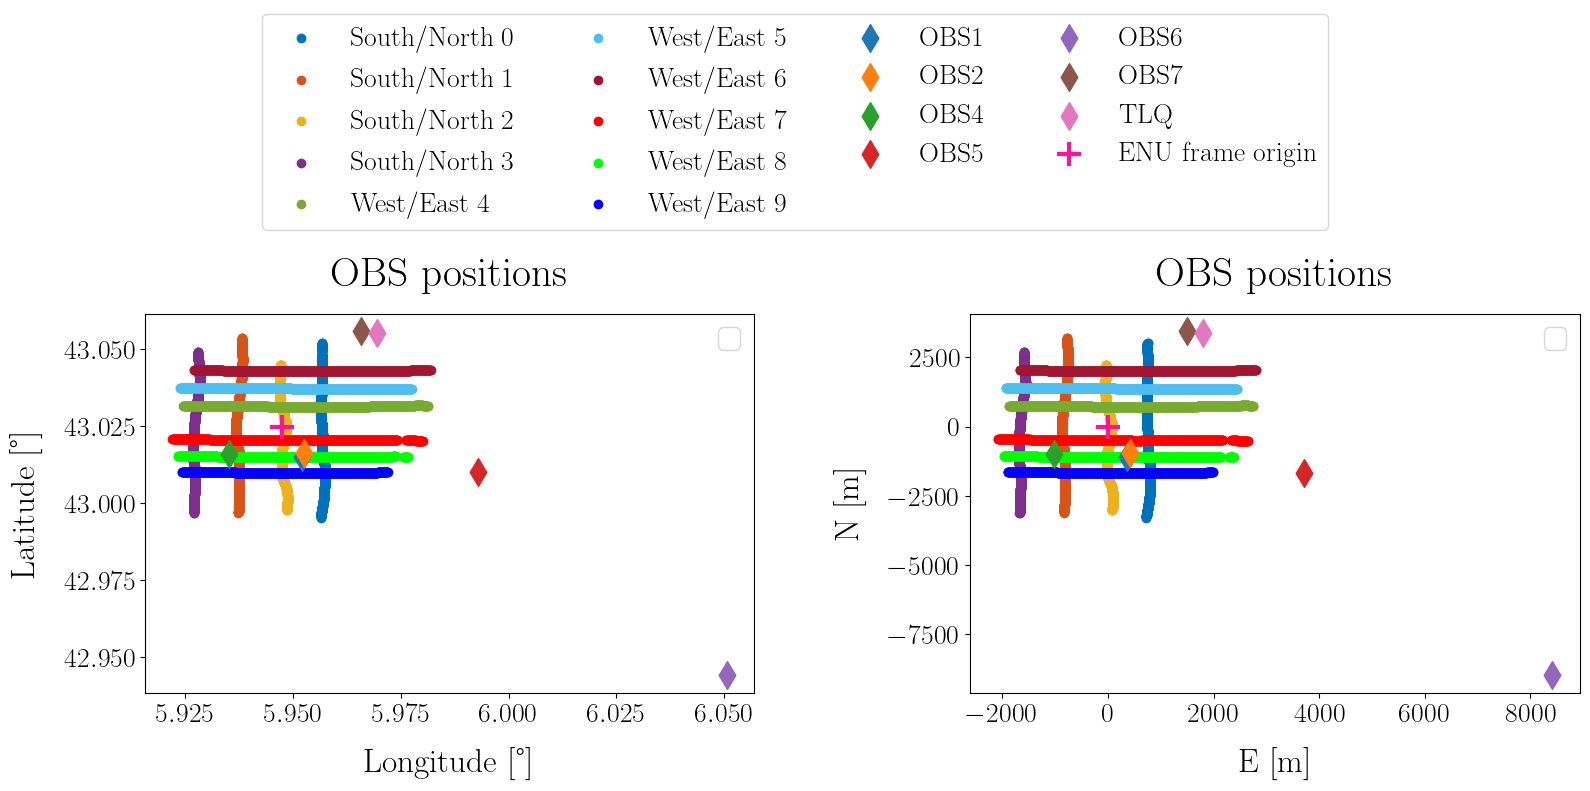

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8))

# Plot pos in WGS84

plot_portion_tir_pos(portion, ax=axs[0])
# Add local frame origin position
axs[0].scatter(
    local_frame_origin["lon"],
    local_frame_origin["lat"],
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)
axs[0].legend(labels=[])

# Plot pos in ENU
plot_portion_tir_pos_enu(portion, ax=axs[1])
# Add local frame origin position
axs[1].scatter(
    0,
    0,
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)
axs[1].legend(labels=[])

handles, labels = axs[0].get_legend_handles_labels()
ncols = min(len(labels), 4)
fig.legend(handles=handles, ncols=ncols, loc="outside upper center")


Tout est ok, pas de déformation suite à la projection. 

### Comparaison pour la coordonnée verticale 


In [13]:
v_dist_wgs84, v_dist_enu = get_vertical_dist(portion_tree=portion)

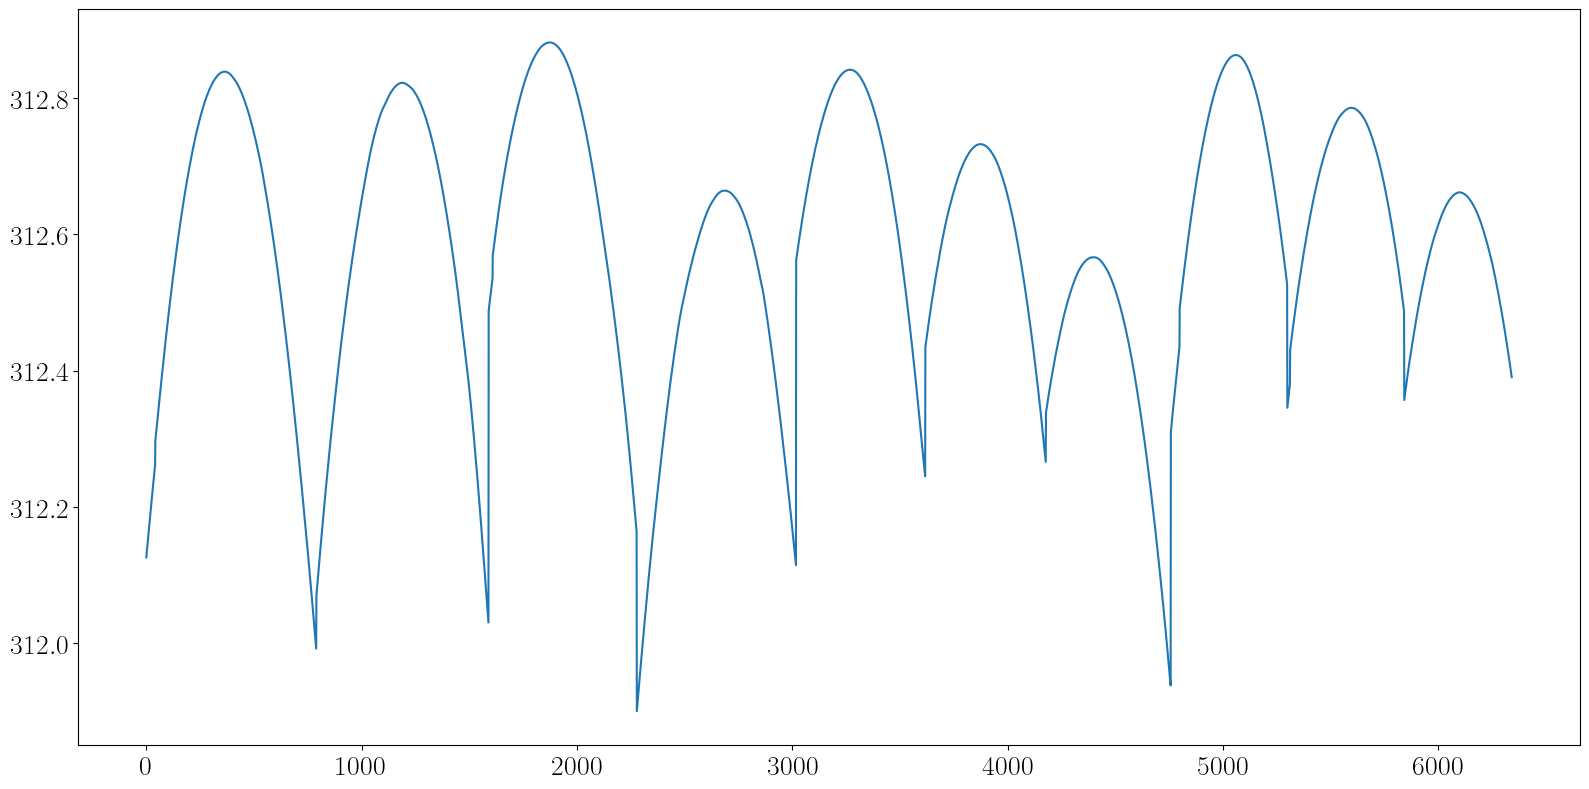

In [14]:
plt.plot(v_dist_enu[4])

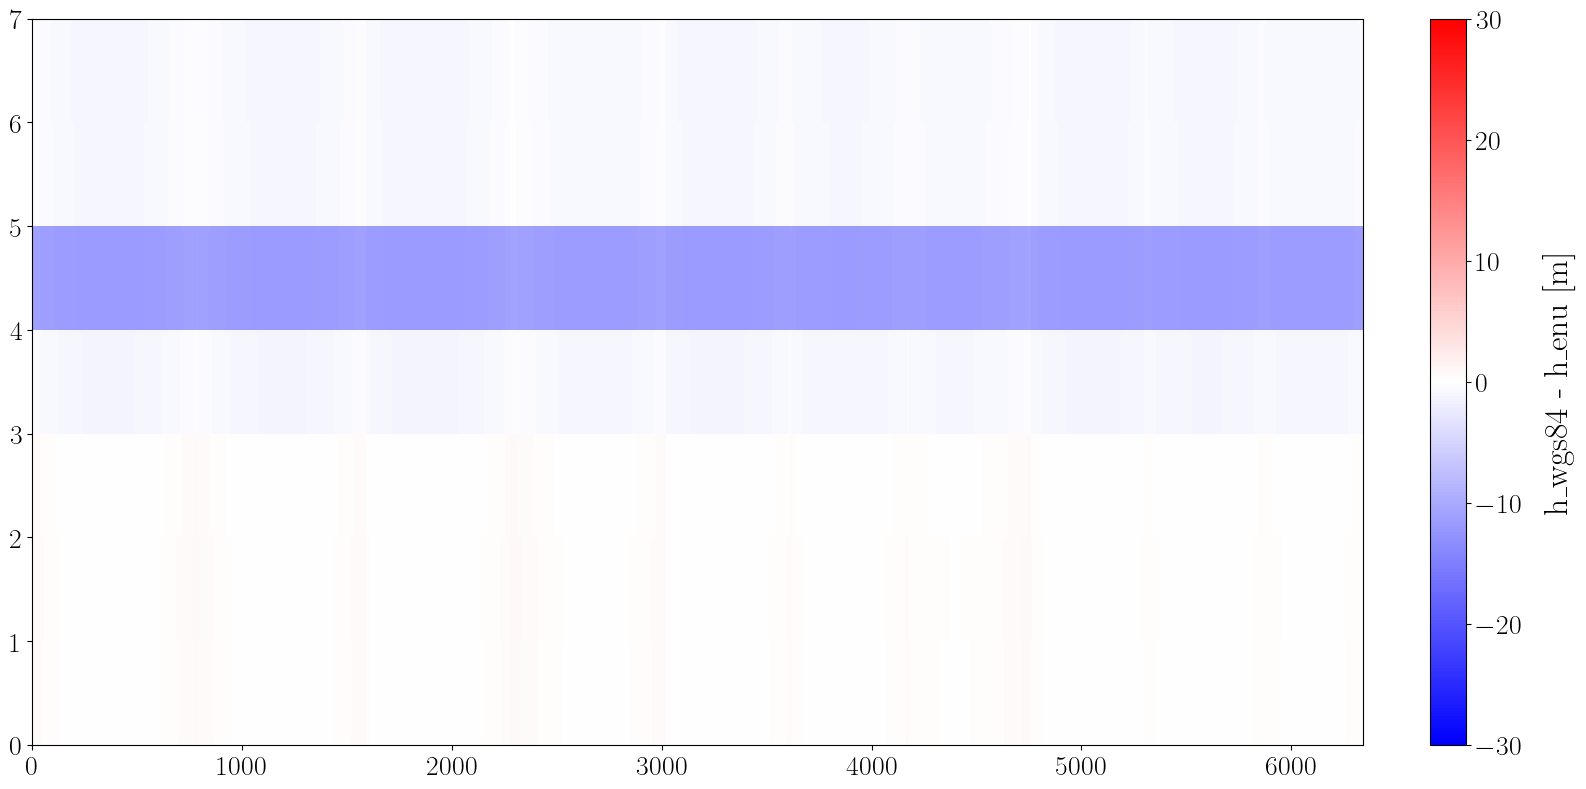

In [15]:
# fig, axs = plt.subplots(nrows=1, ncols=v_dist_enu.shape[0]-4, figsize=(16, 8))
# for i in range(v_dist_enu.shape[0]-4):
#     # Ref
#     # axs[i].plot(
#     #     [v_dist_wgs84[i, :100].min(), v_dist_wgs84[i, :100].max()],
#     #     [v_dist_enu[i, :100].min(), v_dist_enu[i, :100].max()],
#     #     color="k",
#     #     linestyle="--",
#     # )
#     # axs[i].scatter(v_dist_wgs84[i, :100], v_dist_enu[i, :100])
#     # axs[i].axis("equal")
diff_wgs84_enu = v_dist_wgs84 - v_dist_enu
im = plt.pcolormesh(diff_wgs84_enu, cmap="bwr", vmin=-30, vmax=30)
plt.colorbar(im, label="h_wgs84 - h_enu [m]")

La seule différence notable sur la coordonnée z est pour l'OBS 6 situé relativement loin (environ 13, 14 km) du centre du repère ENU. Cet écart résulte de l'écart entre le plan tangent définissant le repère ENU et la surface de l'océan courbé. 

## Estimation des temps d'arrivée 

In [16]:
import scipy.signal as sp 

### Illustration sur quelques émissions 

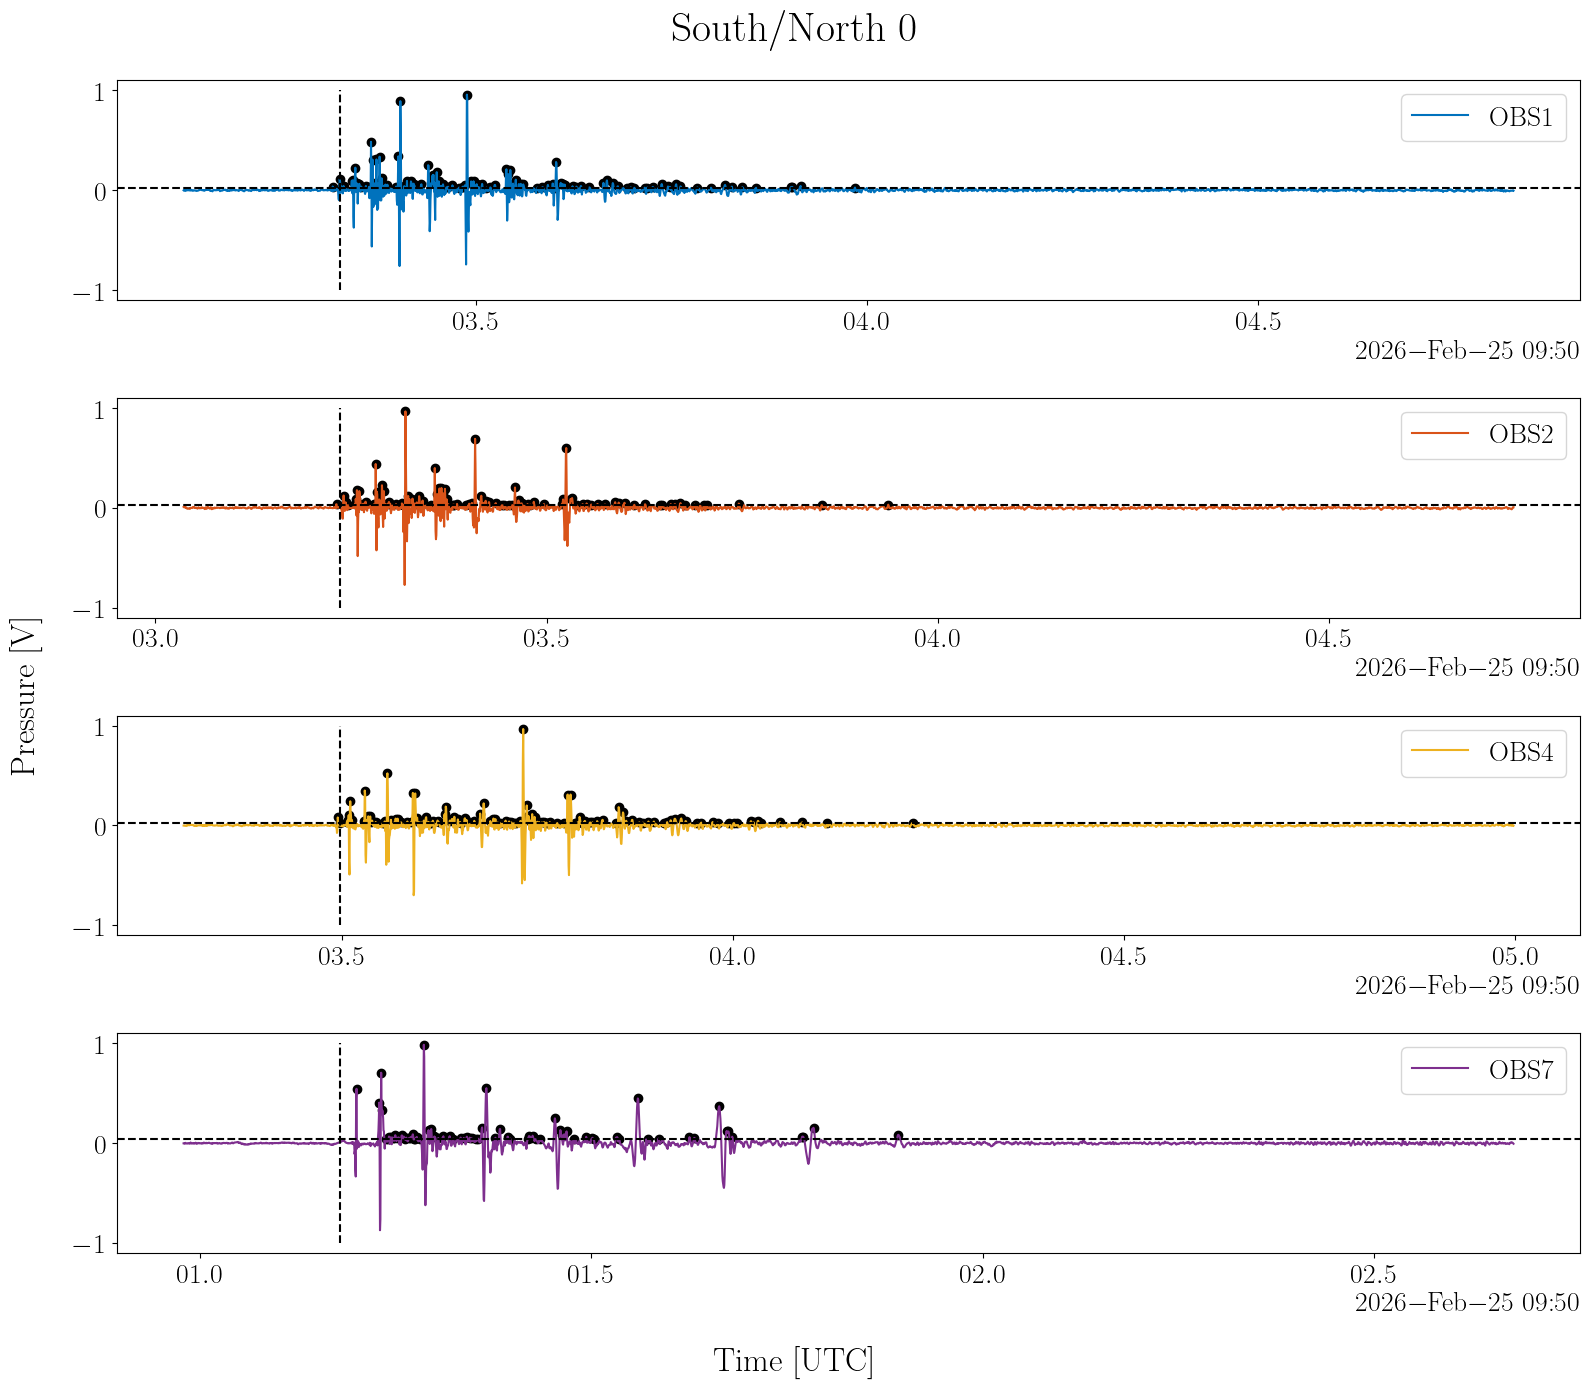

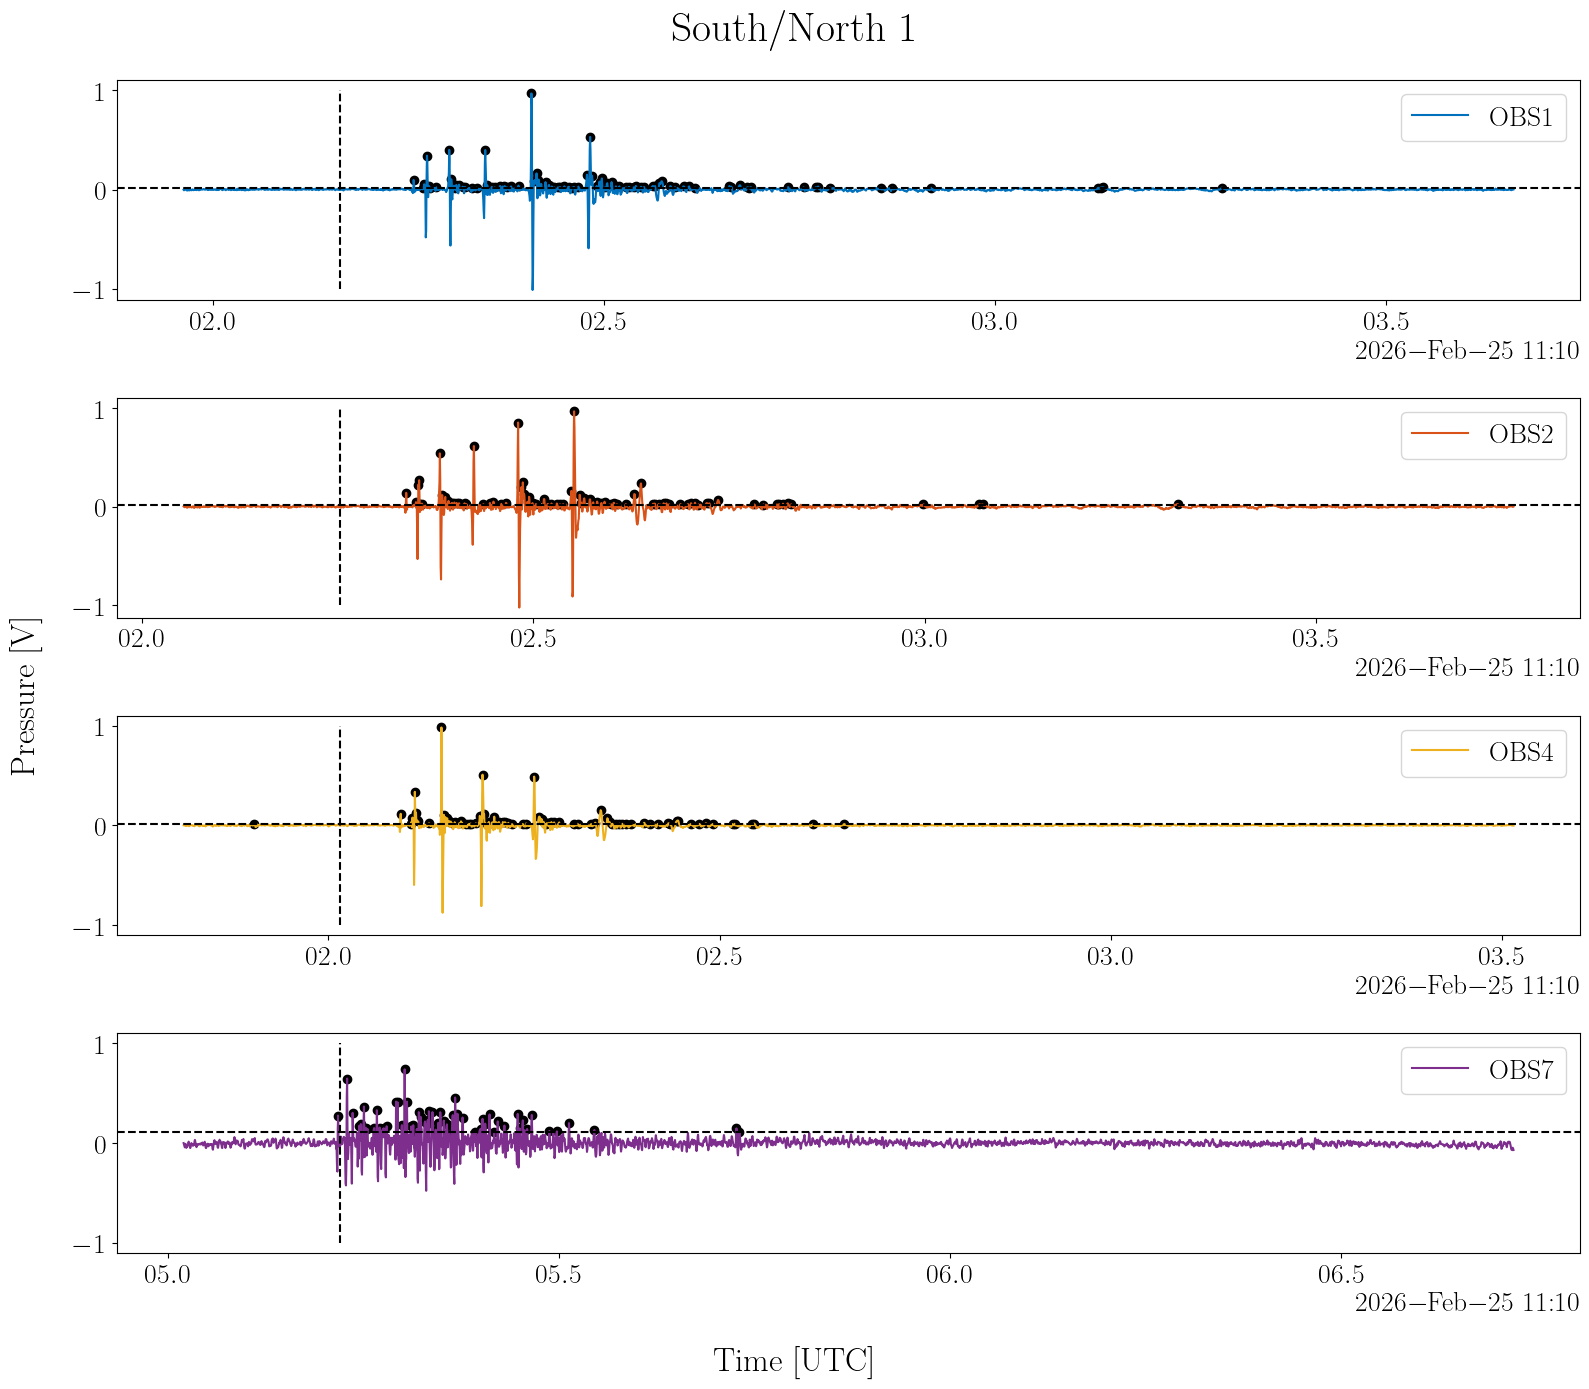

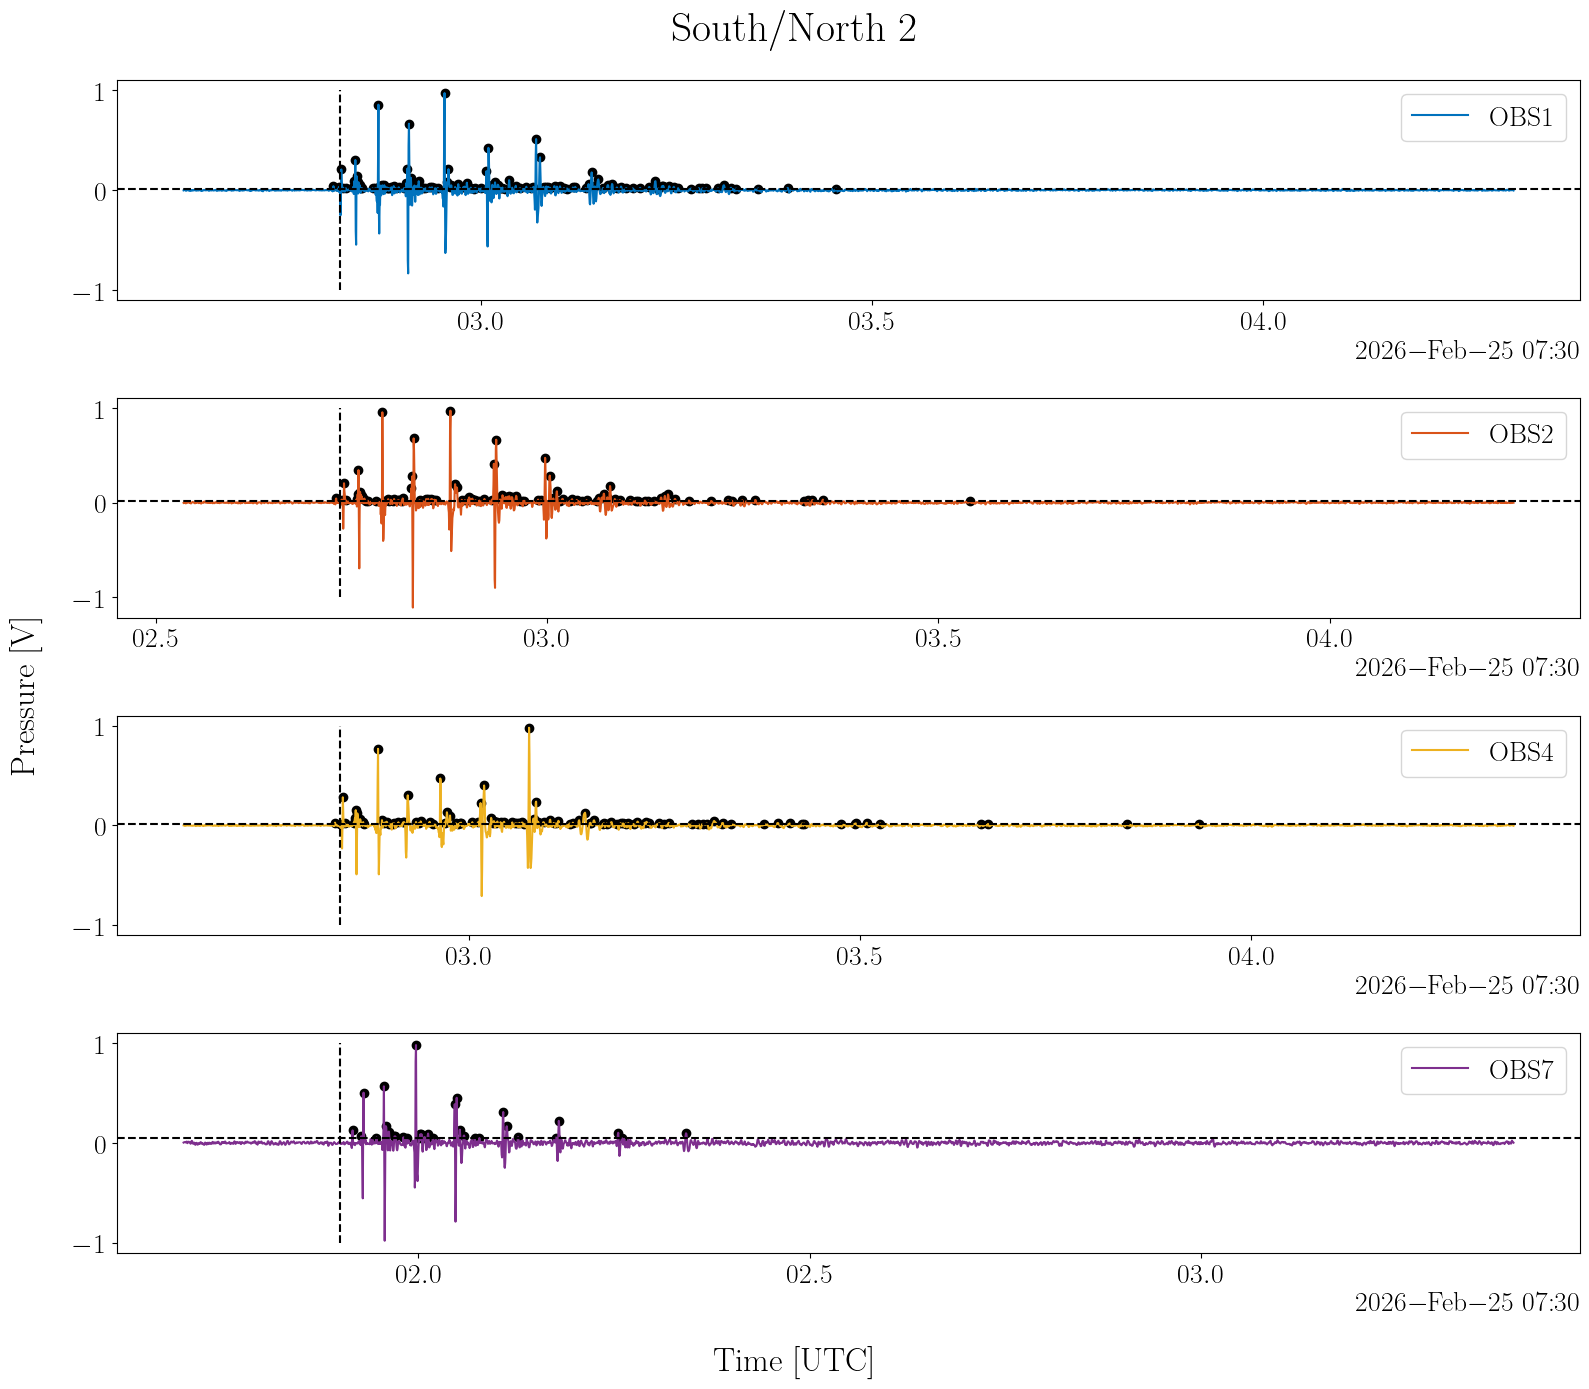

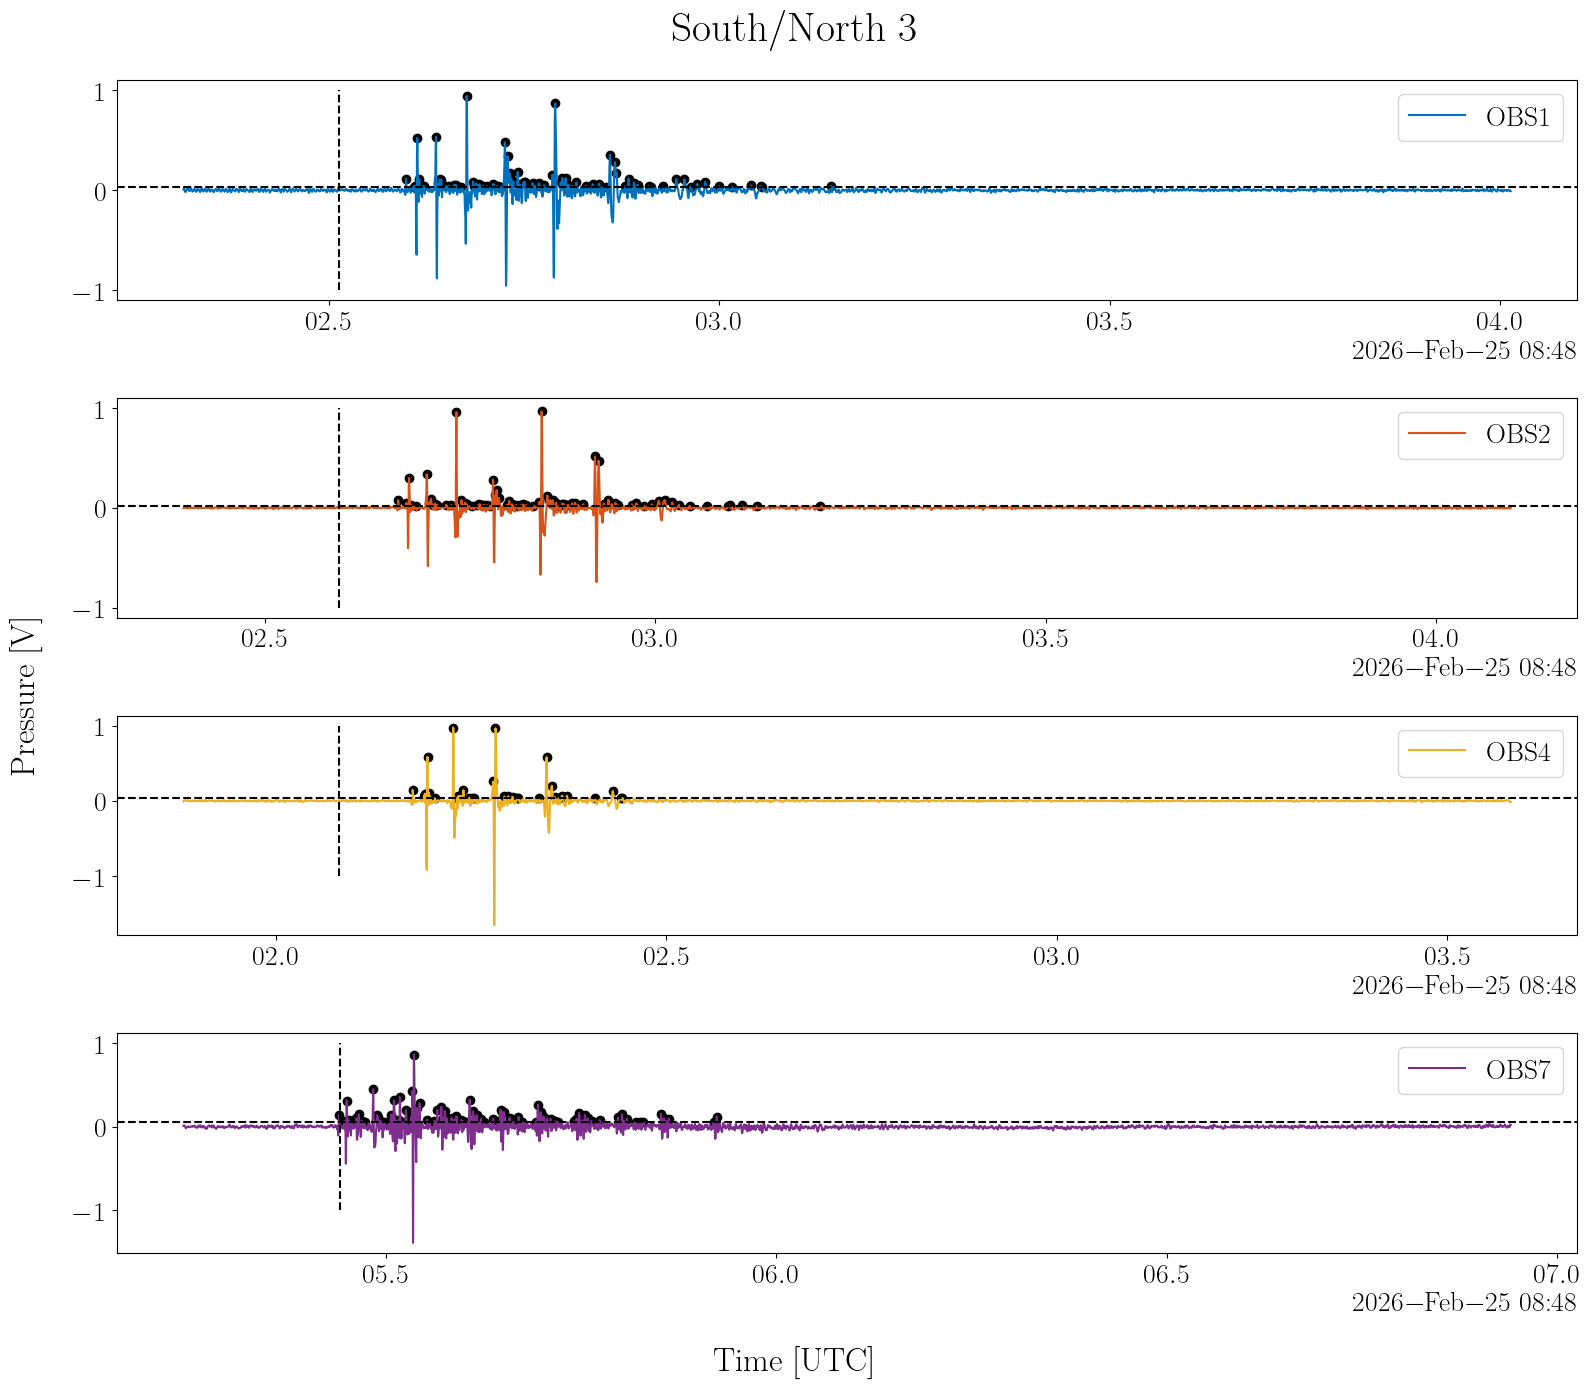

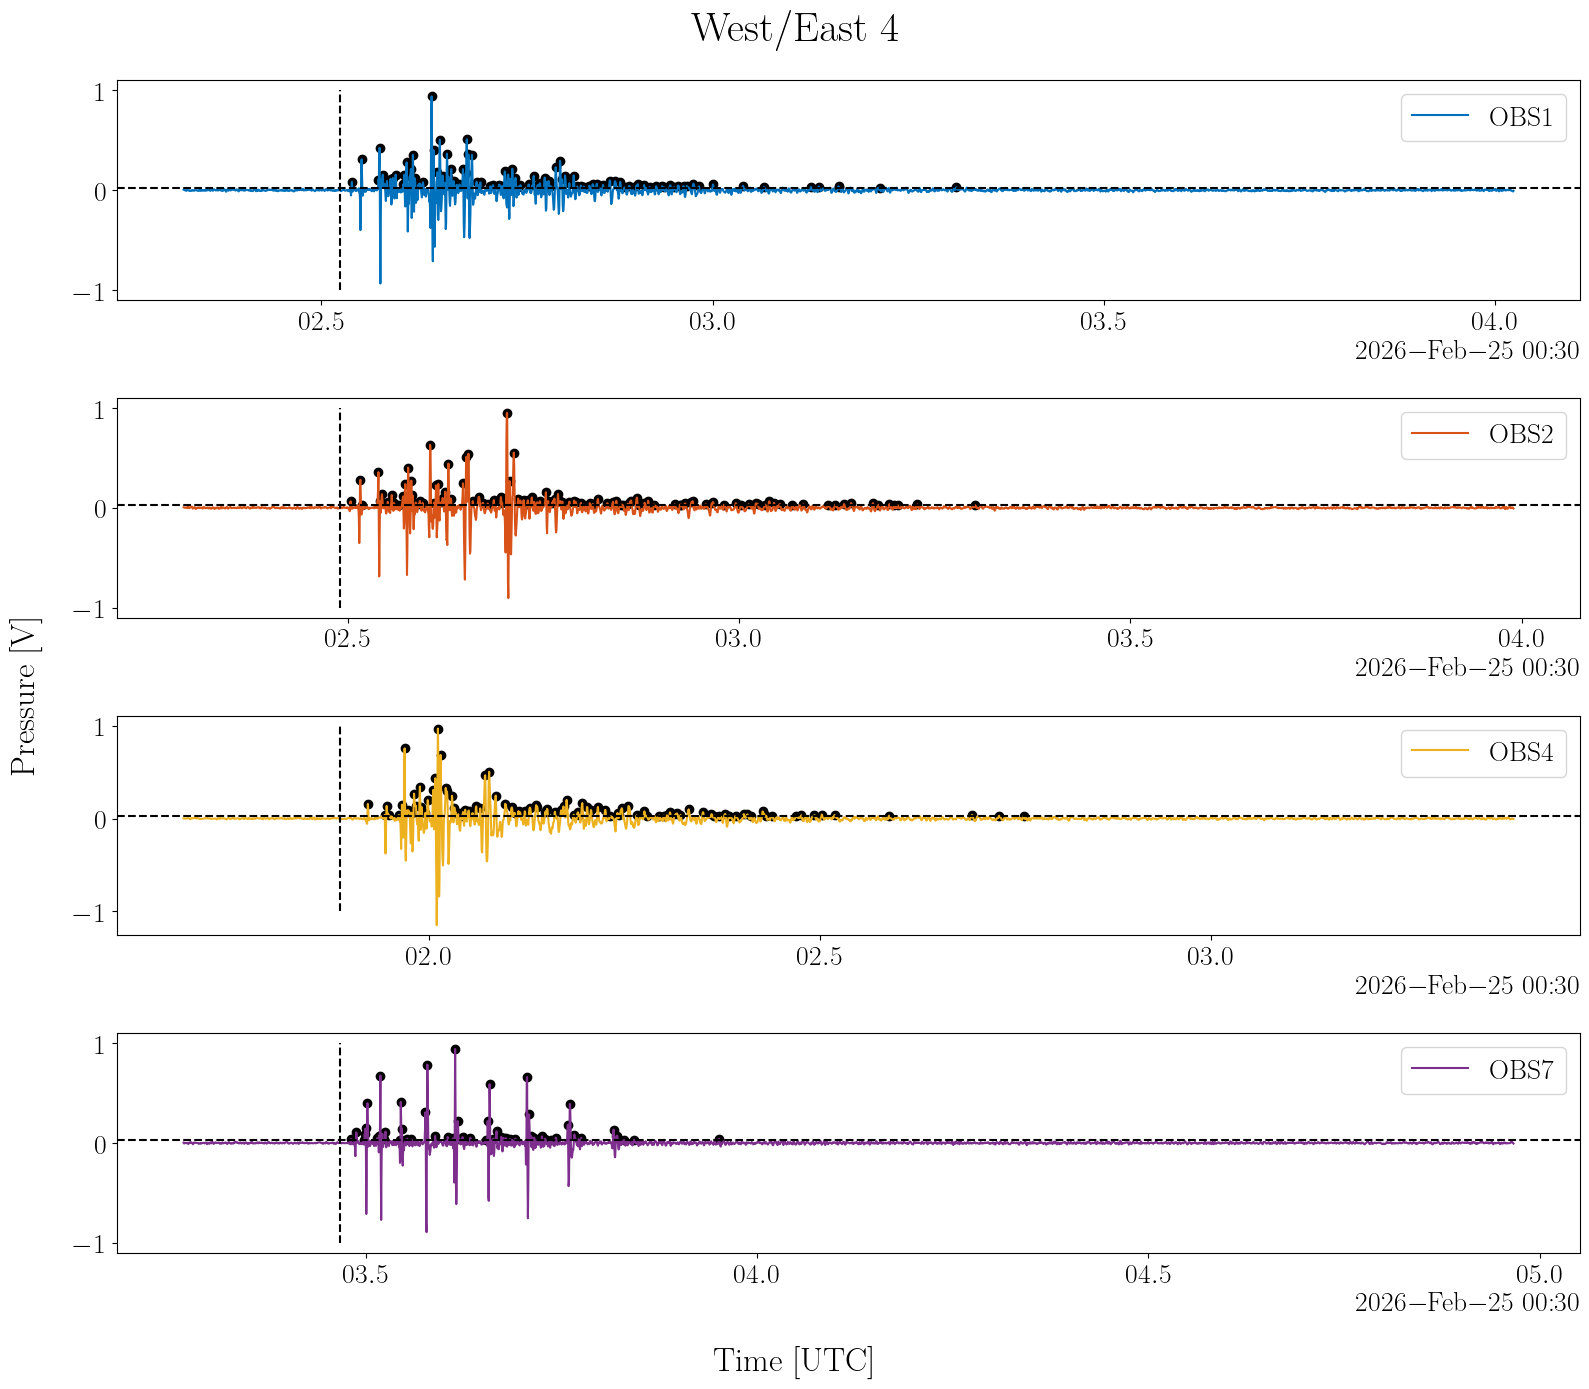

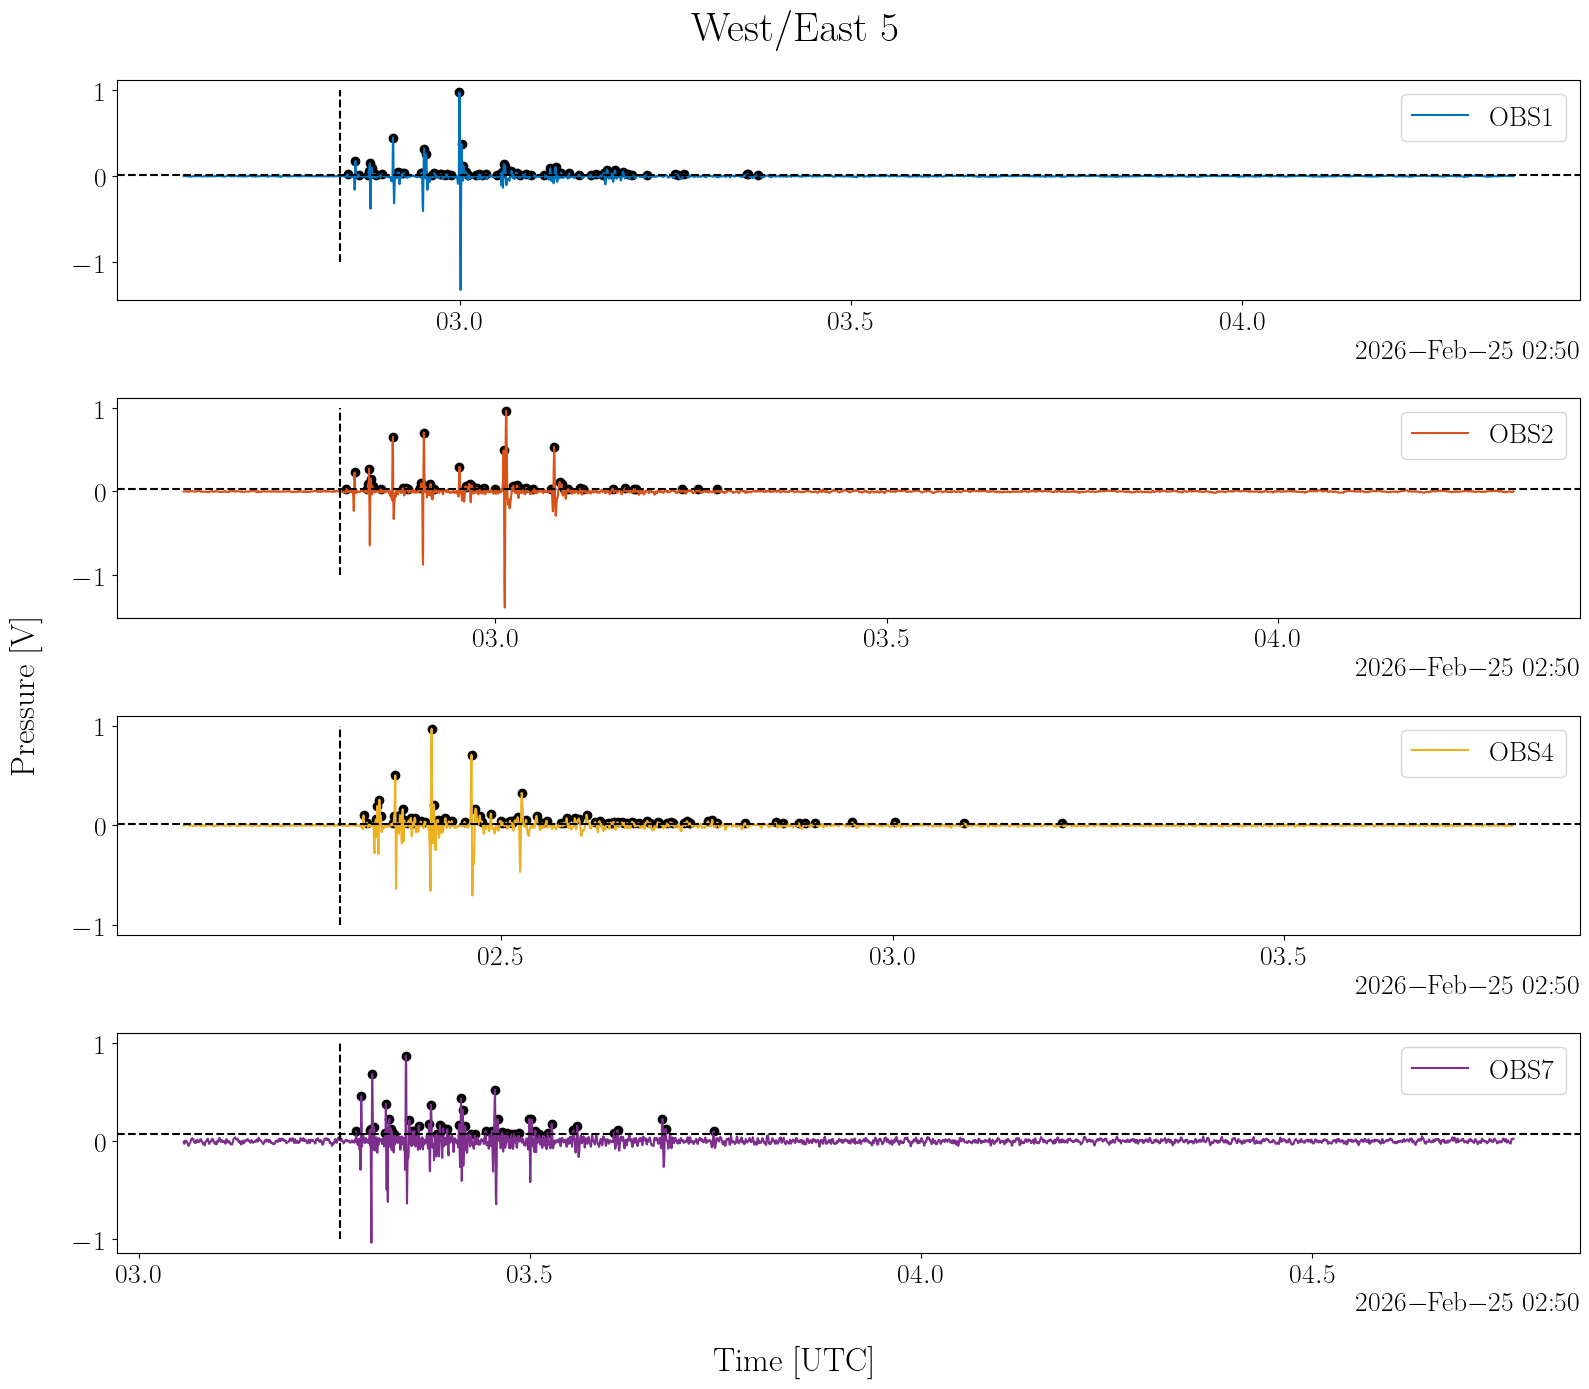

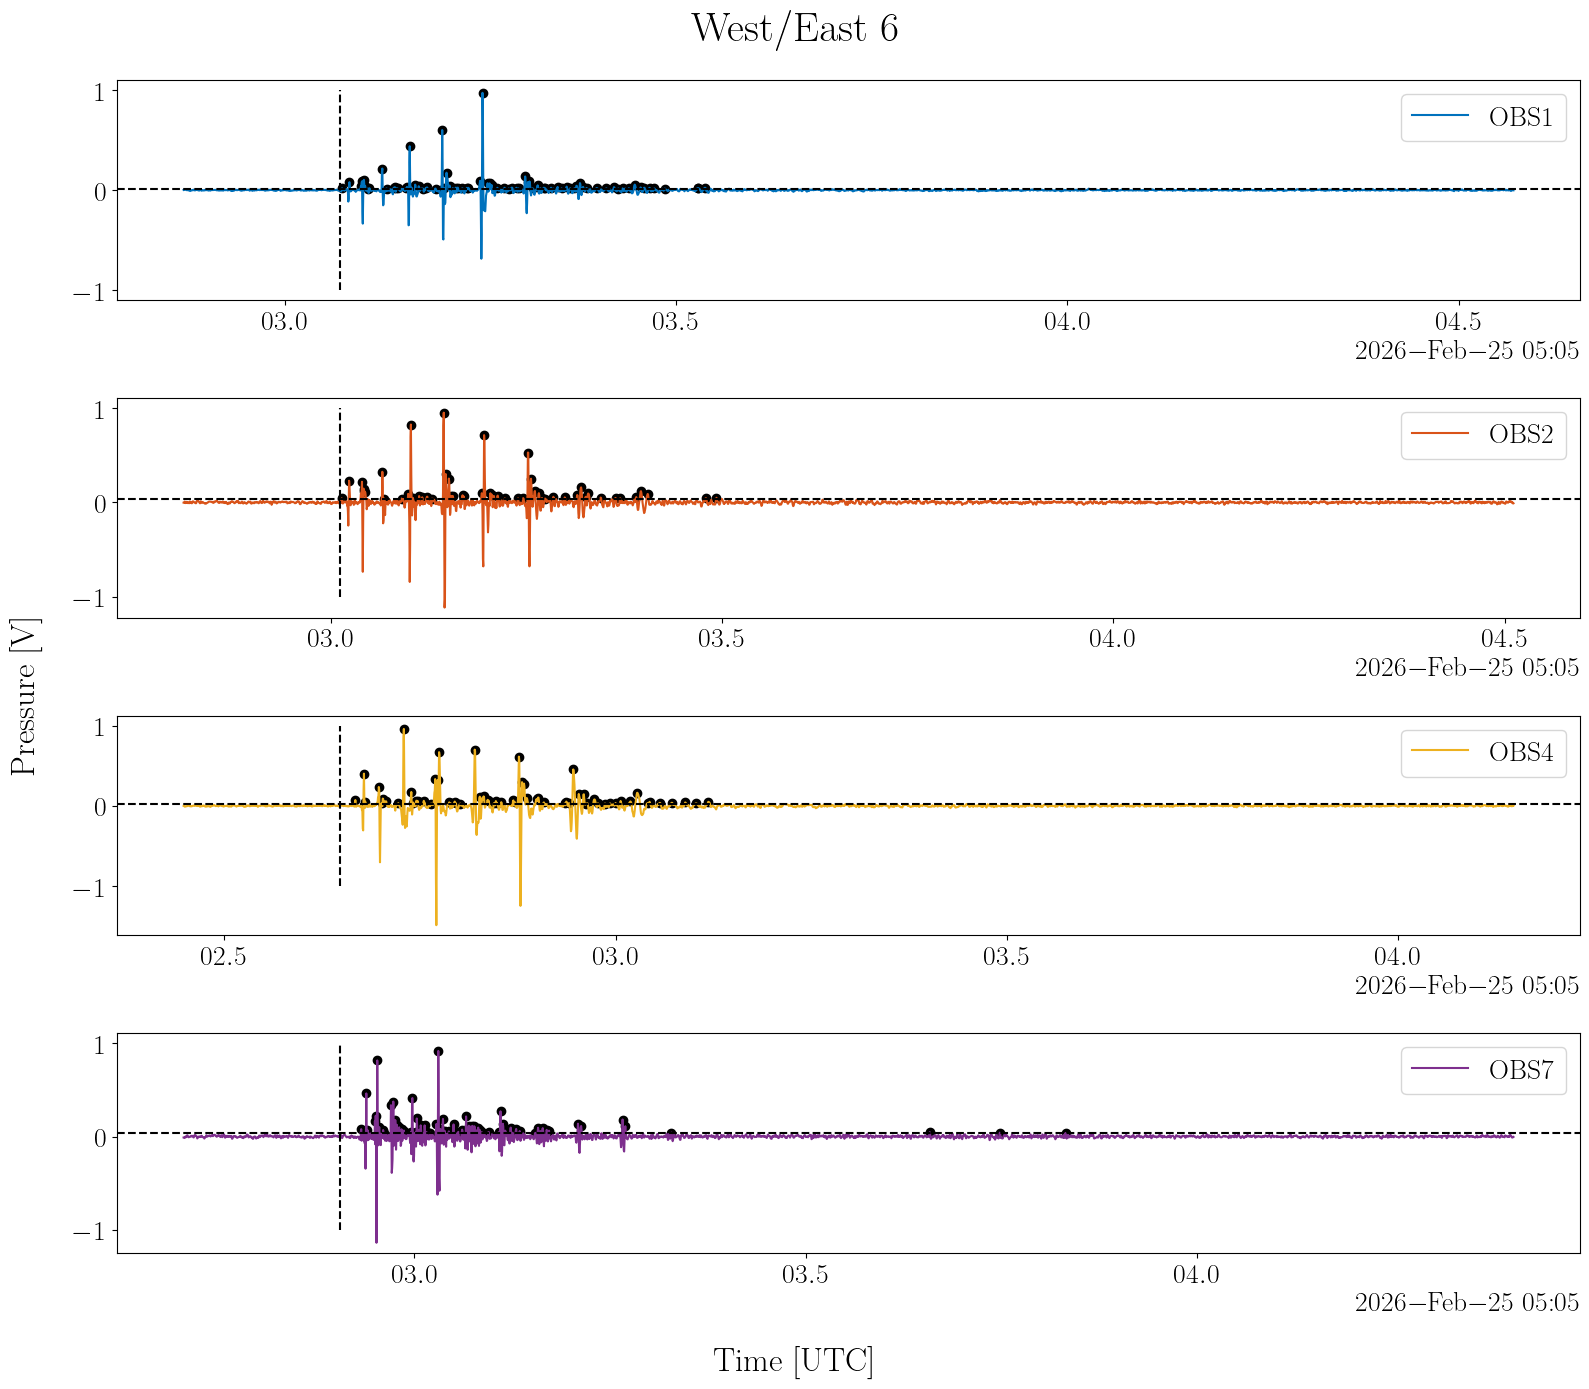

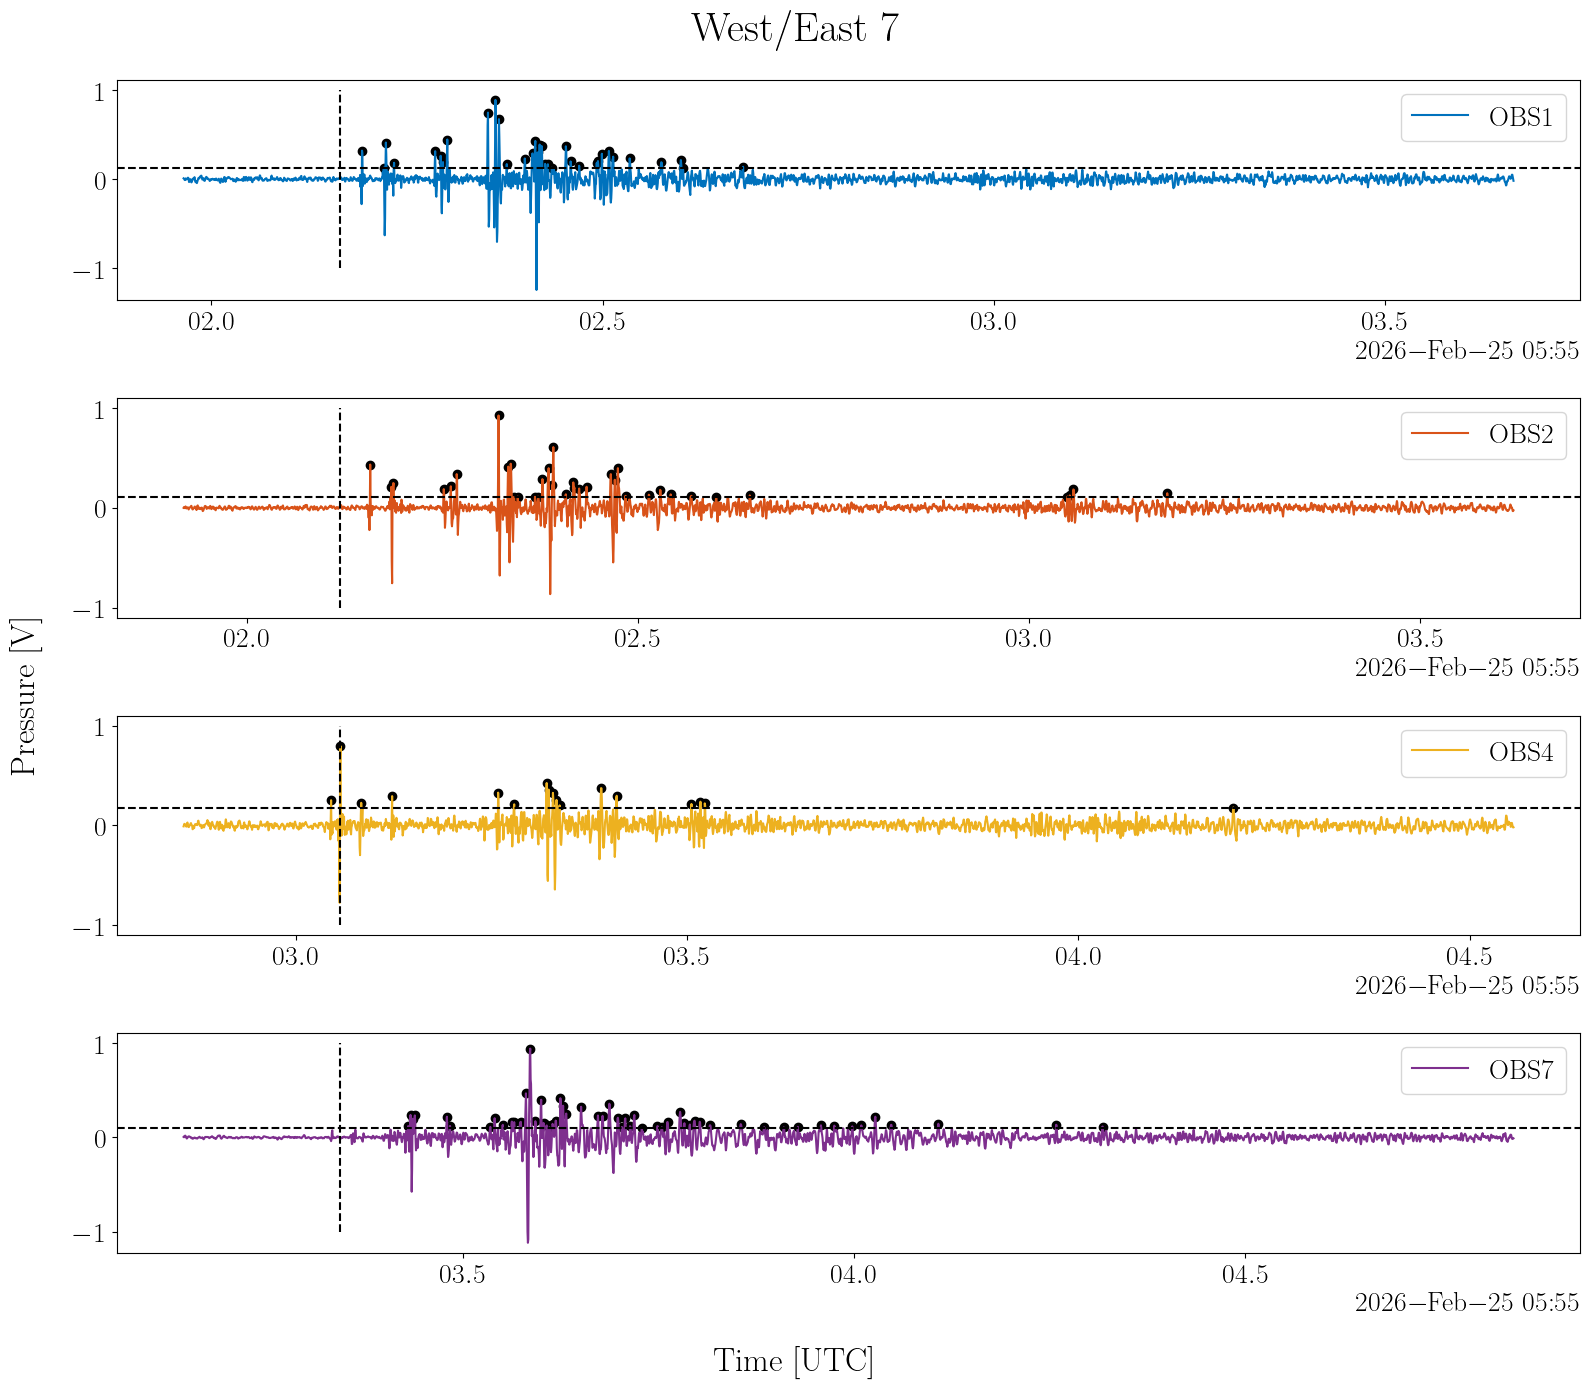

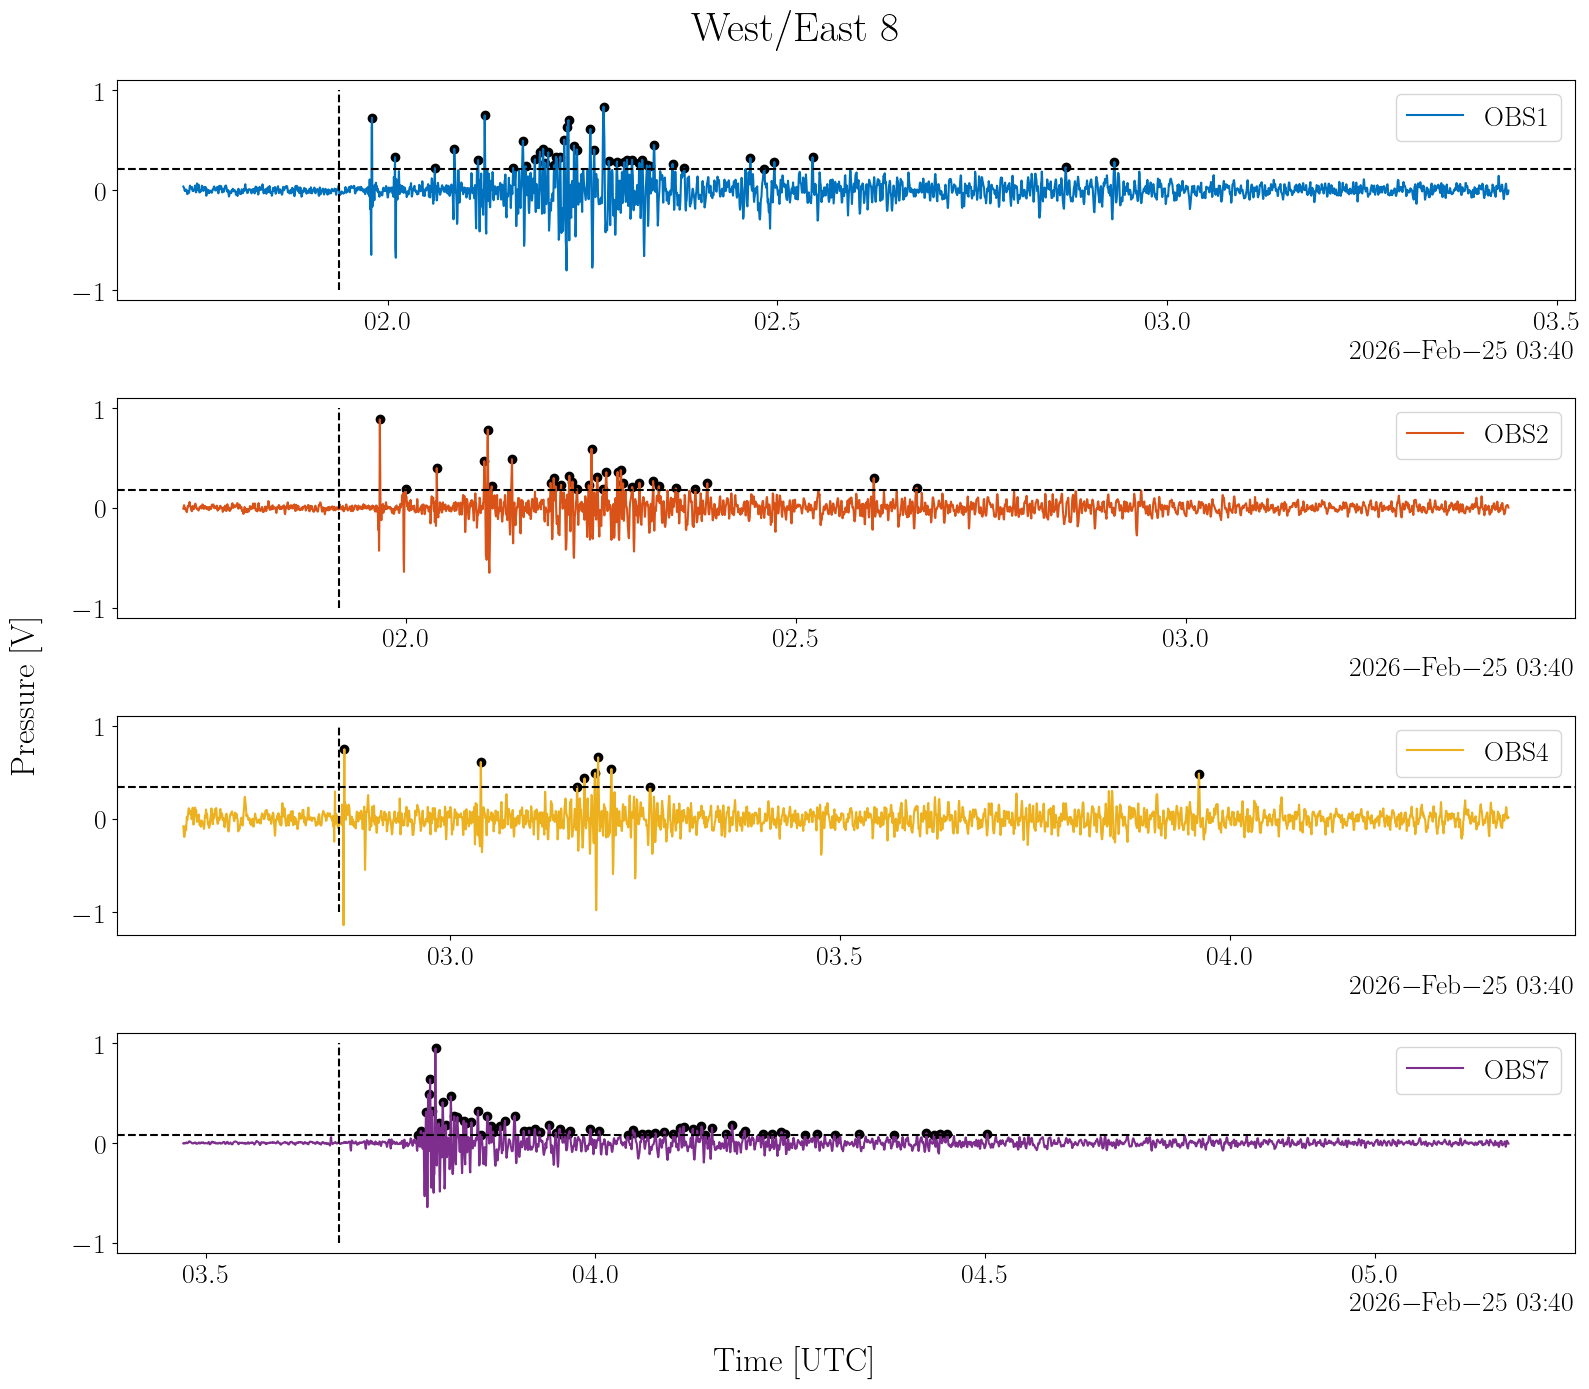

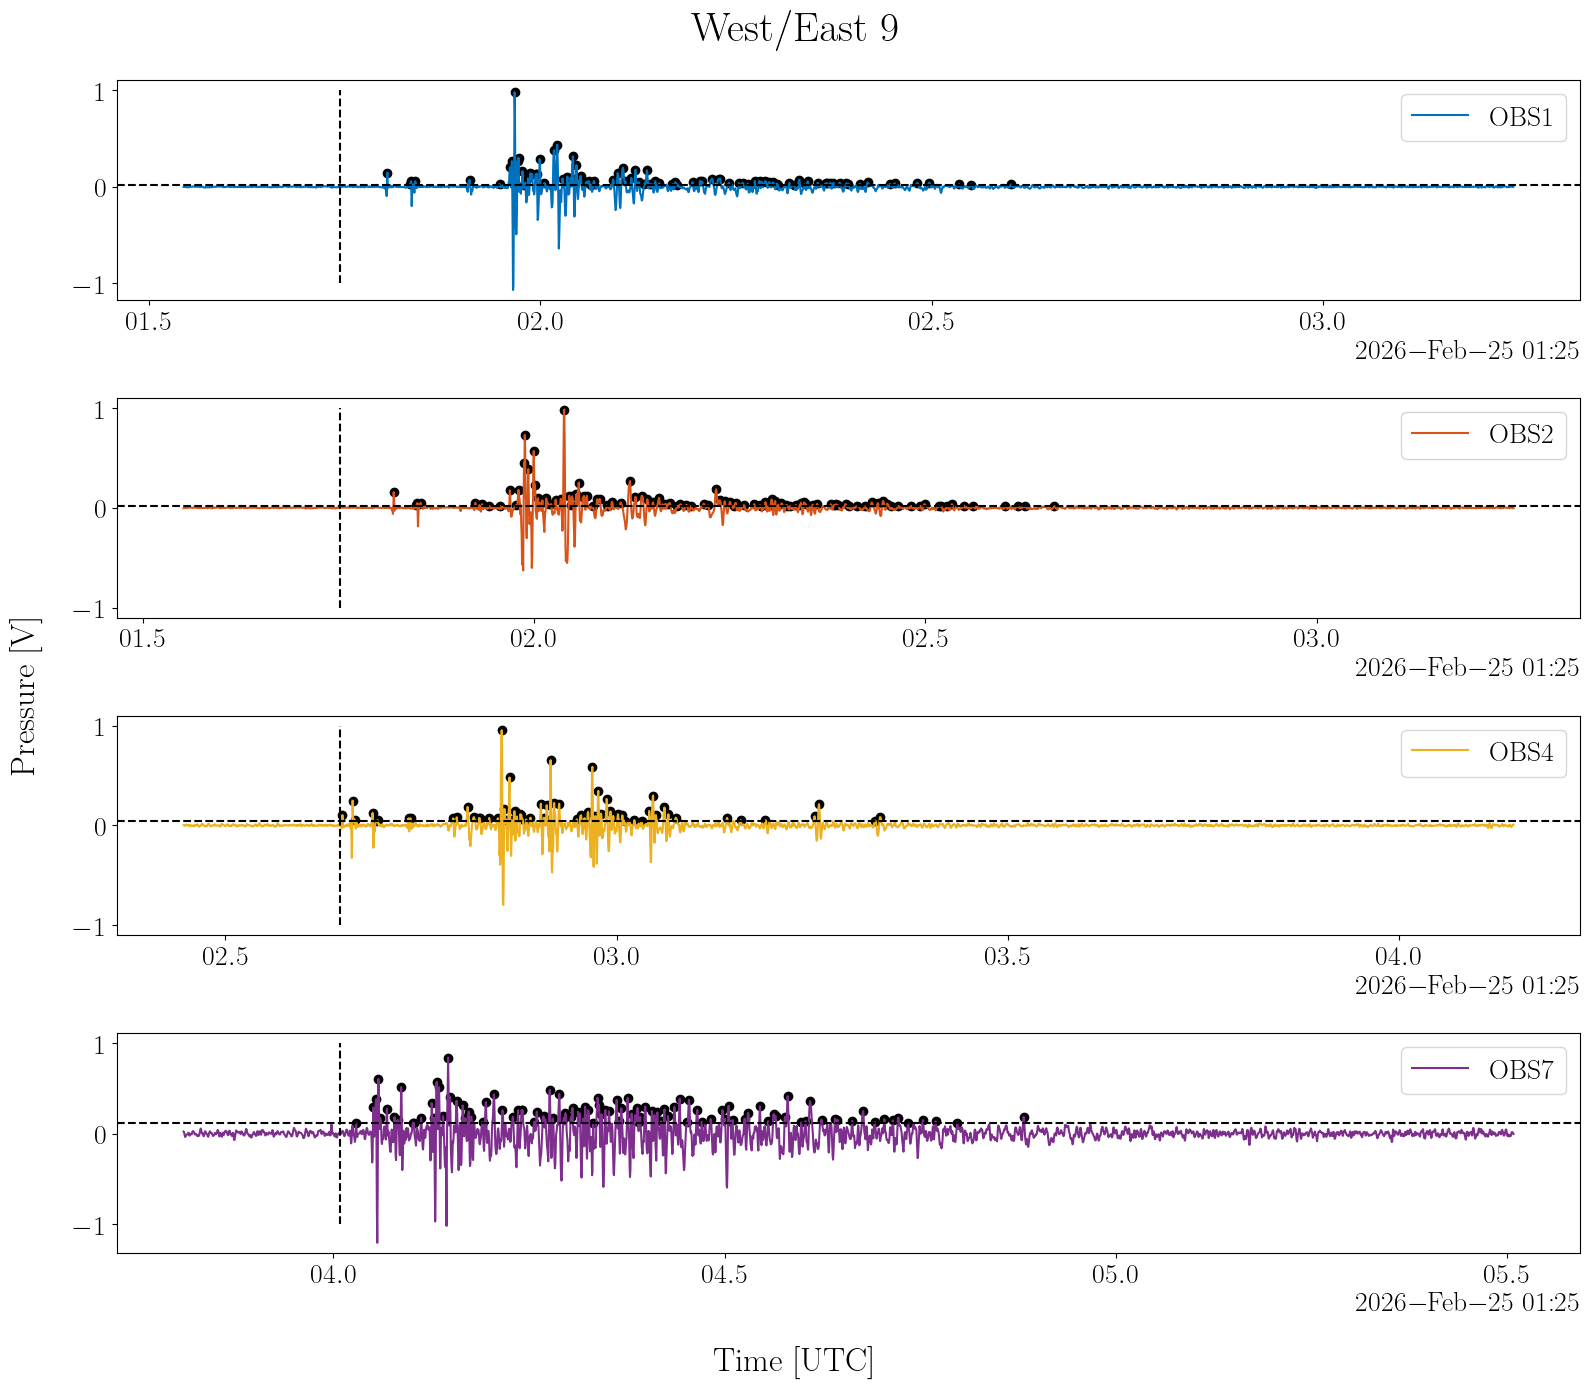

In [17]:
nb_tir = 1
offset1 = 200
offset2 = 1500

for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(
        src_datetime=slice(0, 0 + nb_tir)
    )

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel(
            {
                f"time_{rcv_id}": slice(
                    tir_dt_rcv.values[0] - np.timedelta64(offset1, "ms"),
                  tir_dt_rcv.values[-1] + np.timedelta64(offset2, "ms"),
                )
            }
        )
        # Plot pressure signal
        # Normalize
        press_rcv = press_rcv / press_rcv.max()
        press_rcv = press_rcv - press_rcv.mean()

        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")

        # Find peak
        peak_height = 5 * np.std(press_rcv.values[-100:])       # 5 times noise std seems like a reasonable choice 
        axs[i].axhline(peak_height, color="k", linestyle="--")
        peaks_idx, peaks_prop = sp.find_peaks(press_rcv, height=peak_height)
        # Plot peaks
        axs[i].scatter(
            press_rcv[f"time_{rcv_id}"].values[peaks_idx],
            press_rcv.values[peaks_idx],
            color="k",
        )
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(
        f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}"
    )
    fig.supxlabel(xlab)
    fig.supylabel(ylab)
    
    plt.show()

### Application à la portion 

In [18]:
obs_ids = ["obs1", "obs2", "obs4", "obs7"]
get_portion_tir_arr_dt(
    portion_tree=portion,
    offset1=200,
    offset2=1500,
    obs_ids=obs_ids,
)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_dat...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                     (rcv_id: 7, atl_datetime: 2313, mmsi: 521,
│   │                                        ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                      (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime                (atl_datetime) datetime64[ns] 19kB 2026-02-25...
│   │         * mmsi                        (mmsi) int64 4kB 4 127 128 129 ... 125 32 244
│   │         * ais_datetime                (ais_datetime) datetime64[ns] 2kB 2026-02-25T...
│   │         * src_datetime                (src_datetime) datetime64[ns] 6kB 2026-02-25T...
│   │       Data variables: (12/26)
│   │           rcv_lon                     (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                     (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion               (rcv_id) int16 14B 119 119 118 1077 306 91 93
│   │           rcv_lon_apriori             (rcv_id) float64 56B ...
│   │           rcv_lat_apriori             (rcv_id) float64 56B ...
│   │           rcv_immersion_apriori       (rcv_id) int16 14B ...
│   │           ...                          ...
│   │           tir_src_n                   (src_datetime) float64 6kB 3.011e+03 ... -3.2...
│   │           tir_src_u                   (src_datetime) float64 6kB 42.74 42.75 ... 42.61
│   │           rcv_e                       (rcv_id) float64 56B 369.1 409.1 ... 1.792e+03
│   │           rcv_n                       (rcv_id) float64 56B -1.081e+03 ... 3.375e+03
│   │           rcv_u                       (rcv_id) float64 56B -70.6 -70.58 ... -45.65
│   │           tps_propagation_measured_s  (rcv_id, src_datetime) float64 44kB 2.717 ......
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               4
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   ├── Group: /position/sn1
│   │       Dimensions:                     (rcv_id: 7, atl_datetime: 2120, mmsi: 521,
│   │                                        ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                      (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime                (atl_datetime) datetime64[ns] 17kB 2026-02-25...
│   │         * mmsi                        (mmsi) int64 4kB 4 127 128 129 ... 125 32 244
│   │         * ais_datetime                (ais_datetime) datetime64[ns] 2kB 2026-02-25T...
│   │         * src_datetime                (src_datetime) datetime64[ns] 6kB 2026-02-25T...
│   │       Data variables: (12/26)
│   │           rcv_lon                     (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                     (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion               (rcv_id) int16 14B 119 119 118 1077 306 91 93
│   │           rcv_lon_apriori             (rcv_id) float64 56B ...
│   │           rcv_lat_apriori             (rcv_id) float64 56B ...
│   │           rcv_immersion_apriori       (rcv_id) int16 14B ...
│   │           ...                          ...
│   │           tir_src_n                   (src_datetime) float64 6kB -3.106e+03 ... 3.2...
│   │           tir_src_u                   (src_datetime) float64 6kB 42.69 42.69 ... 42.65
│   │           rcv_e                       (rcv_id) float64 56B 369.1 409.1 ... 1.792e+03
│   │           rcv_n                       (rcv_id) float64 56B -1.081e+03 ... 3.375e+03
│   │  

Text(0.02, 0.5, 'Measured propagation time [s]')

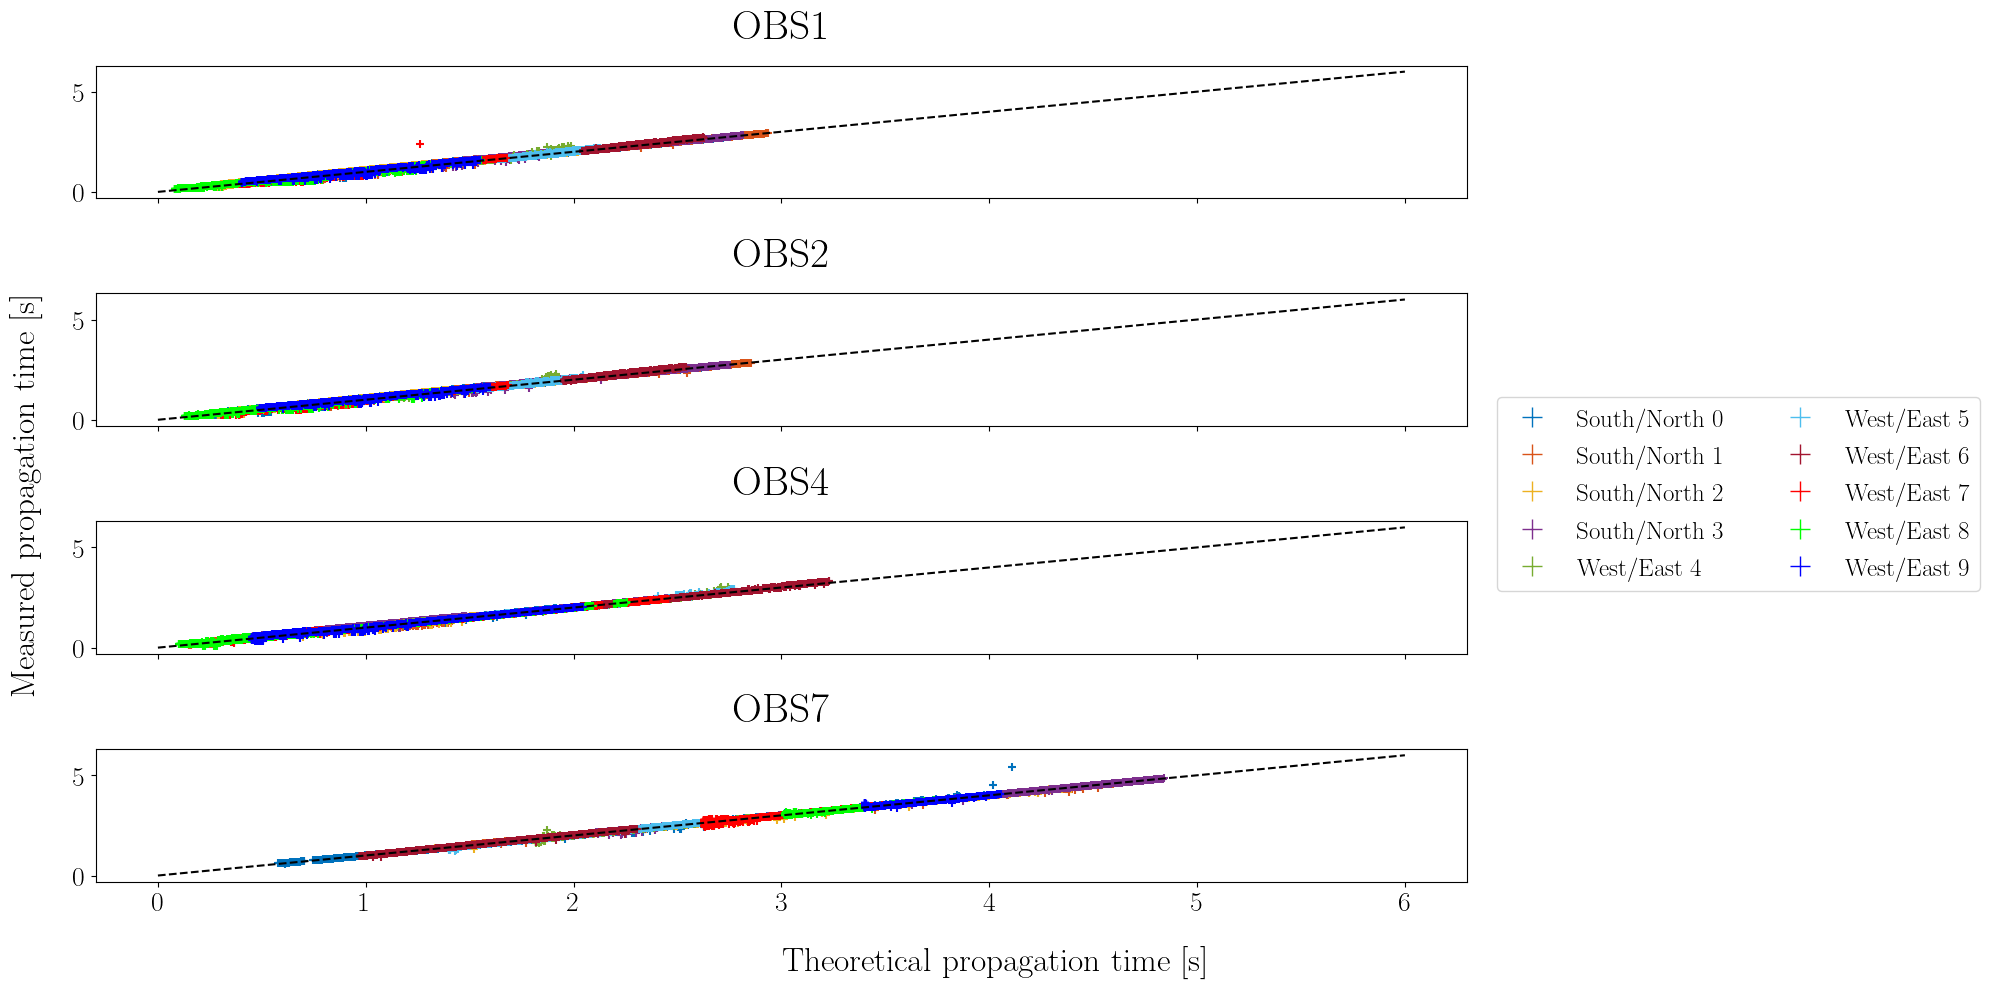

In [19]:
# fig, axs = plt.subplots(nrows=1, ncols=len(obs_ids), figsize=(16, 8), sharex=True, sharey=True)
fig, axs = plt.subplots(
    nrows=len(obs_ids), ncols=1, figsize=(20, 10), sharex=True, sharey=True
)

j = 0
legend_handles = []
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    for i, rcv_id in enumerate(obs_ids):
        ds_pos_section_rcv = ds_pos_section.sel(rcv_id=rcv_id)
        axs[i].scatter(
            ds_pos_section_rcv.tps_propagation_s,
            ds_pos_section_rcv.tps_propagation_measured_s,
            color=color(j),
            marker="+",
            s=30,
        )

    legend_handles.append(
        Line2D(
            [0],
            [0],
            linestyle="None",
            marker="+",
            markersize=15,
            label=f"{ds_pos_section.section_orientation} {ds_pos_section.section_id}",
            color=color(j),
        ),
    )
    j += 1

# Add ref diagonal
for i, rcv_id in enumerate(obs_ids):
    axs[i].plot(
        [0, 6],
        [0, 6],
        color="k",
        linestyle="--",
    )
    axs[i].set_title(rcv_id.upper())

fig.legend(
    handles=legend_handles,
    # loc="outside upper center",
    loc="outside center right",
    ncols=len(legend_handles) // 5,
    fontsize=18,
)
fig.supxlabel("Theoretical propagation time [s]")
fig.supylabel("Measured propagation time [s]")

Pour les OBS 1, 2, et 4 on observe un léger biais entre temps de propagation théorique et temps de propagation mesuré. Ce décalage est clairement visible sur les signaux. 

Le décalage observé entre temps de propagation théorique et temps de propagation mesuré évolue néanmoins en fonction de la position de la source pour l'OBS 7. Pour la séquence Sud/Nord 0, la source est d'abord proche de l'OBS 7 (faible temps de propagation) et le temps de propagation mesurée est plus faible que le temps de propagation théorique. À mi parcourt, les deux temps coïncident. À la fin de la trajectoire, la source est au sud de la zone et le temps de propagation mesurée est plus important que le temps de propagation théorique. 

Les trajectoires zonales présentent des variations similaires. Cette figure renforce l'hypothèse d'une position erronée pour l'OBS 7. 

## Application moindres carrés 

### Cas 2D

In [20]:
from misc import equivalent_celerity, calc_wls, draw_ellipse


def f2D(X, X_s, u_fixed):
    """
    X       : array [e, n], position horizontale de l'OBS à estimer
    X_s     : 2D array (npos, 3), positions [e, n, u] de la source
    u_fixed : float, coordonnée u de l'OBS, fixée (non estimée)
    """
    e, n = X
    e_s, n_s, u_s = X_s[:, 0], X_s[:, 1], X_s[:, 2]
    return (e - e_s) ** 2 + (n - n_s) ** 2 + (u_fixed - u_s) ** 2


def jac2D(X, X_s, u_fixed):
    """Jacobienne (npos, 2) : dérivées par rapport à e et n uniquement."""
    e, n = X
    e_s, n_s = X_s[:, 0], X_s[:, 1]
    df_de = 2 * (e - e_s)
    df_dn = 2 * (n - n_s)
    return np.array([df_de, df_dn]).T


def inverse_obs_loc2D(
    meas_prop_time,
    e_pos,
    n_pos,
    u_pos,
    e_obs,
    n_obs,
    u_obs,
    c0=1508,
    plot=True,
    verbose=False,
    ax=None,
    weights=None,
):

    y = (meas_prop_time * c0) ** 2

    # A priori : seulement e, n
    X_0 = np.array([e_obs, n_obs])  # (2,)
    X_s = np.stack((e_pos, n_pos, u_pos)).T  # (npos, 3)

    idx_nan = np.isnan(y * X_s[:, 0] * X_s[:, 1] * X_s[:, 2])
    y = y[~idx_nan]
    X_s = X_s[~idx_nan, :]

    if weights is None:
        W = np.eye(len(y))      # identity apriori cov matrix 
    else:
        W = np.diag(weights[~idx_nan])

    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = calc_wls(
        Y=y,
        t=X_s,
        X_0=X_0,
        W=W,
        fct=f2D,
        jac=jac2D,
        f_kwargs={"u_fixed": u_obs},
        jac_kwargs={"u_fixed": u_obs},
        tol=1e-6,
        verbose=False,
    )

    e_hat, n_hat = X_hat

    # print(f"True position : x = {e}, y = {n}, z = {u}")
    if verbose:
        print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
        print(f"Residuals : {dY_hat}")
        print(f"Final cost : {cost_hat}")
        print(SigmaXhat)

    if plot:
        if ax is None:
            fig, ax = plt.subplots()
        # Origine du repère locale
        ax.scatter(
            0,
            0,
            s=300,
            c="deeppink",
            marker="+",
            # edgecolors="black",
            linewidths=3,
            zorder=10,
            label="ENU frame origin",
        )

        # Position a priori
        ax.scatter(
            X_0[0],
            X_0[1],
            marker="*",
            s=100,
            color="b",
            label=r"$X_0$",
            zorder=2,
        )

        # Position estimée
        ax.scatter(
            X_hat[0],
            X_hat[1],
            marker="*",
            s=100,
            color="r",
            label=r"$\hat{X}$",
            zorder=2,
        )

        # Ellipse de confiance
        alpha = 0.95
        # nombre d'observations
        nobs = y.shape[0]
        # nombre de paramètres inconnus
        nparams = 2
        ddl = nobs - nparams
        draw_ellipse(
            X=X_hat[0:2],
            SigmaX=SigmaXhat[0:2, 0:2],
            ddl=ddl,
            alpha=alpha,
            title="",
            color="k",
            fac=1,
        )

        ax = plt.gca()
        ax.axis("equal")
        plt.xlabel("E [m]")
        plt.ylabel("N [m]")
        # plt.title(f"OBS{obs_id}")

    return X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat

In [21]:
# Build vectors
meas_prop_time = []
# prop_distance = []
e_pos = []
n_pos = []
u_pos = []

for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset().sel(rcv_id=obs_ids)
    meas_prop_time.append(ds_pos_section.tps_propagation_measured_s.values)
    # prop_distance.append(ds_pos_section.src_rcv_geodesic_dist.values)
    e_pos.append(ds_pos_section.tir_src_e.values)
    n_pos.append(ds_pos_section.tir_src_n.values)
    u_pos.append(ds_pos_section.tir_src_u.values)

meas_prop_time = np.hstack(meas_prop_time)
# prop_distance = np.hstack(prop_distance)
e_pos = np.hstack(e_pos)
n_pos = np.hstack(n_pos)
u_pos = np.hstack(u_pos)
e_obs = ds_pos_section.rcv_e.values
n_obs = ds_pos_section.rcv_n.values
u_obs = ds_pos_section.rcv_u.values

In [22]:
meas_prop_time

array([[2.716902, 2.721402, 2.707402, ..., 1.603902, 1.589902, 1.613902],
       [2.631402, 2.626402, 2.621402, ..., 1.645402, 1.650402, 1.654902],
       [2.894902, 2.890402, 2.885902, ..., 0.829402, 0.833402, 0.837402],
       [0.599902, 0.602402, 0.604902, ..., 4.059402, 4.056902,      nan]],
      shape=(4, 6342))

#### Sans poids a priori  

In [23]:
for i, rcv_id in enumerate(obs_ids):

    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
        meas_prop_time.copy()[i, :],
        e_pos,
        n_pos,
        u_pos,
        e_obs[i],
        n_obs[i],
        u_obs[i],
        c0=1508,
        plot=False,
        verbose=False,
        ax=None,
        weights=None,
    )

    # print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
    # print(f"Residuals : {dY_hat}")
    print(f"Final cost : {cost_hat}")
    print(SigmaXhat)
    
    pos_err = np.sqrt((X_hat[0] - e_obs[i]) ** 2 + (X_hat[1] - n_obs[i]) ** 2)
    print(f"Erreur de positionnement {rcv_id.upper()} : {pos_err} m")

Final cost : 705673834005614.5
[[2.90296509 0.24711368]
 [0.24711368 1.2604352 ]]
Erreur de positionnement OBS1 : 2.982623651673561 m
Final cost : 562890814497780.6
[[2.25704935 0.19807009]
 [0.19807009 1.0897414 ]]
Erreur de positionnement OBS2 : 2.1653024121060795 m
Final cost : 428082262687456.56
[[ 1.37586795 -0.45667718]
 [-0.45667718  0.94960188]]
Erreur de positionnement OBS4 : 0.41505761942372327 m
Final cost : 2067456470649568.0
[[ 8.48523775 -3.39135694]
 [-3.39135694  2.35486691]]
Erreur de positionnement OBS7 : 15.026772930639225 m


In [24]:
meas_prop_time

array([[2.716902, 2.721402, 2.707402, ..., 1.603902, 1.589902, 1.613902],
       [2.631402, 2.626402, 2.621402, ..., 1.645402, 1.650402, 1.654902],
       [2.894902, 2.890402, 2.885902, ..., 0.829402, 0.833402, 0.837402],
       [0.599902, 0.602402, 0.604902, ..., 4.059402, 4.056902,      nan]],
      shape=(4, 6342))

#### Avec poids a priori  

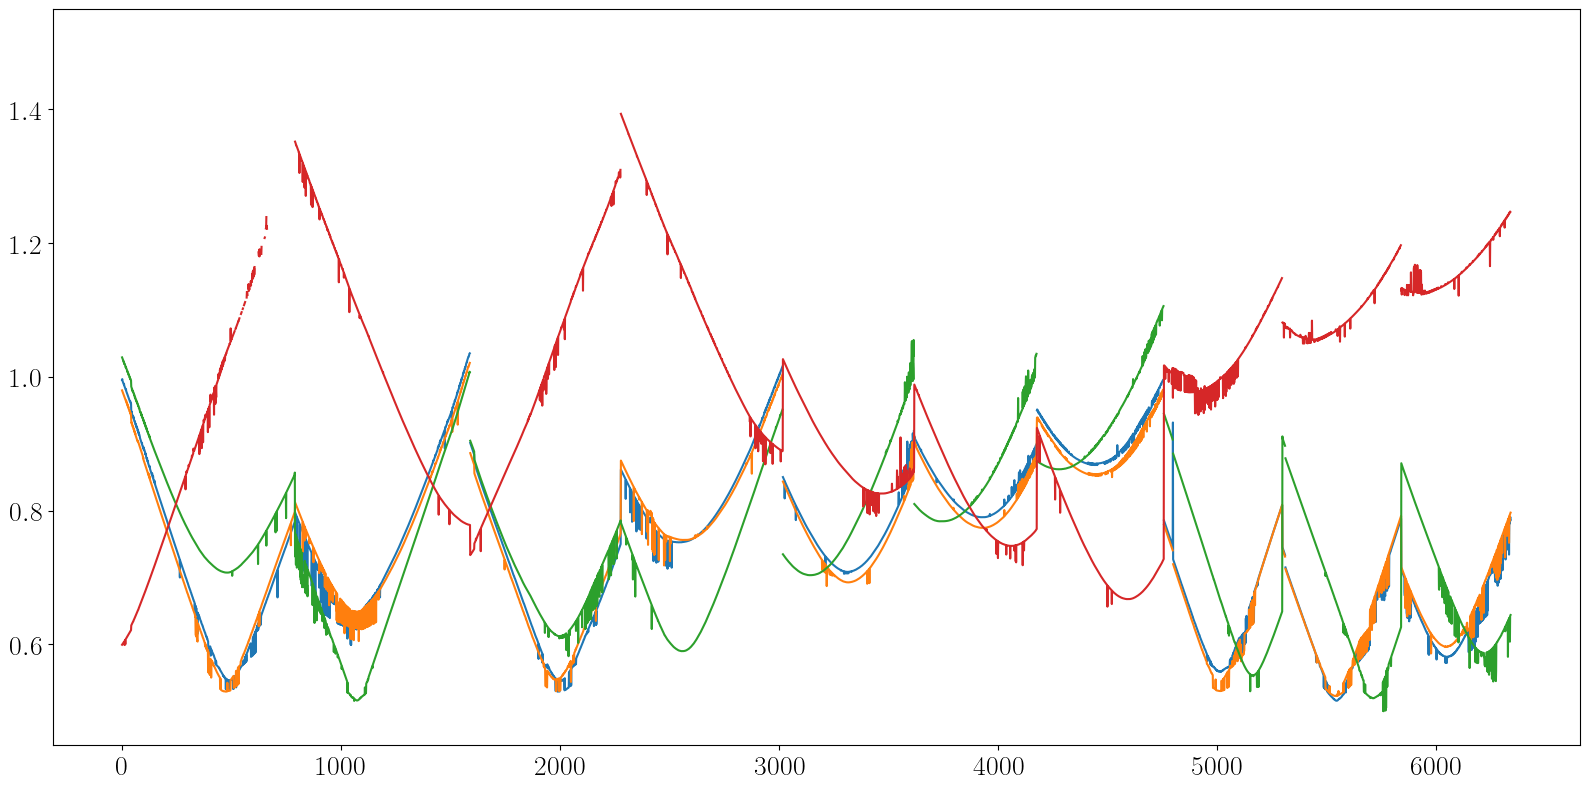

In [25]:
# Compute weights 
w = meas_prop_time.copy()
w = (w - np.nanmin(w)) / (np.nanmax(w) - np.nanmin(w)) + 0.5
# w = w
w

plt.figure()
for i in range(w.shape[0]):
    plt.plot(w[i, :])

In [26]:
w.shape, meas_prop_time.shape

((4, 6342), (4, 6342))

In [27]:
for i, rcv_id in enumerate(obs_ids):

    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
        meas_prop_time.copy()[i, :],
        e_pos,
        n_pos,
        u_pos,
        e_obs[i],
        n_obs[i],
        u_obs[i],
        c0=1508,
        plot=False,
        verbose=False,
        ax=None,
        weights=w[i, :]
    )

    # print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
    # print(f"Residuals : {dY_hat}")
    print(f"Final cost : {cost_hat}")
    print(SigmaXhat)
    
    pos_err = np.sqrt((X_hat[0] - e_obs[i]) ** 2 + (X_hat[1] - n_obs[i]) ** 2)
    print(f"Erreur de positionnement {rcv_id.upper()} : {pos_err} m")

Final cost : 573398733392802.8
[[2.97073905 0.26449894]
 [0.26449894 1.19656205]]
Erreur de positionnement OBS1 : 6.7331752575476065 m
Final cost : 448482168645069.6
[[2.27496158 0.21305005]
 [0.21305005 1.029843  ]]
Erreur de positionnement OBS2 : 1.5307120572969757 m
Final cost : 376963561435309.8
[[ 1.46294375 -0.53279774]
 [-0.53279774  1.00938607]]
Erreur de positionnement OBS4 : 4.485028550488861 m
Final cost : 2540296675002744.5
[[10.75386467 -4.2763807 ]
 [-4.2763807   2.81426523]]
Erreur de positionnement OBS7 : 22.086716519261163 m


Text(0, 0.5, 'N [m]')

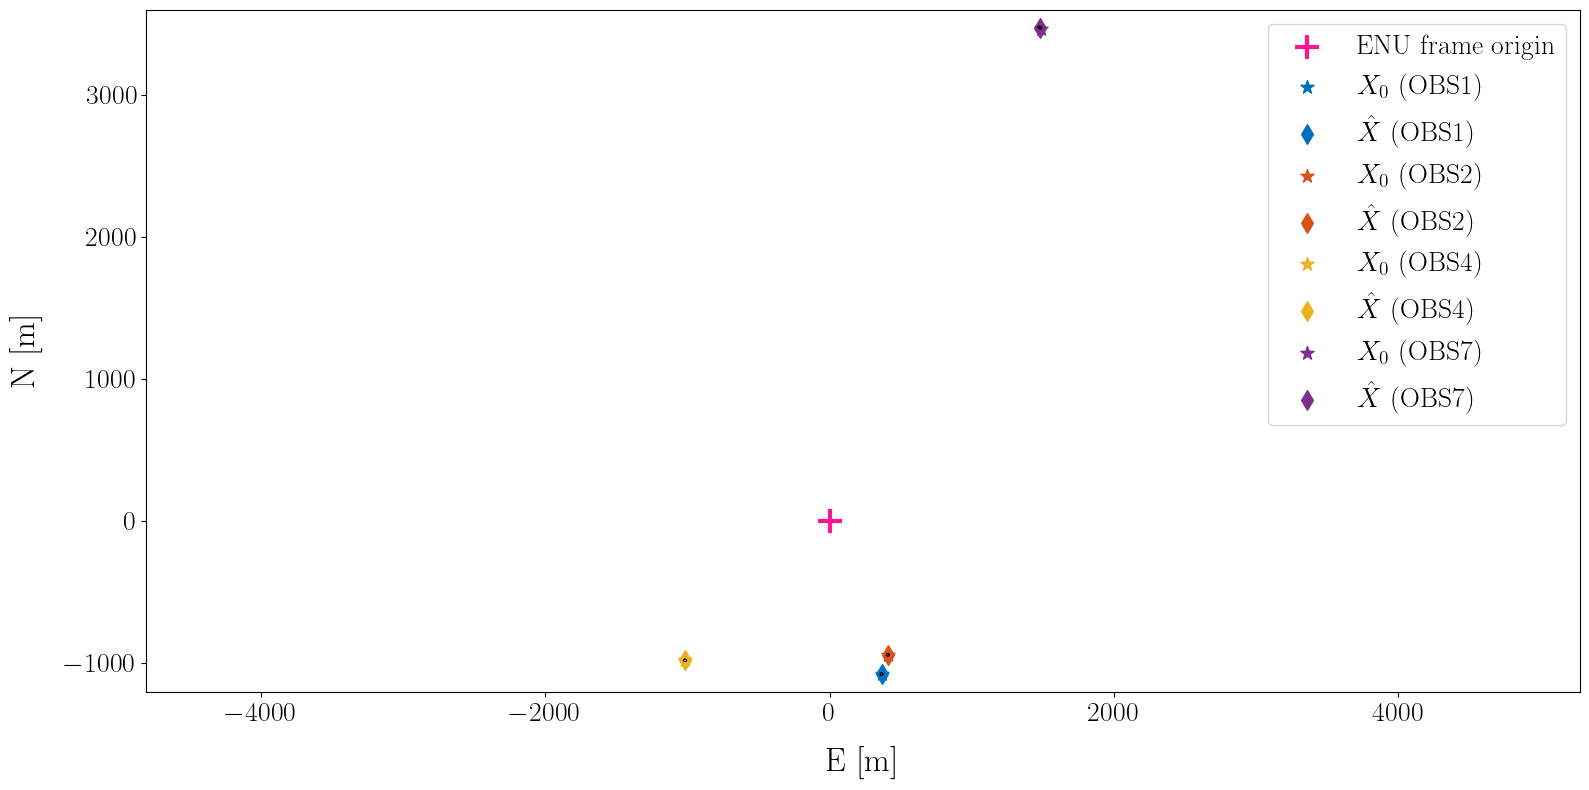

In [28]:
fig, ax = plt.subplots()

# Origine du repère locale
ax.scatter(
    0,
    0,
    s=300,
    c="deeppink",
    marker="+",
    # edgecolors="black",
    linewidths=3,
    zorder=10,
    label="ENU frame origin",
)

rcv_corrected_pos = {}

for i, rcv_id in enumerate(obs_ids):

    X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
        meas_prop_time[i,:],
        e_pos,
        n_pos,
        u_pos,
        e_obs[i],
        n_obs[i],
        u_obs[i],
        c0=1508,
        plot=False,
        verbose=False,
        ax=None,
    )

    # Store corrected position
    rcv_corrected_pos[rcv_id] = {"e": X_hat[0], "n": X_hat[1], "u": u_obs[i]}

    # Position a priori
    ax.scatter(
        e_obs[i],
        n_obs[i],
        marker="*",
        s=100,
        color=color(i),
        label=r"$X_0$" + f" ({rcv_id.upper()})",
        zorder=2,
    )

    # Position estimée
    ax.scatter(
        X_hat[0],
        X_hat[1],
        marker="d",
        s=100,
        color=color(i),
        label=r"$\hat{X}$" + f" ({rcv_id.upper()})",
        zorder=2,
    )

    # Ellipse de confiance
    alpha = 0.95
    # nombre d'observations
    nobs = meas_prop_time[i, :].shape[0]
    # nombre de paramètres inconnus
    nparams = 2
    ddl = nobs - nparams
    draw_ellipse(
        X=X_hat[0:2],
        SigmaX=SigmaXhat[0:2, 0:2],
        ddl=ddl,
        alpha=alpha,
        title="",
        color="k",
        fac=1,
    )

ax.axis("equal")
plt.xlabel("E [m]")
plt.ylabel("N [m]")
# plt.title(f"OBS{obs_id}")

L'erreur de positionnement est plus importante pour l'OBS 7 et la correction de position coïncide avec celle prédite en analysant les temps d'arrivées. 

Une remarque sur l'ordre de grandeur de l'erreur de positionnement : par défaut le positionnement dans le référentiel WGS84 ne peut être plus précis qu'environ 5m (l'ordre de grandeur de l'incertitude de positionnement GPS standard). 

Erreur de positionnement OBS1 : 106.41879375327304 m
Erreur de positionnement OBS2 : 71.67188226876789 m
Erreur de positionnement OBS4 : 98.06523069610574 m
Erreur de positionnement OBS7 : 356.35033561546925 m

Pour les OBS 1, 2 et 4 l'ordre de grandeur de l'erreur de position est de 100 m. La vitesse de chute des OBS est d'environ 1m/s (d'après la doc capteur), à cette vitesse cela pourrait correspondre à l'effet d'un courant de l'ordre de 1m/s. 

On peut consulter la carte de courant de surface du modèle MARS3D de l'Ifremer pour la zone à l'adresse : https://marc.ifremer.fr/resultats/courants/modele_mars3d_mediterranee/(typevisu)/map/(zoneid)/lion#appTop
Le jour du déploiement, le 24/02/2026 (à vérifier), on observe un courant de surface de 0.8 à 0.9 m/s orienté d'Est en Ouest qui longe la côte. La direction et l'intensité de ce courant pourrait être cohérent avec la trajectoire de repositionnement des OBS. Ce courant est un courant connu sous le nom de courant Liguro-Provençal et est présent toute l’année (cf. https://marc.ifremer.fr/comment_ca_marche/modele_mars3d_mediterranee) 

Quelques points sont cependant à préciser :

* Le modèle ne décrit que les courants de surface
* Le courant proche de la côte, là où sont déployé les capteurs, est nettement plus faible sur le modèle 
* Au déplacement lors de la chute de l'OBS s'ajoute l'incertitude de positionnement GPS. 

Pour plus d'infos on peut regarder les données de courants du modèle Mediterranean Sea Physics Reanalysis (Mediterranean Sea Physics Reanalysis) : les figures et animations de courant dans la zone sont données dans le dossier dédié C:\Users\baptiste.menetrier\Desktop\devPy\download_cmems\acouplane\img

On peut supposer que la date de remonté coïncide avec la fin de l'enregistrement (à confirmer)

OBS1: start = 2026-02-24 13:40, end = 2026-03-02 08:00
OBS2: start = 2026-02-24 12:45, end = 2026-02-26 06:25
OBS4: start = 2026-02-24 13:00, end = 2026-03-02 07:00
OBS5: start = 2026-02-24 16:00, end = 2026-03-01 11:30
OBS6: start = 2026-02-24 16:30, end = 2026-03-01 10:15
OBS7: start = 2026-02-24 09:30, end = 2026-03-01 07:34

La question est de savoir à quoi corresponde les positions GPS : position à la mise à l'eau / position à la remonter ? 

**Discussion avec Bazile** 
Les positions sont normalement celles prises lors de la mise à l'eau des OBS. Le bras de levier entre l'antenne GPS située à l'avant du bateau et le pont arrière (là où sont mis à l'eau les capteurs) n'est pas nécessairement pris en compte. L'ATALANTE mesure 85 mètre de long (longueur hors tout d'après https://www.flotteoceanographique.fr/Nos-moyens/Navires-engins-et-equipements-mobiles/Navires-hauturiers/L-Atalante/Caracteristiques-detaillees). Ce bras de levier pourrait ainsi suffire à expliquer les erreurs de positionnement mesurées sur les OBS 1, 2 et 4. 



#### Impact de l'immersion a priori 

In [29]:
# correction_u = np.linspace(-50, +50, 100)
# cost_hat_u = []
# for i, rcv_id in enumerate(obs_ids):

#     cost_hat_u_ = []
#     for i_corr, corr_u in enumerate(correction_u):

#         X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
#             meas_prop_time[i, :],
#             e_pos,
#             n_pos,
#             u_pos,
#             e_obs[i],
#             n_obs[i],
#             u_obs[i] + corr_u,
#             c0=1508,
#             plot=False,
#             verbose=False,
#             ax=None,
#         )

#         # print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
#         # print(f"Residuals : {dY_hat}")
#         # print(f"Final cost : {cost_hat}")
#         cost_hat_u_.append(cost_hat)

#     cost_hat_u.append(cost_hat_u_)
# cost_hat_u = np.array(cost_hat_u)

In [30]:
# fig, axs = plt.subplots(len(obs_ids), 1, figsize=(16, 8))
# for i, rcv_id in enumerate(obs_ids):
#     axs[i].plot(
#         correction_u,
#         cost_hat_u[i, :],
#         label=rcv_id.upper(),
#         color=color(i),
#     )
#     # axs[i].plot(
#     #     correction_u,
#     #     (cost_hat_u[i, :] - np.min(cost_hat_u[i, :])) / (np.max(cost_hat_u[i, :]) - np.min(cost_hat_u[i, :])),
#     #     label=rcv_id.upper(),
#     #     color=color(i),
#     # )
#     axs[i].legend()

Pas de minimum et pas de variations significatives. Pas de correction à apporter à la coordonnée u.


#### Impact de la célérité a priori 

In [31]:
# c0_ = np.linspace(1495, 1510, 100)
# cost_hat_c0 = []
# for i, rcv_id in enumerate(obs_ids):

#     cost_hat_c0_ = []
#     for i_corr, c0 in enumerate(c0_):

#         X_hat, dY_hat, cost_hat, SigmaXhat, sigma02hat = inverse_obs_loc2D(
#             meas_prop_time[i, :],
#             e_pos,
#             n_pos,
#             u_pos,
#             e_obs[i],
#             n_obs[i],
#             u_obs[i],
#             c0=c0,
#             plot=False,
#             verbose=False,
#             ax=None,
#         )

#         # print(f"Estimated position : e = {X_hat[0]}, n = {X_hat[1]}")
#         # print(f"Residuals : {dY_hat}")
#         # print(f"Final cost : {cost_hat}")
#         cost_hat_c0_.append(cost_hat)

#     cost_hat_c0.append(cost_hat_c0_)
# cost_hat_c0 = np.array(cost_hat_c0)

In [32]:
# fig, axs = plt.subplots(len(obs_ids), 1, figsize=(16, 8))
# for i, rcv_id in enumerate(obs_ids):
#     axs[i].plot(
#         c0_,
#         cost_hat_c0[i, :],
#         label=rcv_id.upper(),
#         color=color(i),
#     )
#     # axs[i].plot(
#     #     correction_u,
#     #     (cost_hat_u[i, :] - np.min(cost_hat_u[i, :])) / (np.max(cost_hat_u[i, :]) - np.min(cost_hat_u[i, :])),
#     #     label=rcv_id.upper(),
#     #     color=color(i),
#     # )
#     axs[i].legend()

Pas de minimum et pas de variations significatives.

Est ce que cela a vraiment du sens de regarder les variations de coût total de la solution ? Peux être mieux de regarder $\sigma_x$, $\sigma_y$ ? 


# Calcul des positions corrigées dans le repère de référence WGS84

In [33]:
portion_corr = portion.copy()

In [34]:
from source.utils.utils_geo import enu_to_ecef, ecef_to_geodetic

In [35]:
# Compute corrected receiver positions 
rcv_lon_corr = []
rcv_lat_corr = []

name = list(portion_corr.position.children.keys())[0]
ds_pos_section = portion.position[name].to_dataset()
for rcv_id in ds_pos_section.rcv_id.values:

    if rcv_id in obs_ids:
        # Extract ENU corrected pos 
        pos_rcv_e = rcv_corrected_pos[rcv_id]["e"]
        pos_rcv_n = rcv_corrected_pos[rcv_id]["n"]
        pos_rcv_u = rcv_corrected_pos[rcv_id]["u"]
        # Convert ENU to ECEF
        x_rcv, y_rcv, z_rcv = enu_to_ecef(
            pos_rcv_e,
            pos_rcv_n,
            pos_rcv_u,
            lat0=np.deg2rad(local_frame_origin["lat"]),
            lon0=np.deg2rad(local_frame_origin["lon"]),
            h0=local_frame_origin["h"],
        )
        # Convert ECEF to WGS84
        lat_rcv, lon_rcv, _ = ecef_to_geodetic(x_rcv, y_rcv, z_rcv)
        lat_rcv = np.rad2deg(lat_rcv[0])
        lon_rcv = np.rad2deg(lon_rcv[0])
    else:
        lat_rcv = ds_pos_section.rcv_lat.sel(rcv_id=rcv_id).values
        lon_rcv = ds_pos_section.rcv_lon.sel(rcv_id=rcv_id).values

    # Store 
    rcv_lon_corr.append(lon_rcv)
    rcv_lat_corr.append(lat_rcv)

rcv_lon_corr = np.array(rcv_lon_corr)
rcv_lat_corr = np.array(rcv_lat_corr)

# Update tree
for name, node in portion_corr.position.children.items():
    ds_pos_section = node.to_dataset()

    # Update ds_pos_section
    ds_pos_section.update(
        {
            "rcv_lon": ("rcv_id", rcv_lon_corr),
            "rcv_lat": ("rcv_id", rcv_lat_corr), 
         }
    )
    # No need to update immersion as it is not changed (2D LMS estimation)

    # Update tree
    node.ds = ds_pos_section

In [36]:
# Save correction 
rcv_pos_corr_data = {"rcv_id": ds_pos_section.rcv_id.values, "lon": rcv_lon_corr, "lat": rcv_lat_corr}
rcv_pos_corr_data
df_rcv_pos_corr = pd.DataFrame.from_dict(rcv_pos_corr_data)
df_rcv_pos_corr

,rcv_id,lon,lat
0,obs1,5.951990,43.015180
1,obs2,5.952533,43.016405
2,obs4,5.935016,43.016066
3,obs5,5.993000,43.010000
4,obs6,6.050600,42.944000
5,obs7,5.965671,43.056170
6,tlq,5.969500,43.055300


## Sauvegarde des positions corrigées 

In [37]:
# Save
rcv_pos_fpath = os.path.join(ROOT_ACOUPLANE_PROCESSED_DATA_DIR, "rcv_position_corrected.csv")
df_rcv_pos_corr.to_csv(rcv_pos_fpath, index=False)

In [38]:
ds_pos_section = portion.position[name].to_dataset()
ds_pos_section_corr = portion_corr.position[name].to_dataset()

print(f"Position correction :")
for rcv_id in obs_ids:
    print(
        f"{rcv_id.upper()} : {ds_pos_section.sel(rcv_id=rcv_id).rcv_lat.values, ds_pos_section.sel(rcv_id=rcv_id).rcv_lon.values} -> {ds_pos_section_corr.sel(rcv_id=rcv_id).rcv_lat.values, ds_pos_section_corr.sel(rcv_id=rcv_id).rcv_lon.values}"
    )


Position correction :
OBS1 : (array(43.01518516), array(5.95202603)) -> (array(43.01518025), array(5.95199006))
OBS2 : (array(43.01638959), array(5.9525172)) -> (array(43.01640516), array(5.95253318))
OBS4 : (array(43.01606193), array(5.93501709)) -> (array(43.01606558), array(5.93501602))
OBS7 : (array(43.05607975), array(5.96580934)) -> (array(43.05616963), array(5.96567149))


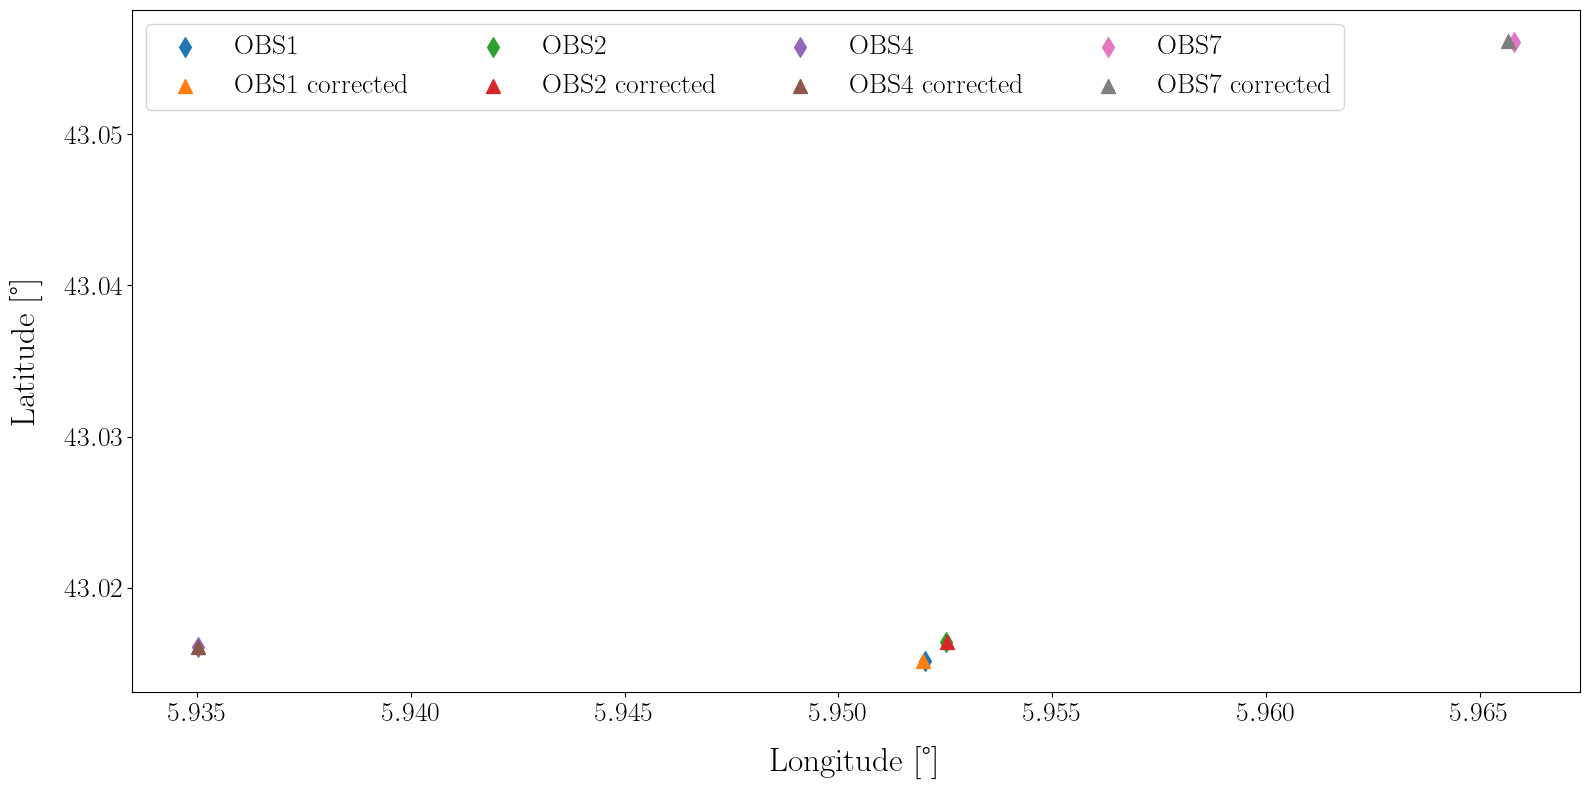

In [39]:
# Compare coords 
name = list(portion.position.children.keys())[0]
ds_pos_section = portion.position[name].to_dataset()
ds_pos_section_corr = portion_corr.position[name].to_dataset()
fig, ax = plt.subplots()

for rcv_id in obs_ids:
    # Original 
    rcv = ds_pos_section.sel(rcv_id=rcv_id)
    ax.scatter(rcv.rcv_lon, rcv.rcv_lat, marker="d", label=f"{rcv_id.upper()}", s=100)

    # Correction 
    rcv = ds_pos_section_corr.sel(rcv_id=rcv_id)
    ax.scatter(rcv.rcv_lon, rcv.rcv_lat, marker="^", label=f"{rcv_id.upper()} corrected", s=100)

ax.set_xlabel("Longitude [°]")
ax.set_ylabel("Latitude [°]")

_, labels = ax.get_legend_handles_labels()
ncols = min(len(labels), 4)
ax.legend(ncols=ncols)


# Vérification des temps d'arrivée après correction 

In [40]:
c0 = 1508       # equivalent celerity 
for name, node in portion_corr.position.children.items():
    ds_pos_section = node.to_dataset()

    # Compute corrected geodetic distance between source and receiver
    ds_pos_section = compute_src_rcv_geodesic_dist(ds_pos_sections=[ds_pos_section])[0]

    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time
    tps_propagation_s = dpropa_direct / c0 

    # Update ds_pos_section with propagation time
    ds_pos_section["tps_propagation_s"] = tps_propagation_s

    # Derive associated arrival dt
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    # Update ds_pos_section with arrival datetime
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

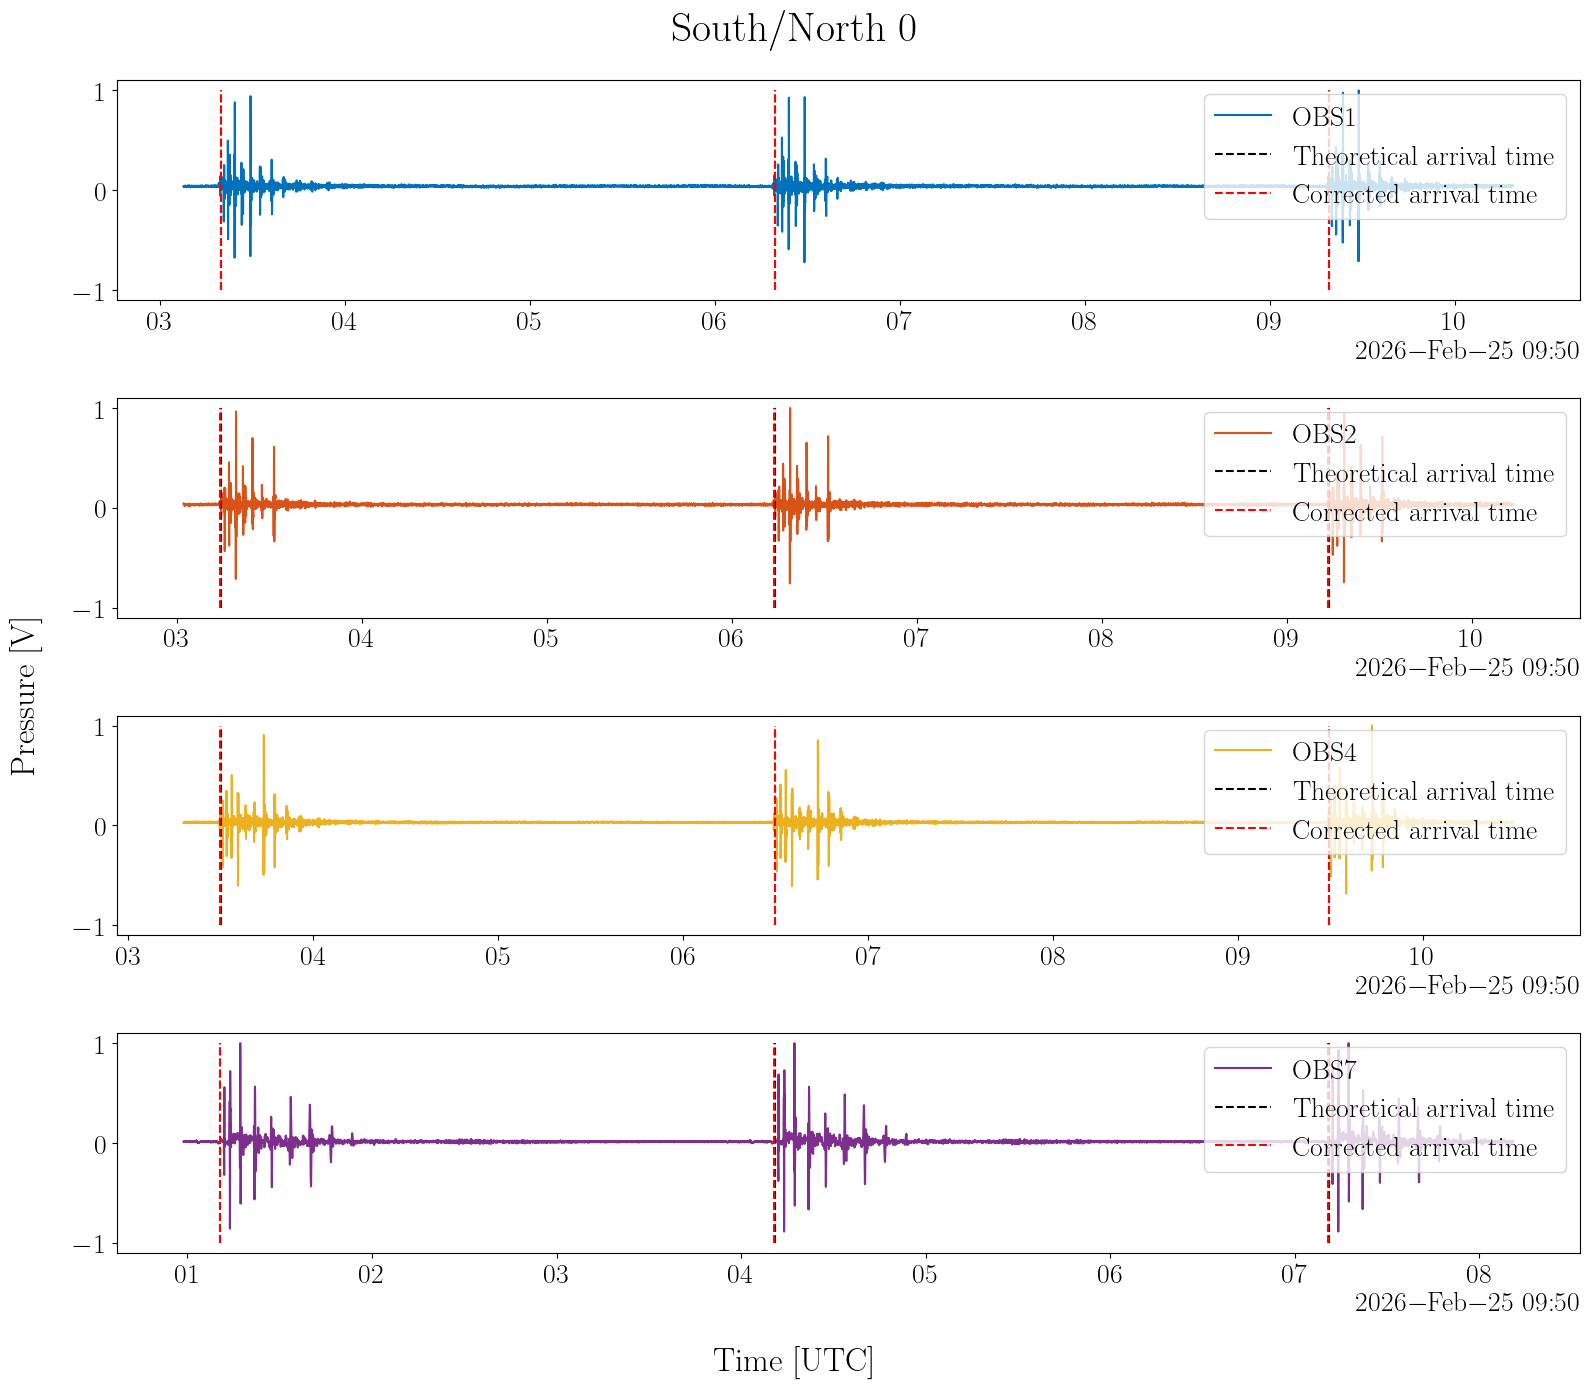

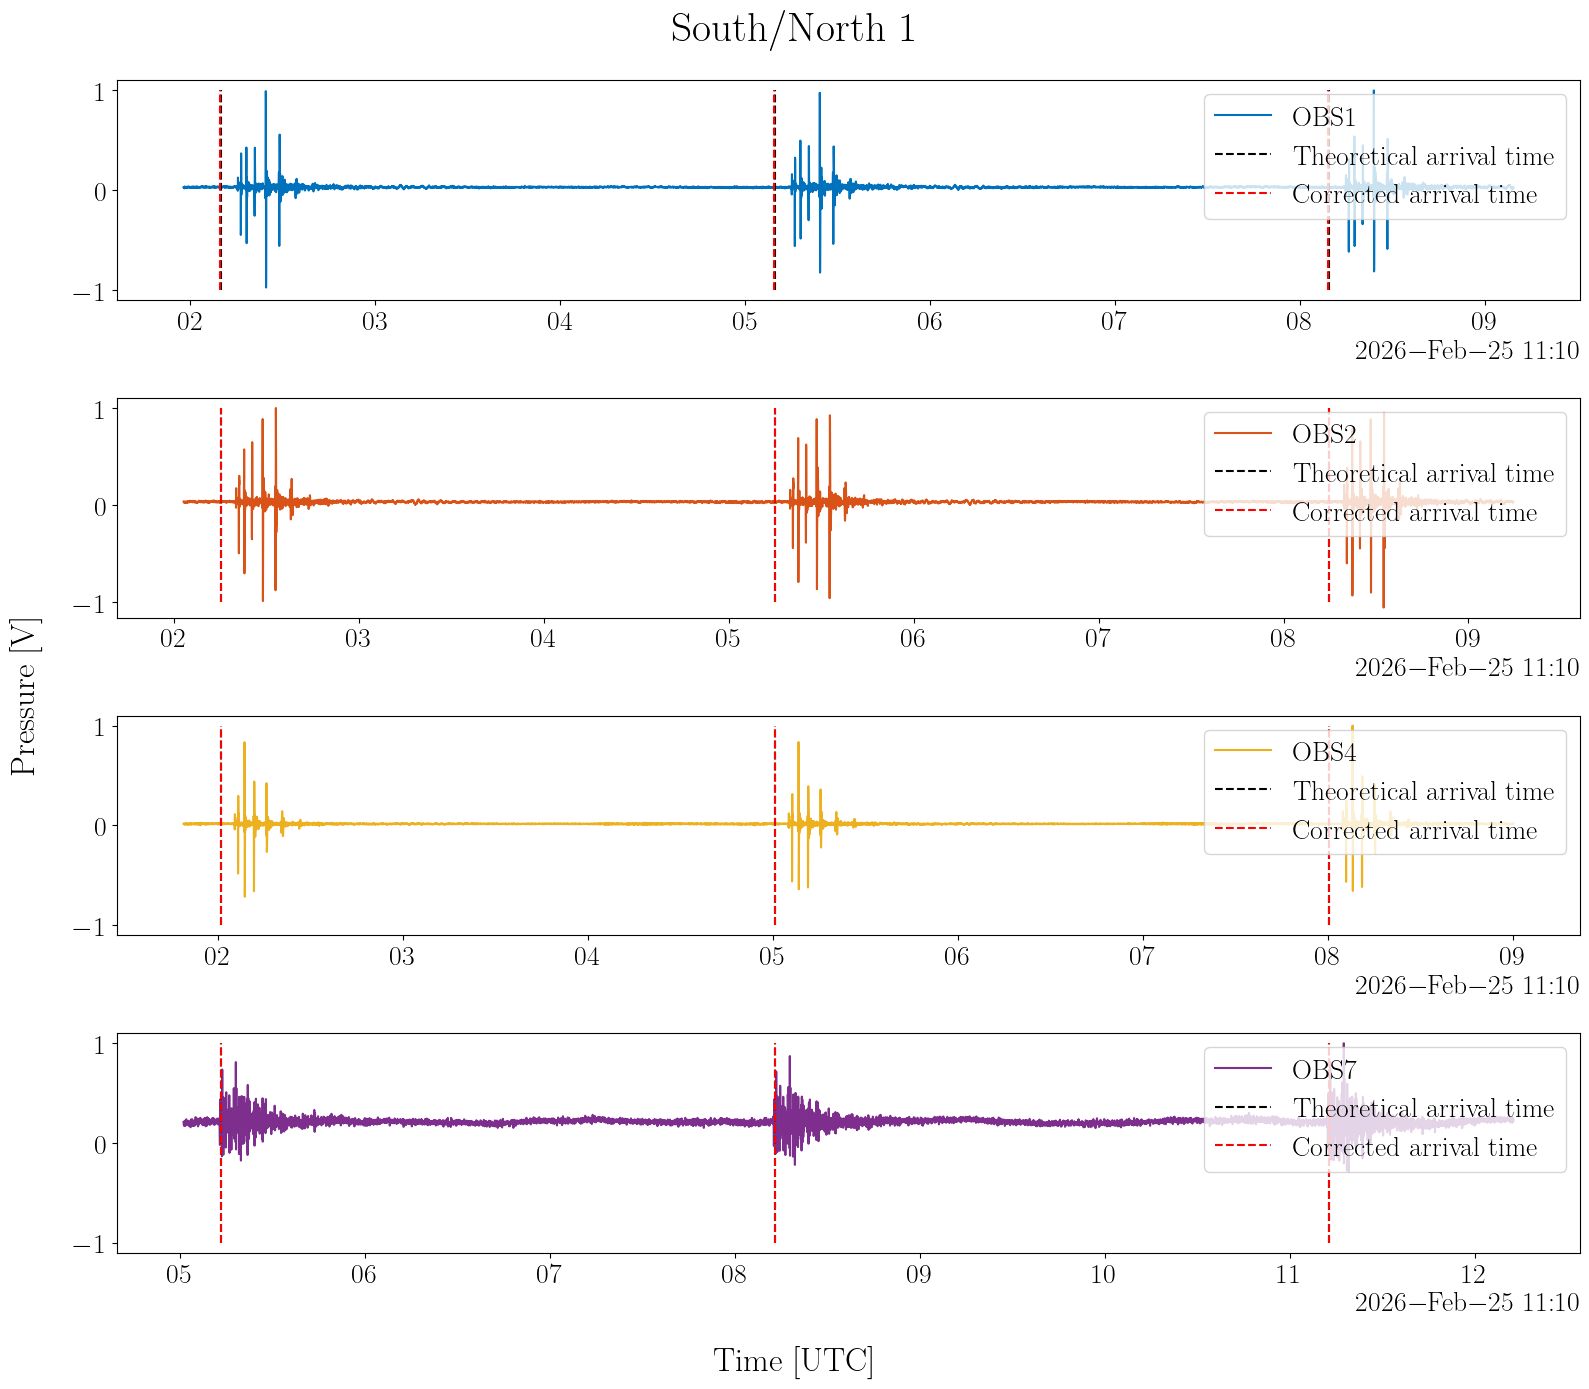

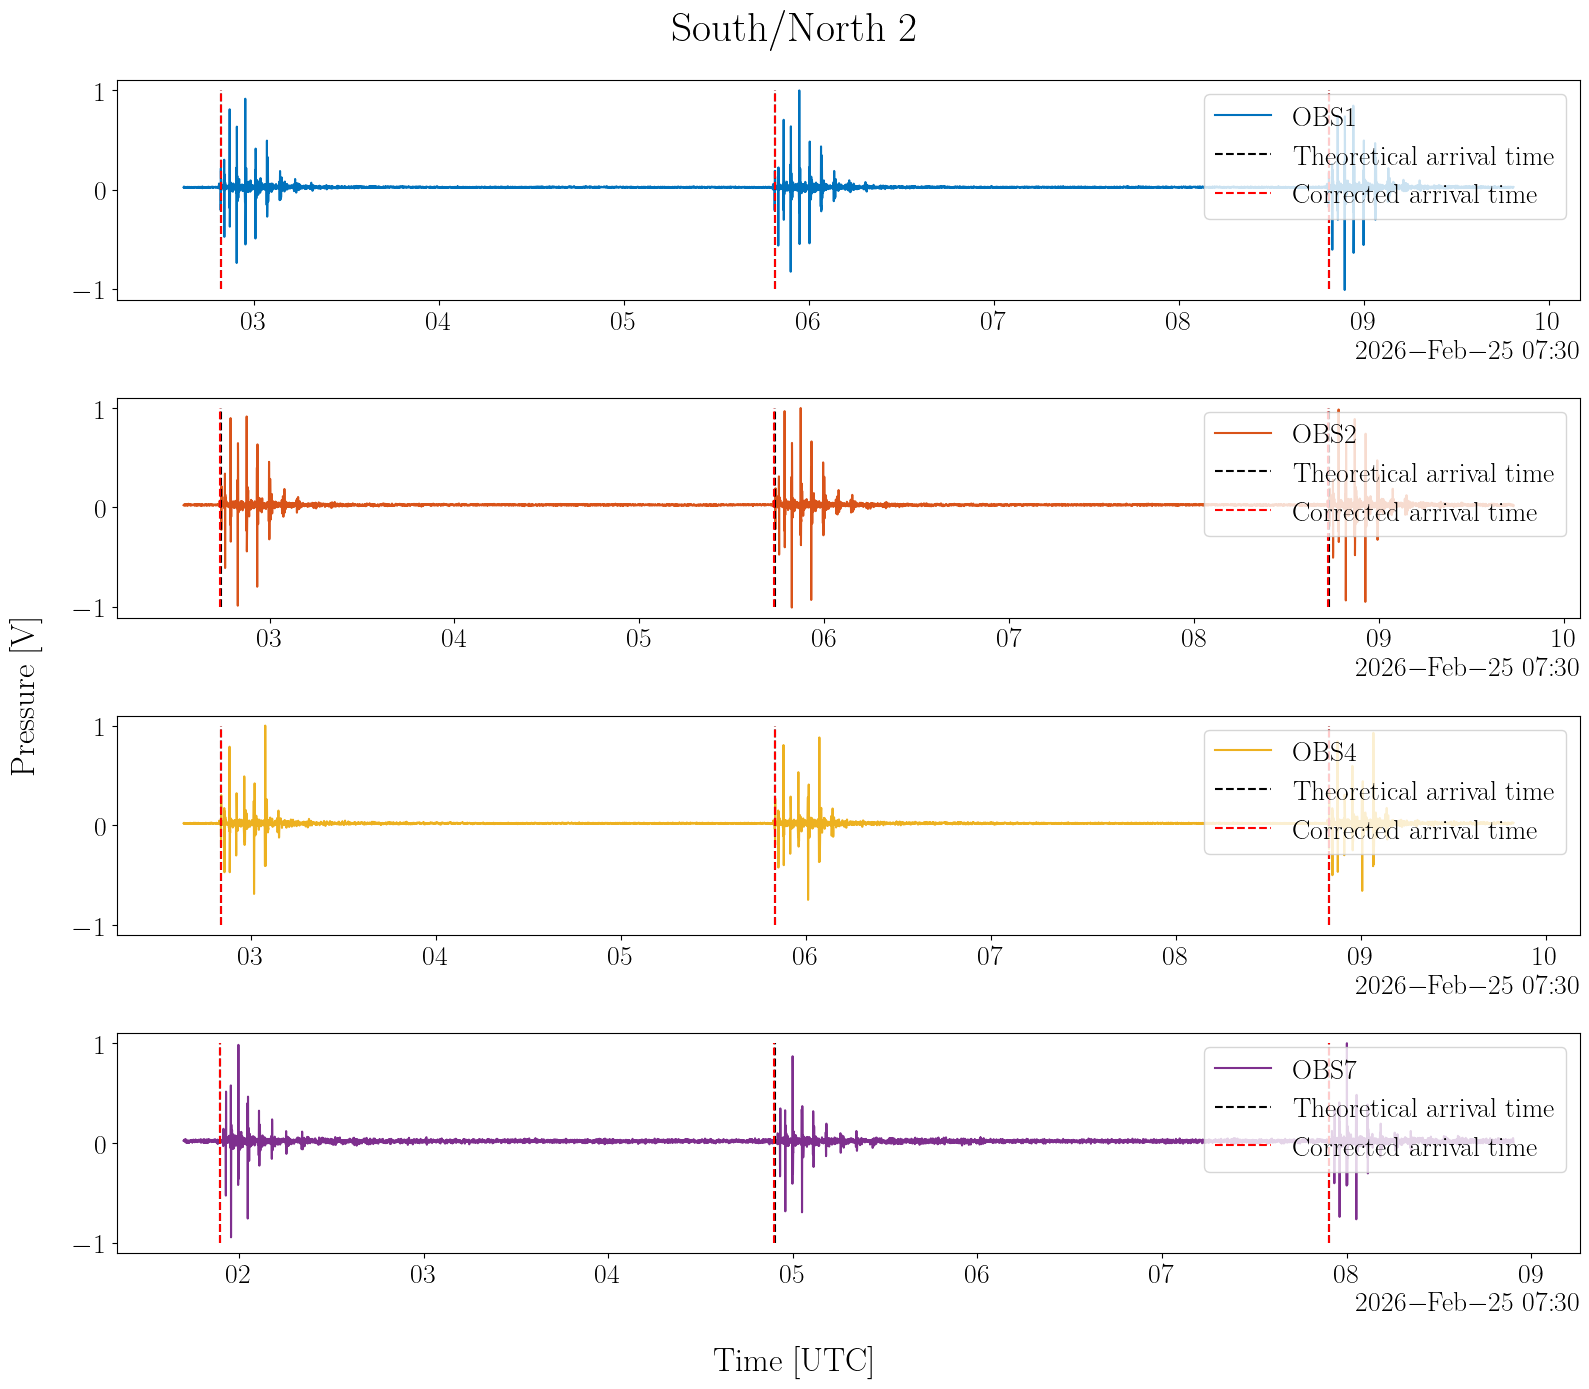

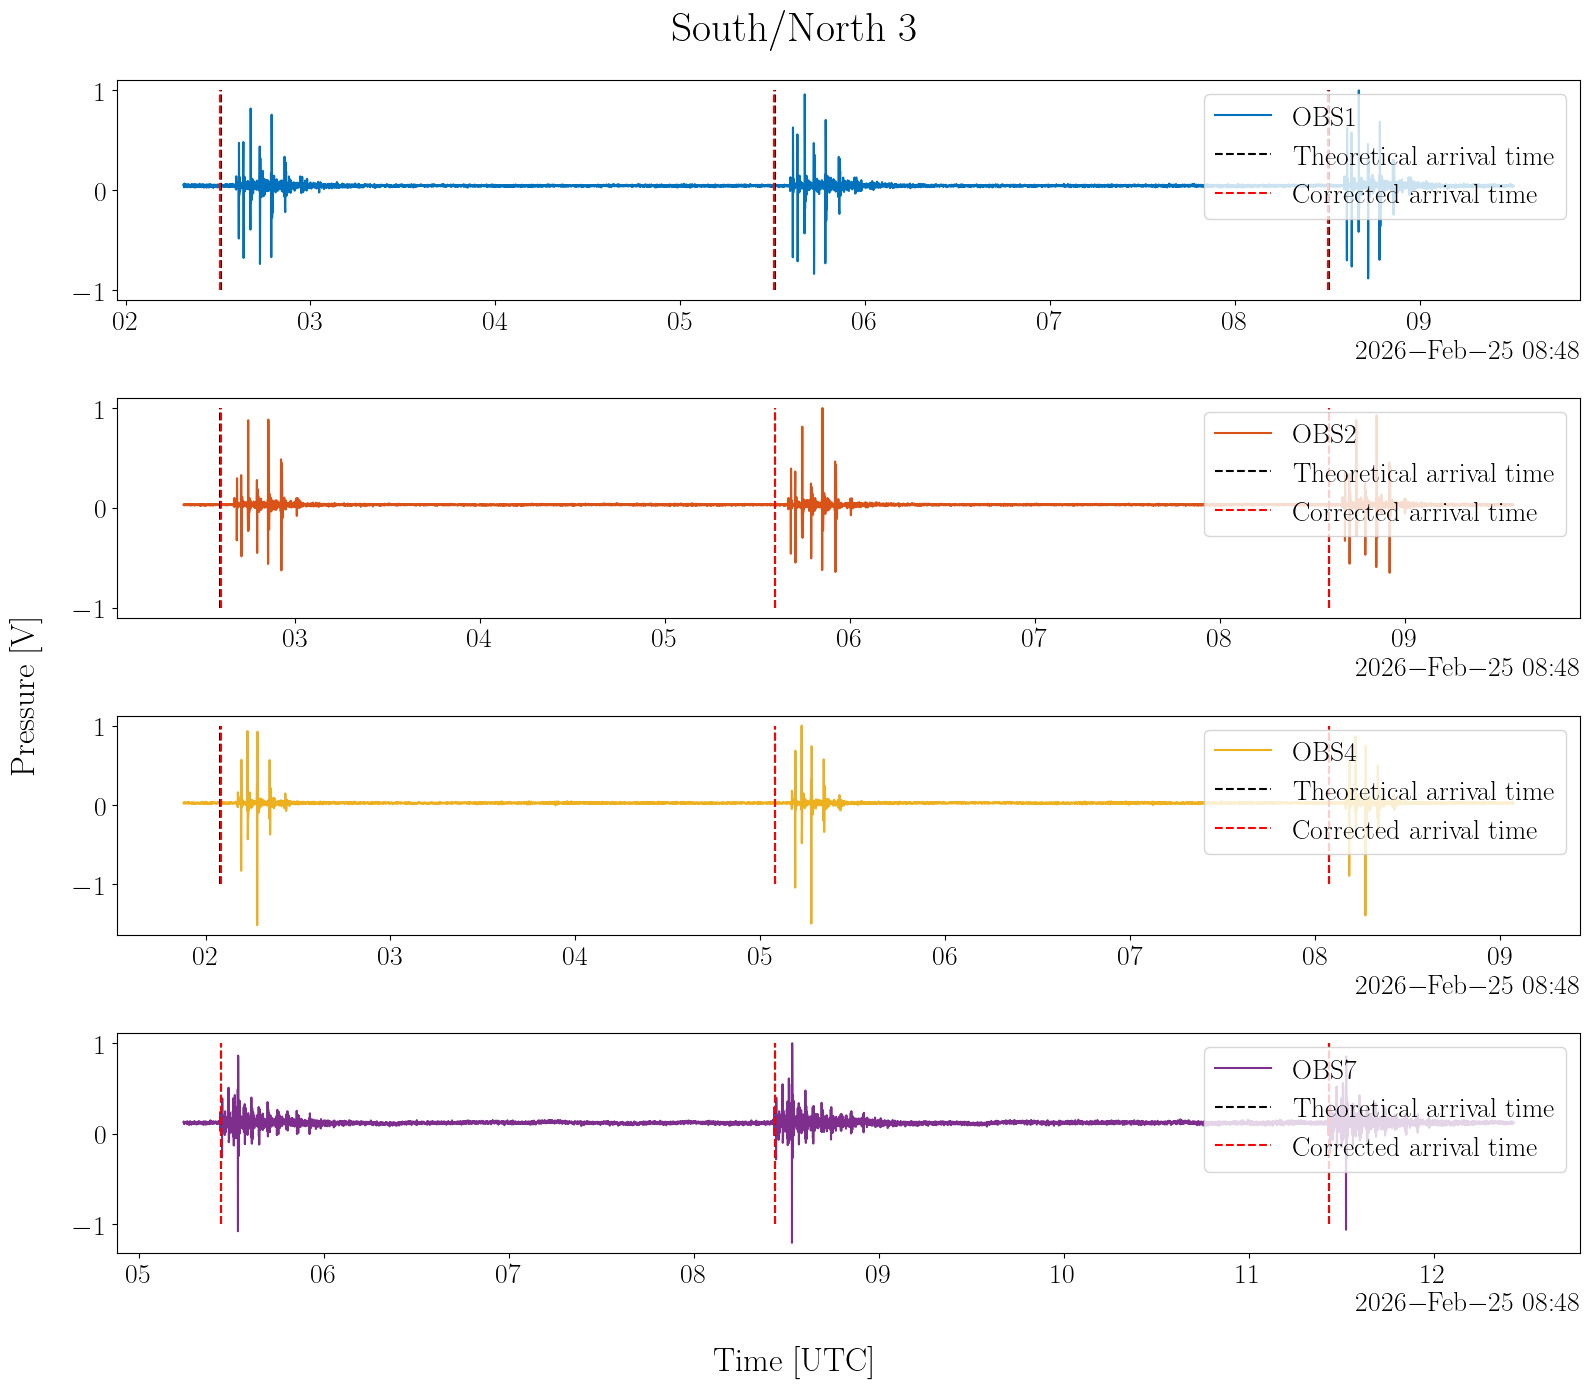

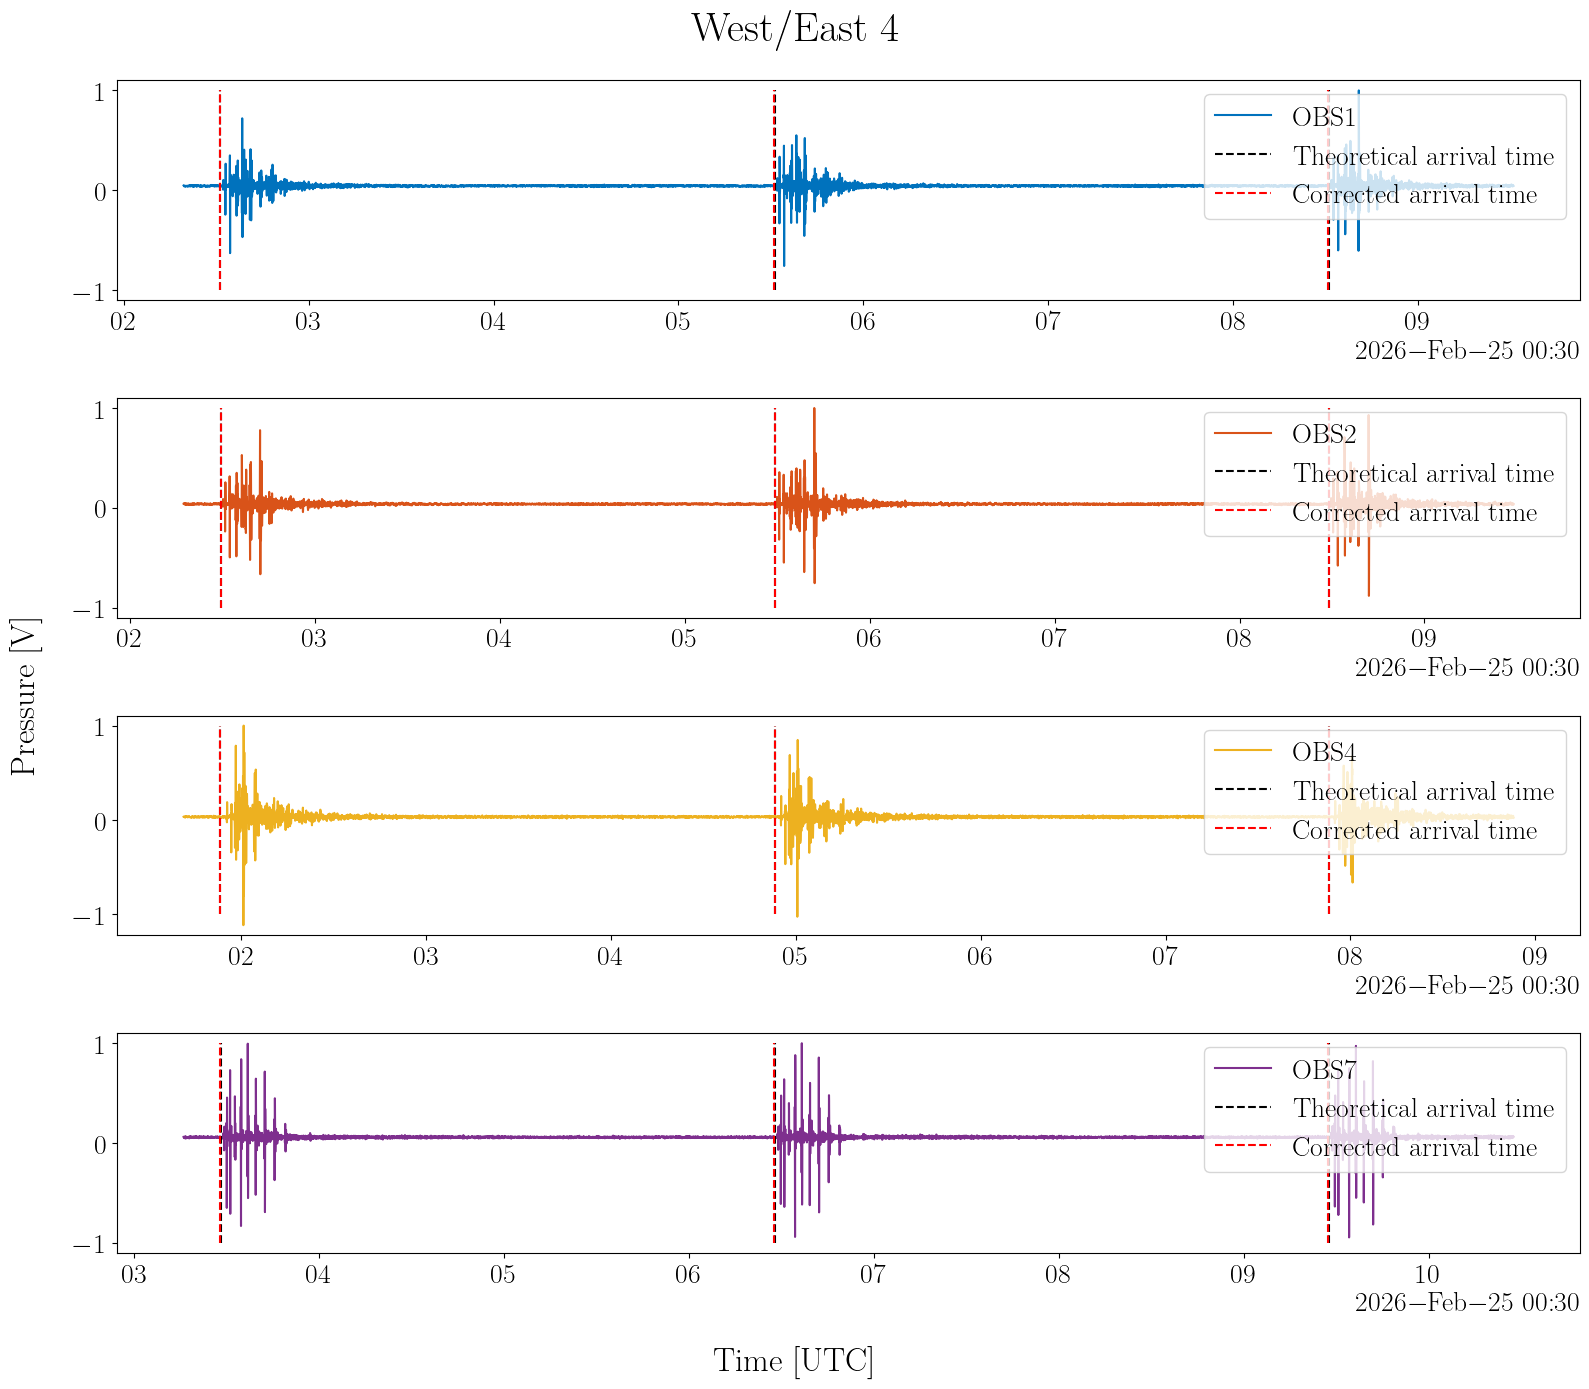

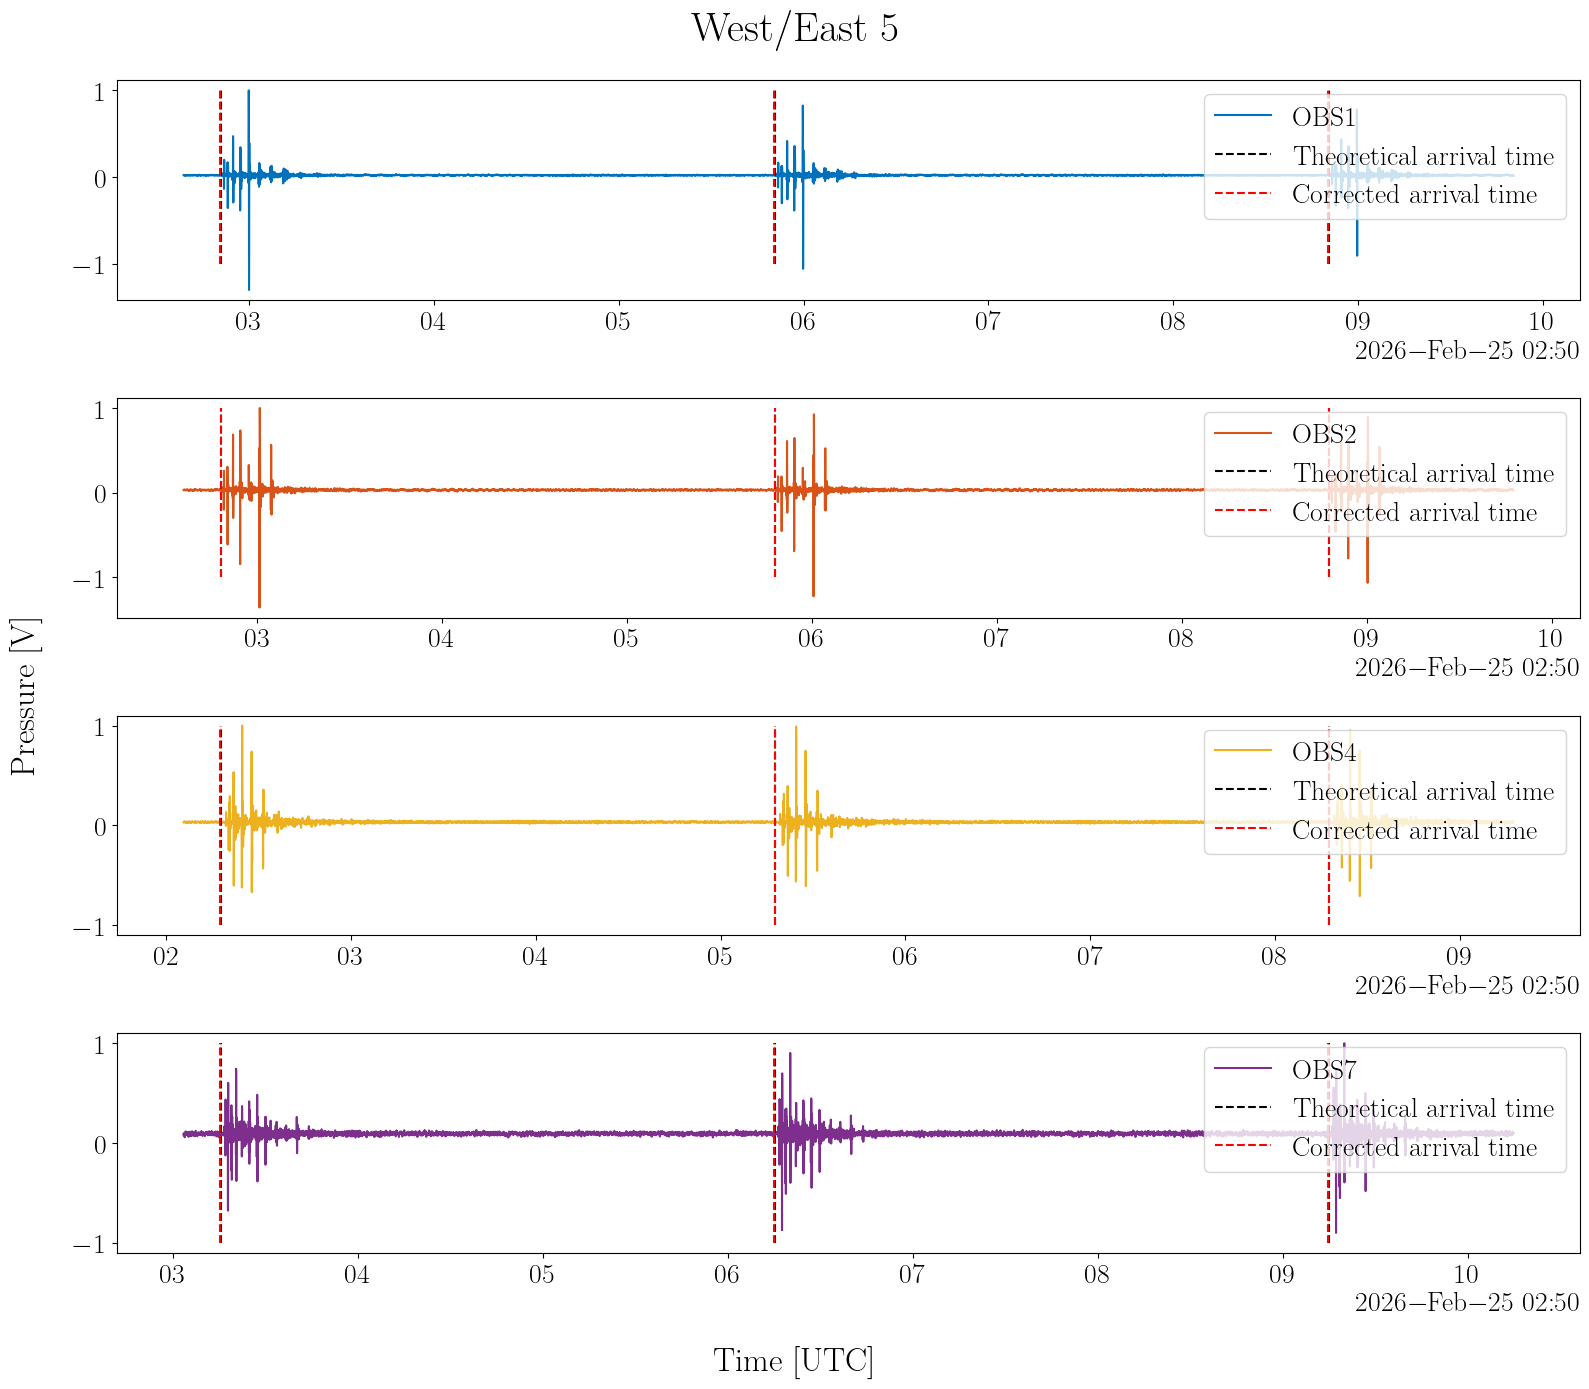

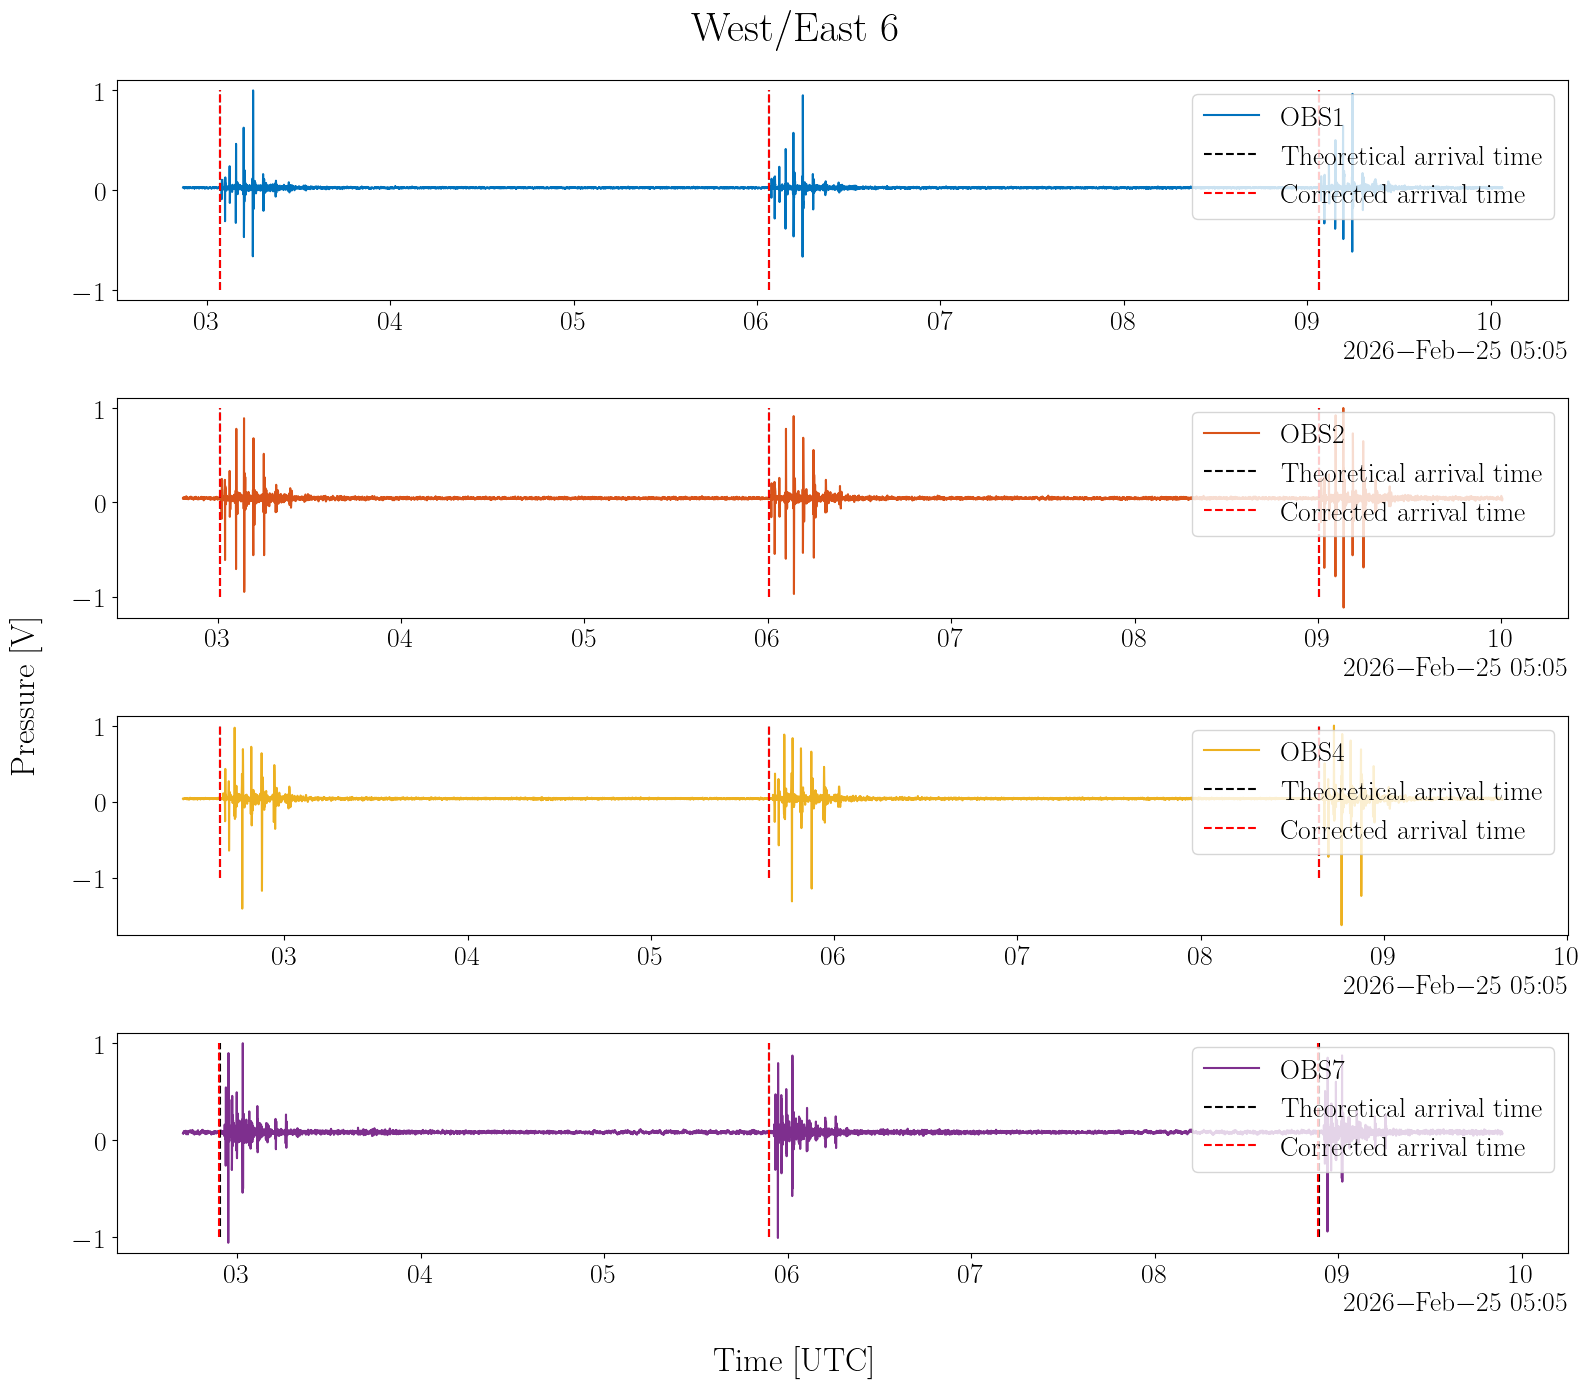

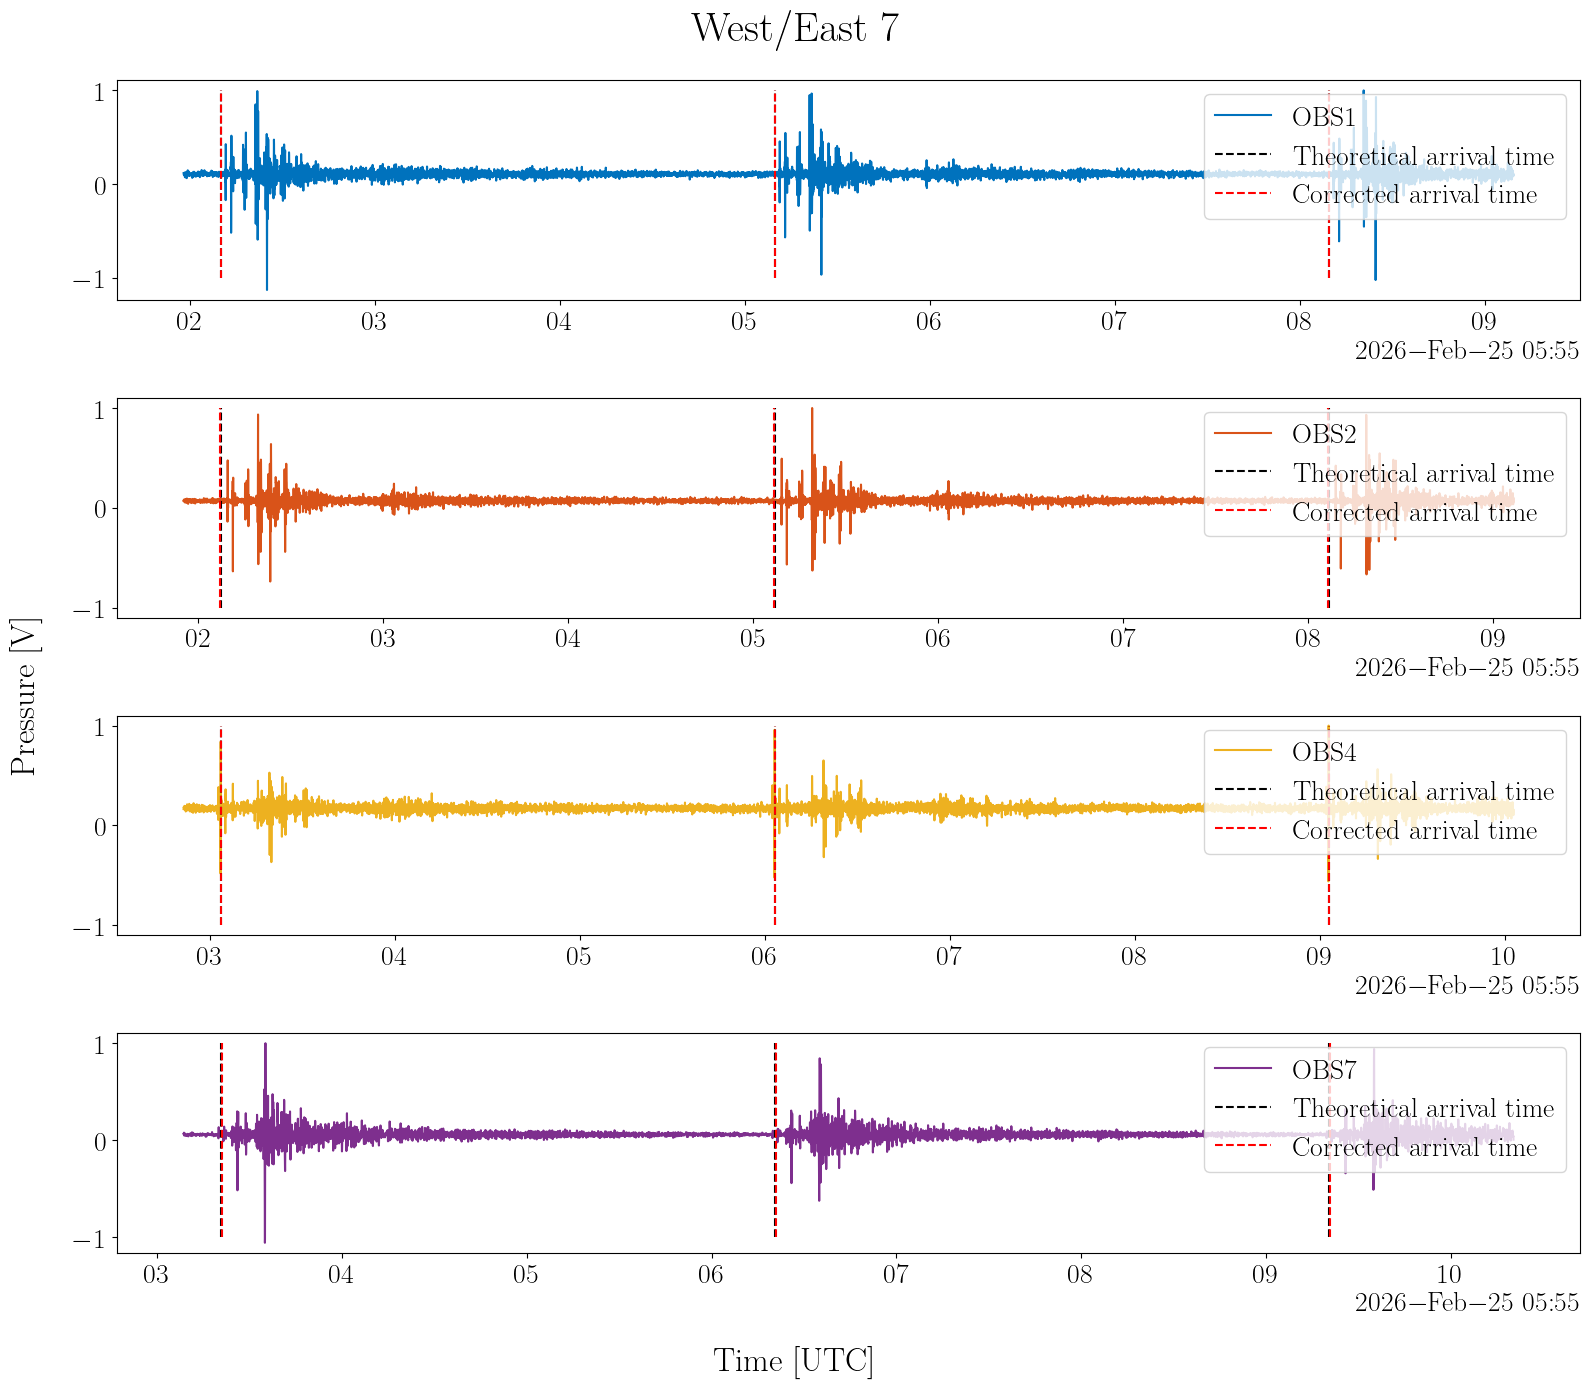

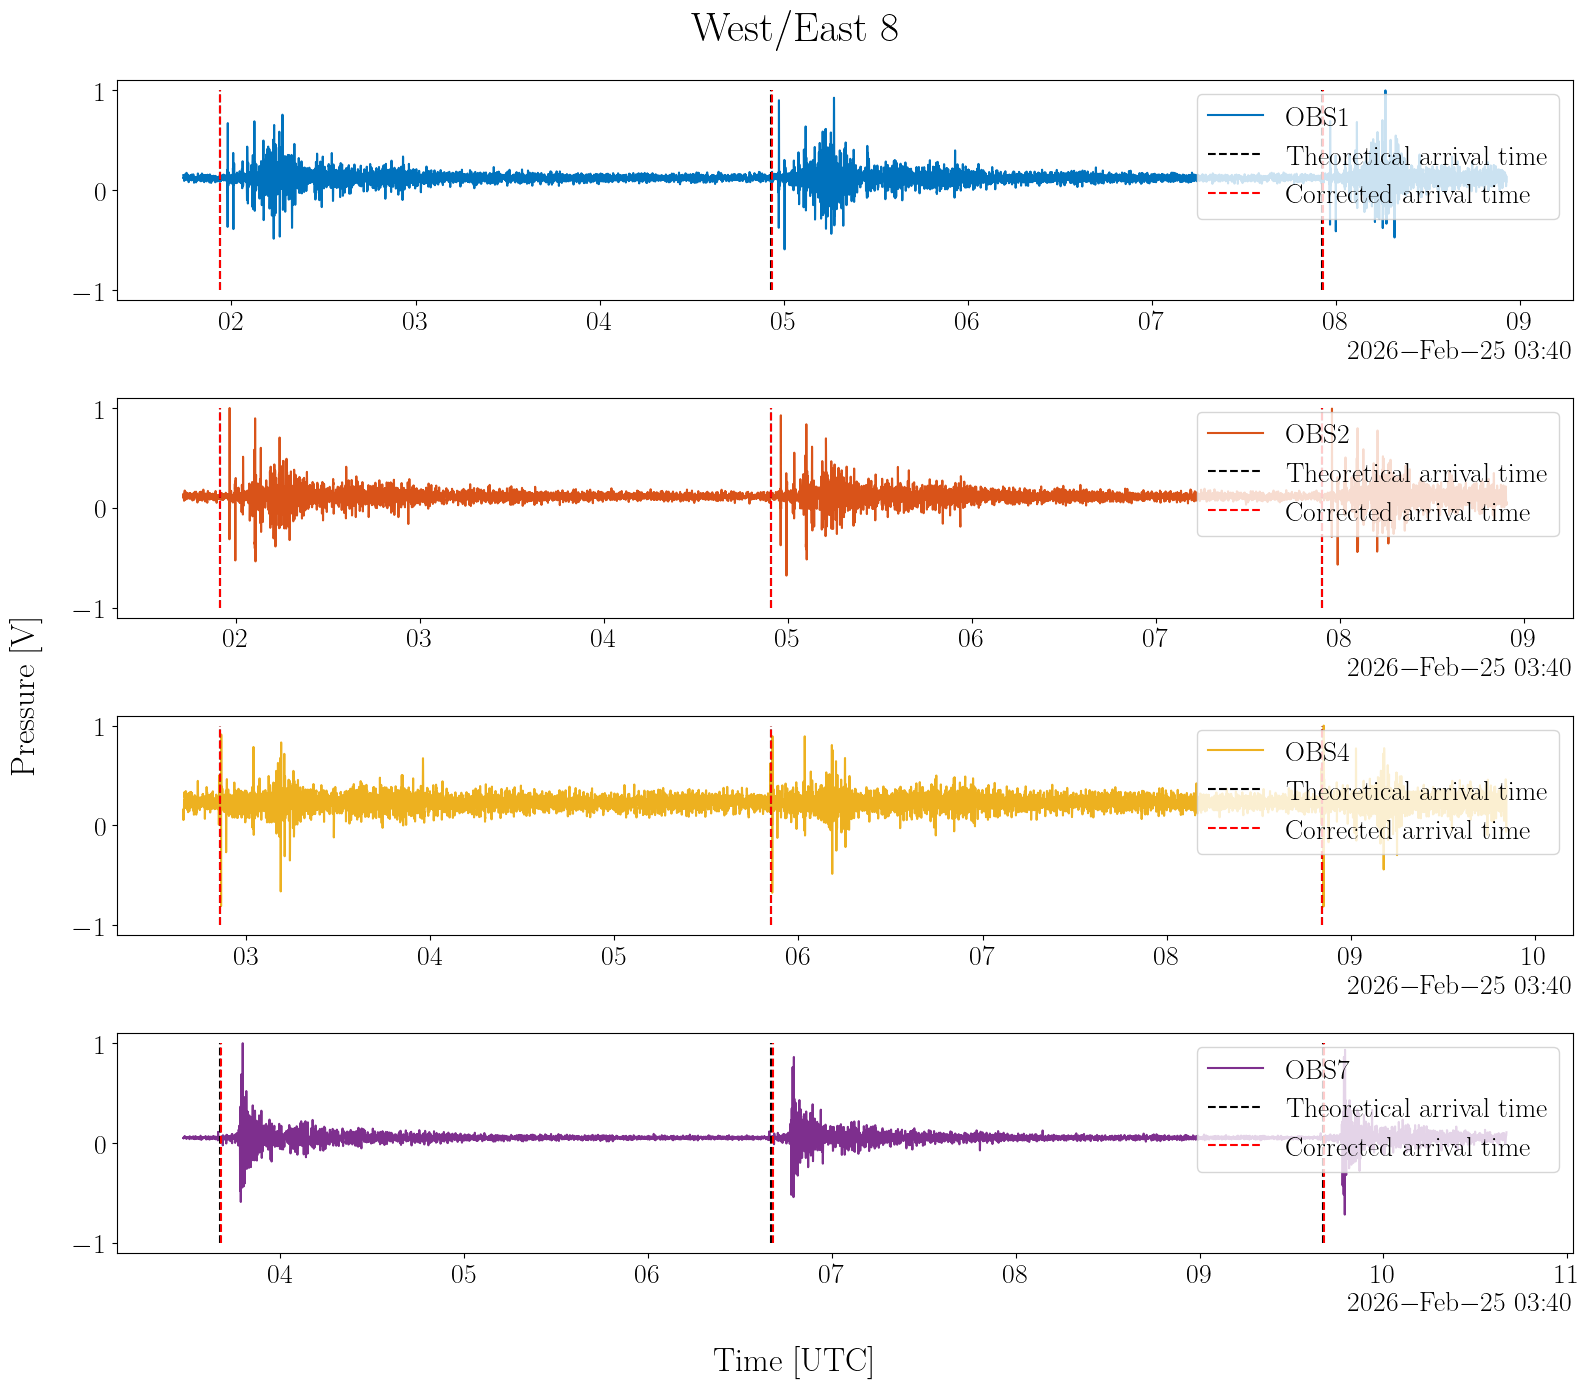

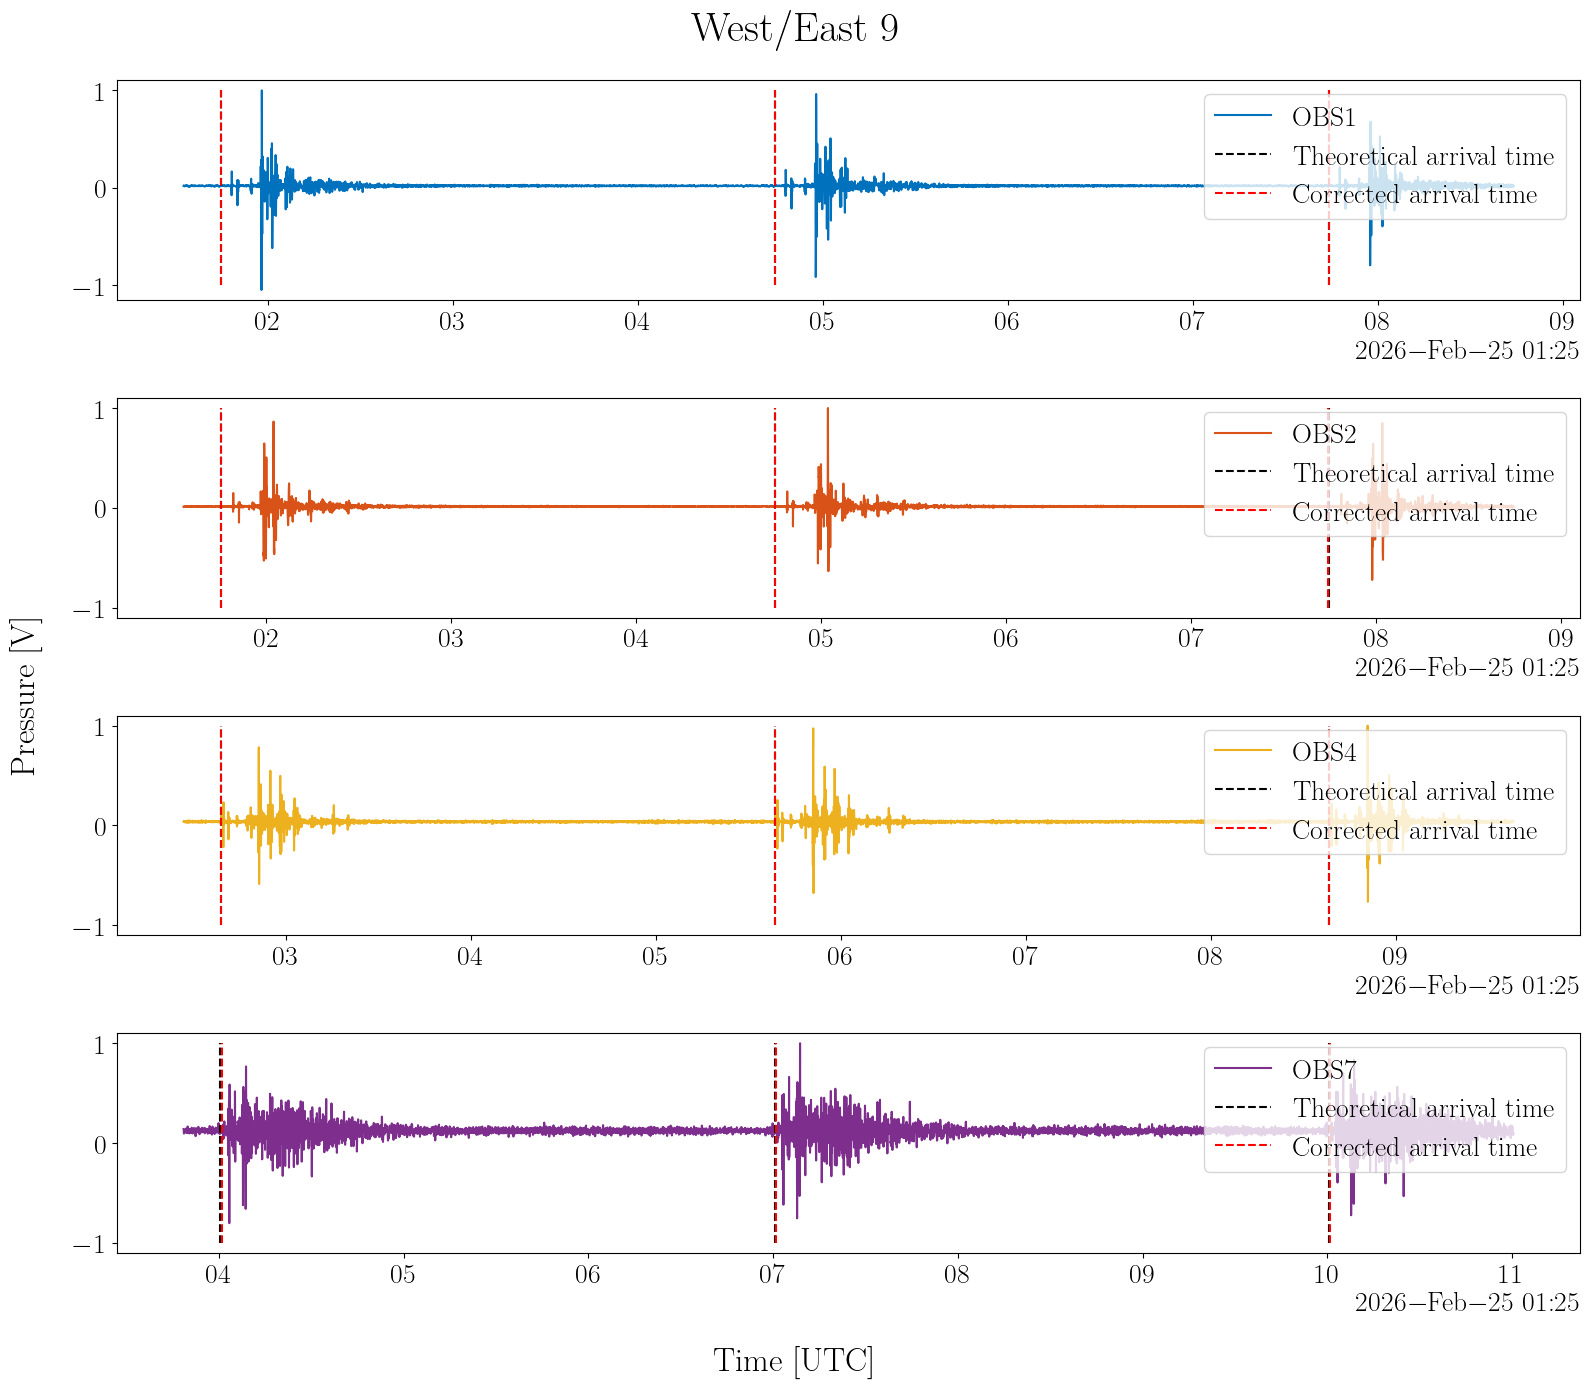

In [41]:
nb_tir = 3
offset1 = 200
offset2 = 1000

for name, node in portion.pressure.children.items():

    ds_pressure_section = node.to_dataset()  
    ds_pressure_section_corr = portion_corr.pressure[name].to_dataset()

    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))
    ds_pos_section_corr = portion_corr.position[name].to_dataset()
    tir_dt_corr = ds_pos_section_corr["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=len(obs_ids), ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        tir_dt_rcv_corr = tir_dt_corr.sel(rcv_id=rcv_id)

        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})

        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--", label="Theoretical arrival time")
        axs[i].vlines(x=tir_dt_rcv_corr, ymin=-1, ymax=1, color="r", linestyle="--", label="Corrected arrival time")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

La correction appliquée semble OK ! On est prêt à estimer les features. 